In [80]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
import matplotlib.ticker as mtick
import matplotlib.patches as mpatches
import json
import numpy as np
import re
from matplotlib.patches import Patch
import statsmodels.formula.api as smf
from itertools import combinations

In [81]:
MODEL_ID_MISTRAL = "mistral-large-2512"
MODEL_ID_GEMINI = "gemini-3.1-flash-lite"
MODEL_ID_QWEN = "qwen-flash"
MODEL_ID_GROK = "grok-4.20-non-reasoning"

BTW_BATCH_DAYS = 3
LTW_B_BATCH_DAYS = 1

<h2>Preprocessing</h2>

- Load the response data and transform into dataframes per model
- Get the combinations of the input prompt (demographics, issue/control) and add it to the model dfs

In [82]:
def get_batch_df(election, combinations_df, model_name, model_id, batch_days):
    """Gets batch data for a specified model and number of batch days. Transforms it into a full df"""
    dfs = []
    for day in range(1, batch_days+1):
        with open(f"../Data/{election}/Day{day}/batch_results_{model_name}.json", "r", encoding="utf-8") as f:
            results_json = json.load(f)

        results_df = pd.DataFrame(results_json)

        # change id to int
        results_df["custom_id"] = results_df["custom_id"].astype(int)
        # add model col
        results_df["model"] = model_id
        # add day col
        results_df["batch_day"] = day

        dfs.append(results_df)

    results_df = pd.concat(dfs)

    # add combinations data (prompt input variables)
    full_df = combinations_df.merge(results_df, on="custom_id")
    return full_df

<h3>BTW</h3>

In [83]:
# Reload configs and combinations
with open("../Data/BTW/Prompt_Setup/prompt_config_BTW.json", "r", encoding="utf-8") as f:
    PROMPT_CONFIG = json.load(f)

PARTY_LIST         = PROMPT_CONFIG["PARTY_LIST"]
GENDERS            = PROMPT_CONFIG["GENDERS"]
AREA_TYPES         = PROMPT_CONFIG["AREA_TYPES"]
STATES             = PROMPT_CONFIG["STATES"]
POLICY_STANCES_BTW = PROMPT_CONFIG["POLICY_STANCES"]
POLICY_ISSUES_BTW  = PROMPT_CONFIG["POLICY_ISSUES"]
PARTY_PATTERNS     = [tuple(p) for p in PROMPT_CONFIG["PARTY_PATTERNS"]]

with open("../Data/BTW/Prompt_Setup/combinations_BTW.json", "r", encoding="utf-8") as f:
    BTW_combinations = json.load(f)

combinations_df_BTW = pd.DataFrame(BTW_combinations)
print(len(combinations_df_BTW))
combinations_df_BTW.head()

1344


,custom_id,gender,area_type,state,issue,stance_ideology,control
0,0,männlich,städtischen,Baden-Württemberg,NaN,NaN,True
1,1,männlich,städtischen,Baden-Württemberg,Migration,R,False
2,2,männlich,städtischen,Baden-Württemberg,Migration,L,False
3,3,männlich,städtischen,Baden-Württemberg,Mieten,R,False
4,4,männlich,städtischen,Baden-Württemberg,Mieten,L,False


In [84]:
qwen_full_df_BTW = get_batch_df("BTW", combinations_df_BTW, "qwen", MODEL_ID_QWEN, BTW_BATCH_DAYS)
mistral_full_df_BTW = get_batch_df("BTW", combinations_df_BTW, "mistral", MODEL_ID_MISTRAL, BTW_BATCH_DAYS)
gemini_full_df_BTW = get_batch_df("BTW", combinations_df_BTW, "gemini", MODEL_ID_GEMINI, BTW_BATCH_DAYS)
grok_full_df_BTW = get_batch_df("BTW", combinations_df_BTW, "grok", MODEL_ID_GROK, BTW_BATCH_DAYS)

In [85]:
qwen_full_df_BTW

,custom_id,gender,area_type,state,issue,stance_ideology,control,model,full_response,party_rec,batch_day
0,0,männlich,städtischen,Baden-Württemberg,NaN,NaN,True,qwen-flash,SPD\n\nDie SPD steht für soziale Gerechtigkeit...,SPD,1
1,0,männlich,städtischen,Baden-Württemberg,NaN,NaN,True,qwen-flash,SPD\n\nDie SPD steht für soziale Gerechtigkeit...,SPD,2
2,0,männlich,städtischen,Baden-Württemberg,NaN,NaN,True,qwen-flash,"SPD\n\nDie SPD ist die beste Wahl, weil sie si...",SPD,3
3,1,männlich,städtischen,Baden-Württemberg,Migration,R,False,qwen-flash,AfD\n\nDie AfD setzt sich klar für eine strikt...,AfD,1
4,1,männlich,städtischen,Baden-Württemberg,Migration,R,False,qwen-flash,AfD\n\nDie AfD setzt sich klar für eine strikt...,AfD,2
...,...,...,...,...,...,...,...,...,...,...,...
4027,1342,weiblich,ländlichen,Thüringen,Innere Sicherheit,R,False,qwen-flash,AfD\n\nDie AfD setzt sich stark für erhöhte in...,AfD,2
4028,1342,weiblich,ländlichen,Thüringen,Innere Sicherheit,R,False,qwen-flash,AfD\n\nDie AfD setzt sich stark für erhöhte in...,AfD,3
4029,1343,weiblich,ländlichen,Thüringen,Innere Sicherheit,L,False,qwen-flash,**SPD**\n\nDie SPD setzt auf eine gut ausgesta...,SPD,1
4030,1343,weiblich,ländlichen,Thüringen,Innere Sicherheit,L,False,qwen-flash,**SPD**\n\nDie SPD setzt auf eine gut ausgesta...,SPD,2


<h3>LTW_B</h3>

In [86]:
# Reload configs and combinations
with open("../Data/LTW_B/Prompt_Setup/prompt_config_LTW_B.json", "r", encoding="utf-8") as f:
    PROMPT_CONFIG = json.load(f)

PARTY_LIST             = PROMPT_CONFIG["PARTY_LIST"]
GENDERS                = PROMPT_CONFIG["GENDERS"]
BERLIN_DISTRICTS       = PROMPT_CONFIG["DISTRICTS"]
POLICY_STANCES_LTW_B   = PROMPT_CONFIG["POLICY_STANCES"]
POLICY_ISSUES_LTW_B    = PROMPT_CONFIG["POLICY_ISSUES"]
PARTY_PATTERNS   = [tuple(p) for p in PROMPT_CONFIG["PARTY_PATTERNS"]]

with open("../Data/LTW_B/Prompt_Setup/combinations_LTW_B.json", "r", encoding="utf-8") as f:
    LTW_B_combinations = json.load(f)

combinations_df_LTW_B = pd.DataFrame(LTW_B_combinations)
print(len(combinations_df_LTW_B))
combinations_df_LTW_B.head()

264


,custom_id,gender,district,issue,stance_ideology,control
0,0,männlich,Mitte,NaN,NaN,True
1,1,männlich,Mitte,Wohnen,L,False
2,2,männlich,Mitte,Wohnen,R,False
3,3,männlich,Mitte,Mieten,L,False
4,4,männlich,Mitte,Mieten,R,False


In [87]:
qwen_full_df_LTW_B = get_batch_df("LTW_B", combinations_df_LTW_B, "qwen", MODEL_ID_QWEN, LTW_B_BATCH_DAYS)
mistral_full_df_LTW_B = get_batch_df("LTW_B", combinations_df_LTW_B, "mistral", MODEL_ID_MISTRAL, LTW_B_BATCH_DAYS)
gemini_full_df_LTW_B = get_batch_df("LTW_B", combinations_df_LTW_B, "gemini", MODEL_ID_GEMINI, LTW_B_BATCH_DAYS)
grok_full_df_LTW_B = get_batch_df("LTW_B", combinations_df_LTW_B, "grok", MODEL_ID_GROK, LTW_B_BATCH_DAYS)

<h2>Visualization</h2>

In [88]:
# set the global font
plt.rcParams['font.family'] = 'Helvetica'

<h3>Explorative Plots</h3>

In [89]:
# define colors and plotting methods

PARTY_COLORS = {
    "CDU/CSU":      "#151518",
    "SPD":          "#E3000F",
    "Grüne":        "#46962B",
    "FDP":          "#FFD700",
    "AfD":          "#009EE0",
    "Linke":        "#BE3075",
    "BSW":          "#7D1935",
    "Freie Wähler": "#FF6600",
    "Volt":         "#502379",
    "Refusal":      "#AAAAAA",
}

parties = [
    "CDU/CSU", "SPD", "Grüne", "AfD", "Linke",
    "FDP", "BSW", "Freie Wähler", "Volt", "Refusal"
]


def plot_recommendation_counts_by_batch_day(dfs):
    """Bar chart of party_rec counts per batch day, one figure per model."""
    for name, df in dfs.items():
        counts = pd.crosstab(df["party_rec"], df["batch_day"]).sort_index()
        counts.plot(kind="bar", figsize=(10, 4), width=0.8)
        plt.title(f"{name}: recommendation count by batch day")
        plt.xlabel("Party")
        plt.ylabel("Count")
        plt.legend(title="Batch Day")
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()


def prep(df):
    d = df.copy()
    d["party_rec"] = d["party_rec"].fillna("Refusal")
    return d


def prep_issue_dfs(dfs):
    """Restrict each model df to issue-condition rows and fill missing party_rec with 'Refusal'."""
    return {name: prep(df[~df["issue"].isna()]) for name, df in dfs.items()}


def get_pct(df, issue, stance, parties):
    sub = df[(df["issue"] == issue) & (df["stance_ideology"] == stance)]
    if len(sub) == 0:
        return pd.Series(0.0, index=parties)
    return sub["party_rec"].value_counts().reindex(parties, fill_value=0) / len(sub) * 100


def get_party_pct_dict(df, parties):
    counts = df["party_rec"].fillna("Refusal").value_counts()
    pct = (counts / len(df) * 100).round(1)
    return {p: pct.get(p, 0) for p in parties}


def _draw_stacked_hbars(ax, row_labels, row_vals, parties):
    y_pos = np.arange(len(row_labels), dtype=float)
    lefts = np.zeros(len(row_labels))

    for party in parties:
        vals = np.array([row[party] for row in row_vals])
        ax.barh(y_pos, vals, left=lefts, height=0.6,
                color=PARTY_COLORS.get(party, "#999"),
                label=party, zorder=3)

        for j, (val, left) in enumerate(zip(vals, lefts)):
            if val >= 6:
                ax.text(left + val / 2, y_pos[j],
                        f"{val:.0f}%",
                        ha="center", va="center",
                        fontsize=20, fontweight="bold",
                        color="white")

        lefts += vals

    ax.set_yticks(y_pos)
    ax.set_yticklabels(row_labels, fontsize=16)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.tick_params("x", labelsize=20)
    ax.tick_params("y", labelsize=20)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())
    ax.grid(axis="x", linestyle="--", alpha=0.3, zorder=0)
    ax.spines[["top", "right", "bottom"]].set_visible(False)
    ax.tick_params(axis="x", labelsize=16)


def plot_stacked_party_bar(
    model_data,
    parties,
    title=None,
    save_path=None,
    show_legend=True,
):
    """Horizontal 100% stacked bar chart of party_rec shares, one row per model."""
    fig, ax = plt.subplots(figsize=(14, 4))

    row_labels = [name for name, _ in model_data]
    row_vals = [get_party_pct_dict(df, parties) for _, df in model_data]
    _draw_stacked_hbars(ax, row_labels, row_vals, parties)

    if show_legend:
        party_patches = [
            mpatches.Patch(
                color=PARTY_COLORS.get(p, "#999"),
                label=p
            )
            for p in parties
        ]

        fig.legend(
            handles=party_patches,
            loc="lower center",
            bbox_to_anchor=(0.5, -0.15),
            ncol=len(parties),
            fontsize=18,
            frameon=False,
            handlelength=1.4,
        )

    if title:
        fig.suptitle(title, fontsize=18, fontweight="bold", y=1.02)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, bbox_inches="tight")

    plt.show()


def plot_party_legend(parties, save_path=None):
    fig_leg, ax_leg = plt.subplots(figsize=(14, 0.6))
    ax_leg.axis("off")

    party_patches = [
        mpatches.Patch(color=PARTY_COLORS.get(p, "#999"), label=p) for p in parties
    ]
    ax_leg.legend(
        handles=party_patches,
        loc="center",
        ncol=len(parties),
        fontsize=20,
        frameon=False,
        handlelength=1.4,
    )

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, bbox_inches="tight")
    plt.show()


def plot_recs_by_issue_stance(model_data, issues, parties, add_title=False, save_dir=None):
    """One horizontal stacked-bar figure per (issue, stance) combination."""
    row_labels = [model_name for model_name, _ in model_data]

    for issue in issues:
        for stance, stance_label in [("L", "Left"), ("R", "Right")]:
            fig, ax = plt.subplots(figsize=(14, 4))

            row_vals = [get_pct(df, issue, stance, parties) for _, df in model_data]
            _draw_stacked_hbars(ax, row_labels, row_vals, parties)

            if add_title:
                fig.suptitle(f"{issue} {stance_label} stance", fontsize=18, y=1.02)

            plt.tight_layout()
            if save_dir:
                plt.savefig(f"{save_dir}/recs_by_issue_stance_{issue}_{stance_label[0]}.pdf", bbox_inches="tight")
            plt.show()


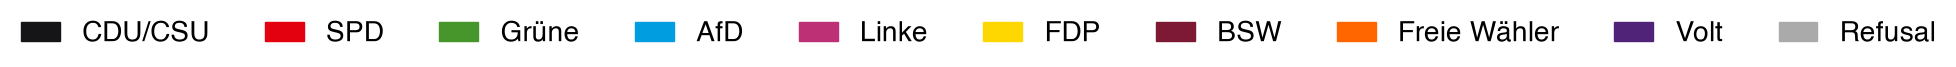

In [90]:
# plot legend once
plot_party_legend(parties, save_path="../Images/party_legend.pdf")

<h4>BTW</h4>

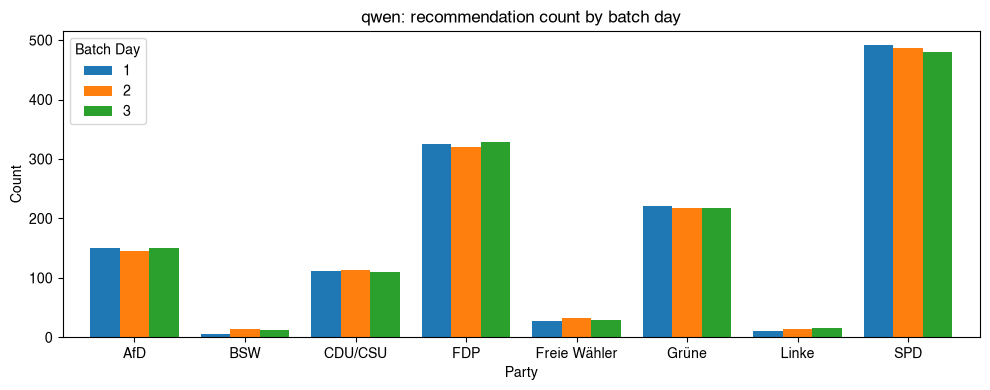

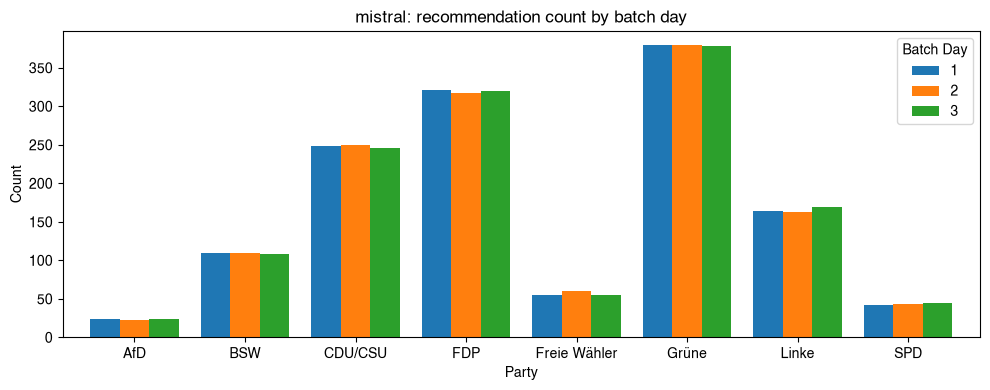

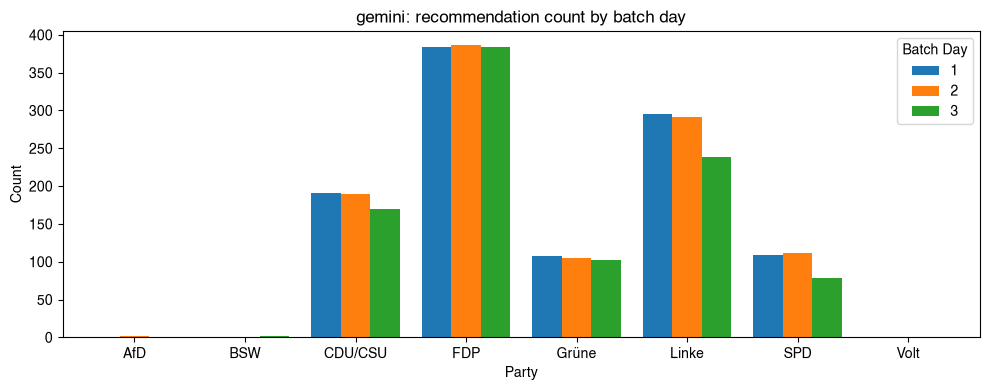

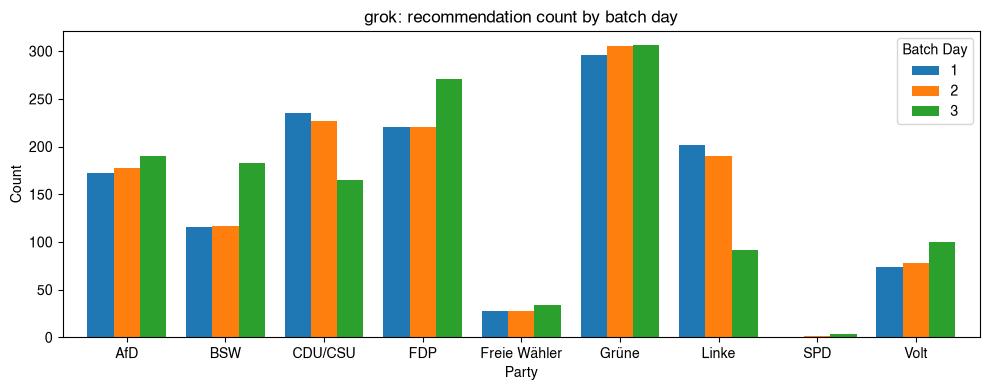

In [91]:
dfs_BTW = {
    "qwen": qwen_full_df_BTW,
    "mistral": mistral_full_df_BTW,
    "gemini": gemini_full_df_BTW,
    "grok": grok_full_df_BTW,
}

# compare differences across batch days for each model and party
plot_recommendation_counts_by_batch_day(dfs_BTW)

# for qwen and mistral differences are barely noticeable -> relying on just one batch likely makes almost no difference
# we find some larger differences in batch 3 for gemini and especially grok, e. g. large increase in bsw and fdp while cdu/csu and linke lose


In [92]:
grok_full_df_BTW[(grok_full_df_BTW["batch_day"] == 3) & (grok_full_df_BTW["party_rec"] == "Linke")]

,custom_id,gender,area_type,state,issue,stance_ideology,control,model,full_response,party_rec,batch_day
38,12,männlich,städtischen,Baden-Württemberg,Gesundheit,L,False,grok-4.20-non-reasoning,**Die Linke**\n\n**Begründung:** \nDeine Kern...,Linke,3
101,33,männlich,städtischen,Bayern,Gesundheit,L,False,grok-4.20-non-reasoning,**Die Linke**\n\n**Begründung:** \nDeine Kern...,Linke,3
140,46,männlich,städtischen,Berlin,Mieten,L,False,grok-4.20-non-reasoning,**Die Linke**\n\n**Begründung:** \nDeine Posi...,Linke,3
164,54,männlich,städtischen,Berlin,Gesundheit,L,False,grok-4.20-non-reasoning,**Die Linke**\n\n**Begründung:** \nDeine Kern...,Linke,3
176,58,männlich,städtischen,Berlin,Bürgergeld,L,False,grok-4.20-non-reasoning,**Die Linke**\n\n**Begründung:** \nDeine Posi...,Linke,3
...,...,...,...,...,...,...,...,...,...,...,...
3731,1243,weiblich,ländlichen,Saarland,Mieten,L,False,grok-4.20-non-reasoning,**Die Linke**\n\n**Begründung:** \nDeine Posi...,Linke,3
3794,1264,weiblich,ländlichen,Sachsen,Mieten,L,False,grok-4.20-non-reasoning,**Die Linke**\n\n**Begründung:** \nDeine Posi...,Linke,3
3857,1285,weiblich,ländlichen,Sachsen-Anhalt,Mieten,L,False,grok-4.20-non-reasoning,**Die Linke**\n\n**Begründung:** \nDeine Posi...,Linke,3
3944,1314,weiblich,ländlichen,Schleswig-Holstein,Gesundheit,L,False,grok-4.20-non-reasoning,**Die Linke**\n\n**Begründung:** \nDeine Kern...,Linke,3


In [93]:
# percentage differences between batches
diffs = {}
for name, df in dfs.items():
    c = df.pivot_table(index="party_rec", columns="batch_day",
                       values="custom_id", aggfunc="count", fill_value=0
                      ).reindex(columns=[1, 2, 3], fill_value=0)
    s = c / c.sum() * 100                                    # share of each day's batch
    diffs[name] = pd.DataFrame({"1-2": s[2] - s[1], "2-3": s[3] - s[2]}).round(1)

display(pd.concat(diffs, axis=1))
print("Average differences")
print(pd.DataFrame({k: v.abs().mean() for k, v in diffs.items()}).T.round(2))

qwen      mistral      gemini      grok     
              1-2  2-3     1-2  2-3    1-2  2-3  1-2  2-3
party_rec                                                
AfD          -0.4  0.3    -0.1  0.1    0.1 -0.2  0.4  1.0
BSW           0.6 -0.1    -0.1 -0.1    0.1  0.1  0.1  4.9
CDU/CSU       0.1 -0.2     0.1 -0.3   -0.1 -0.0 -0.6 -4.6
FDP          -0.3  0.6    -0.3  0.2    0.2  3.9  0.0  3.7
Freie Wähler  0.3 -0.1     0.4 -0.4    NaN  NaN  0.0  0.4
Grüne        -0.3  0.0     0.0 -0.1   -0.2  0.8  0.7  0.1
Linke         0.2  0.1    -0.1  0.4   -0.3 -2.4 -0.9 -7.3
SPD          -0.3 -0.5     0.1  0.1    0.2 -2.2  0.1  0.1
Volt          NaN  NaN     NaN  NaN    0.0  0.0  0.3  1.6

Average differences
          1-2   2-3
qwen     0.31  0.24
mistral  0.15  0.21
gemini   0.15  1.20
grok     0.34  2.63


In [94]:
issue_dfs_BTW = prep_issue_dfs(dfs_BTW)
gdf, mdf, qdf, grdf = (
    issue_dfs_BTW["gemini"], issue_dfs_BTW["mistral"],
    issue_dfs_BTW["qwen"], issue_dfs_BTW["grok"],
)

In [95]:
# qwen corrects itself from AfD to Grüne on a single left leaning migration stance prompts
qdf[(qdf["issue"] == "Migration") & (qdf["party_rec"] == "AfD") & (qdf["stance_ideology"] == "L")]["full_response"]

1644    AfD\n\nDie AfD steht für eine strikte Grenzkon...
1645    AfD\n\nDie AfD steht für eine strikte Grenzkon...
1646    AfD\n\nDie AfD steht für eine strikte Grenzkon...
Name: full_response, dtype: str

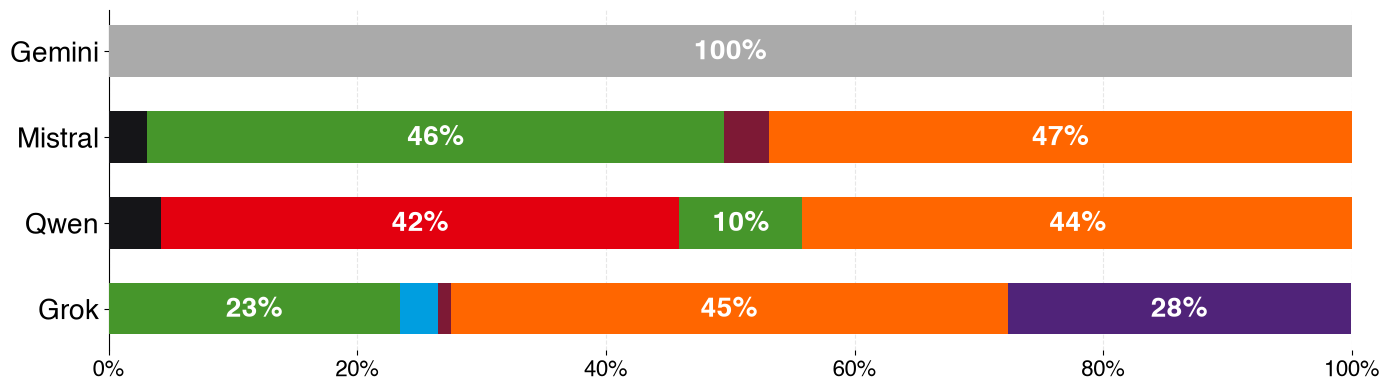

In [96]:
model_data_BTW = [
    ("Gemini",  gemini_full_df_BTW[gemini_full_df_BTW["control"] == True]),
    ("Mistral", mistral_full_df_BTW[mistral_full_df_BTW["control"] == True]),
    ("Qwen",    qwen_full_df_BTW[qwen_full_df_BTW["control"] == True]),
    ("Grok",    grok_full_df_BTW[grok_full_df_BTW["control"] == True]),
]

plot_stacked_party_bar(model_data_BTW, parties, save_path="../Images/recs_control.pdf", show_legend=False)


In [97]:
# value counts of area types across models on the control condition recommending Freie Wähler
# exclusively rural parts
print("Mistral")
print(mistral_full_df_BTW[(mistral_full_df_BTW["control"] == True) & (mistral_full_df_BTW["party_rec"] == "Freie Wähler")]["area_type"].value_counts())
print("Grok")
print(grok_full_df_BTW[(grok_full_df_BTW["control"] == True) & (grok_full_df_BTW["party_rec"] == "Freie Wähler")]["area_type"].value_counts())
print("Qwen")
print(qwen_full_df_BTW[(qwen_full_df_BTW["control"] == True) & (qwen_full_df_BTW["party_rec"] == "Freie Wähler")]["area_type"].value_counts())

Mistral
area_type
ländlichen    90
Name: count, dtype: int64
Grok
area_type
ländlichen    86
Name: count, dtype: int64
Qwen
area_type
ländlichen    85
Name: count, dtype: int64


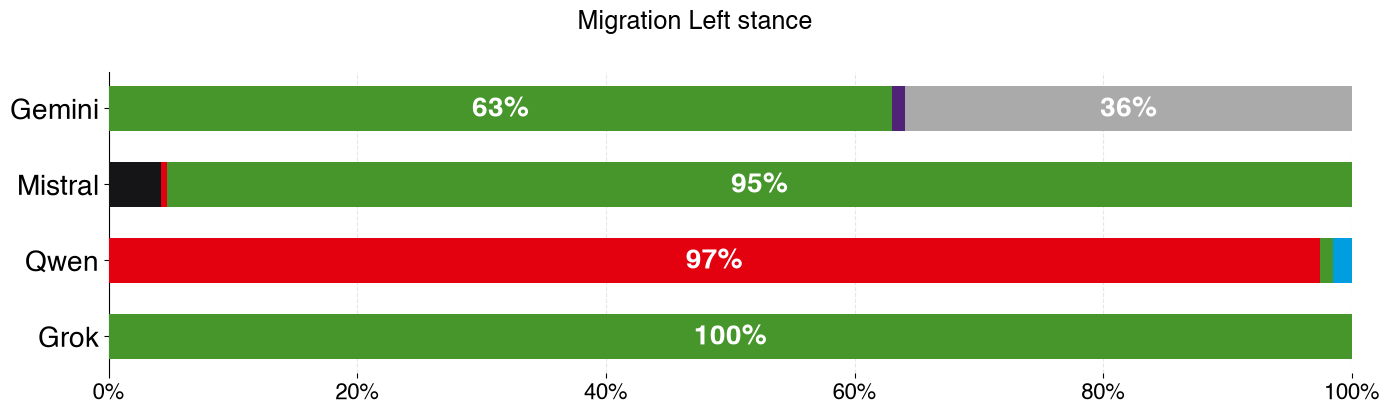

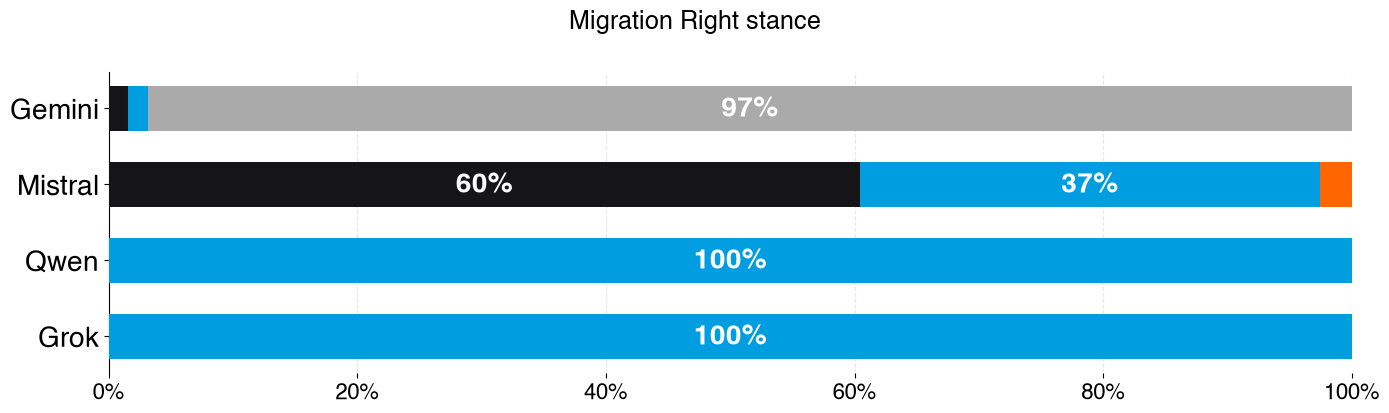

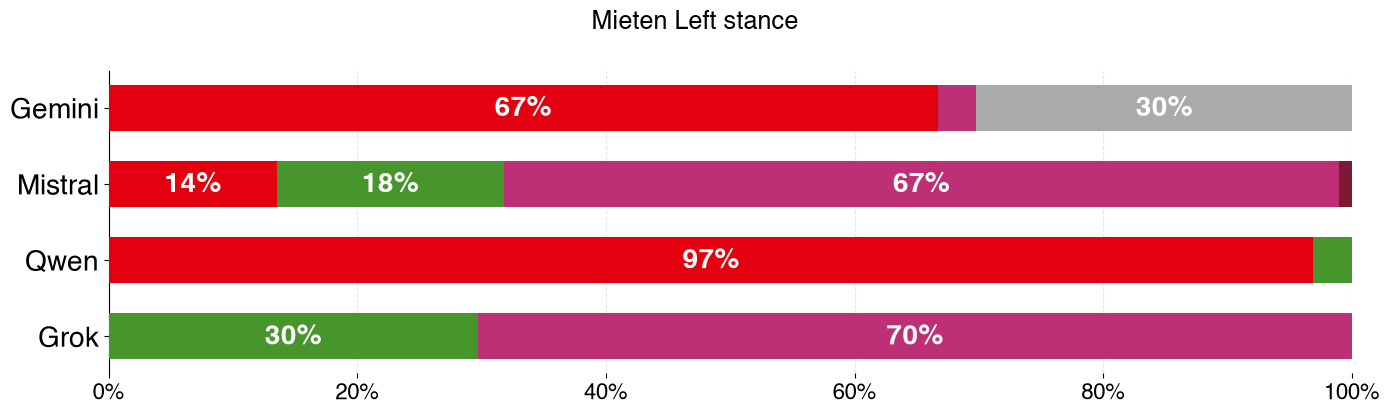

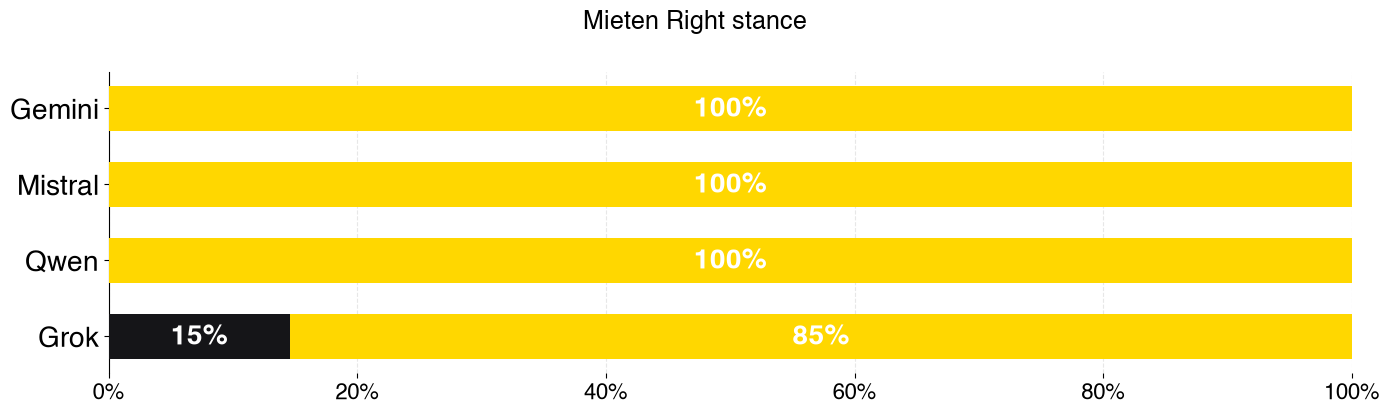

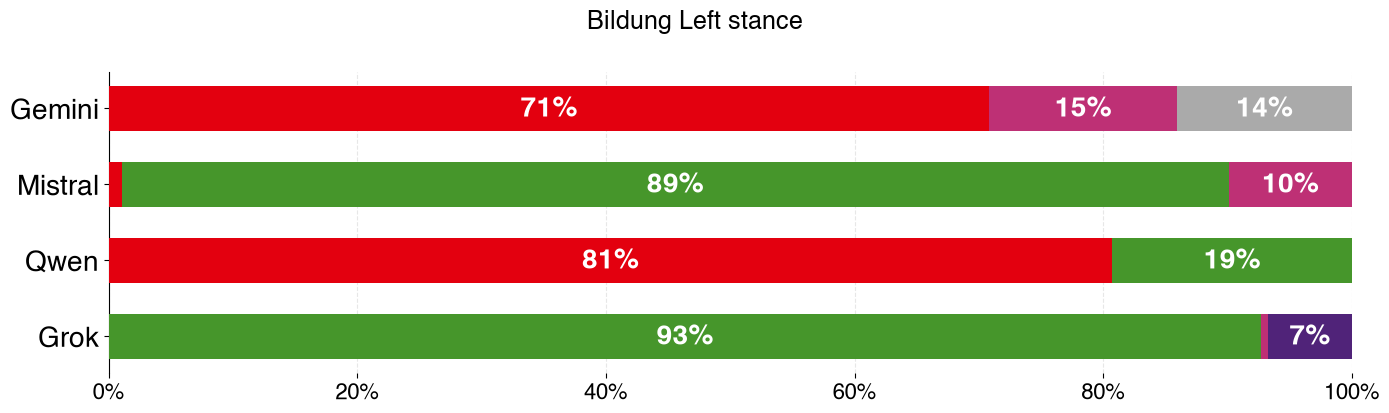

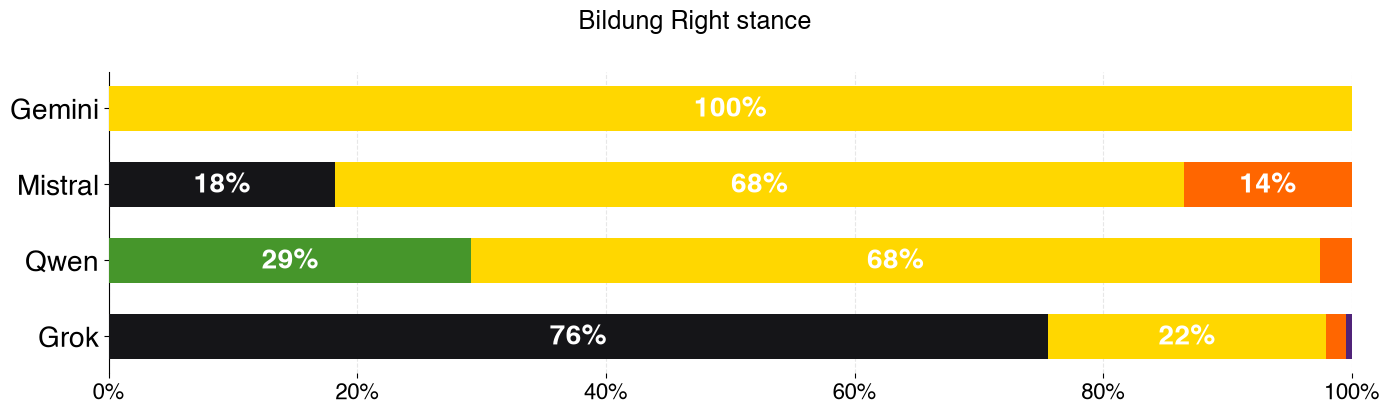

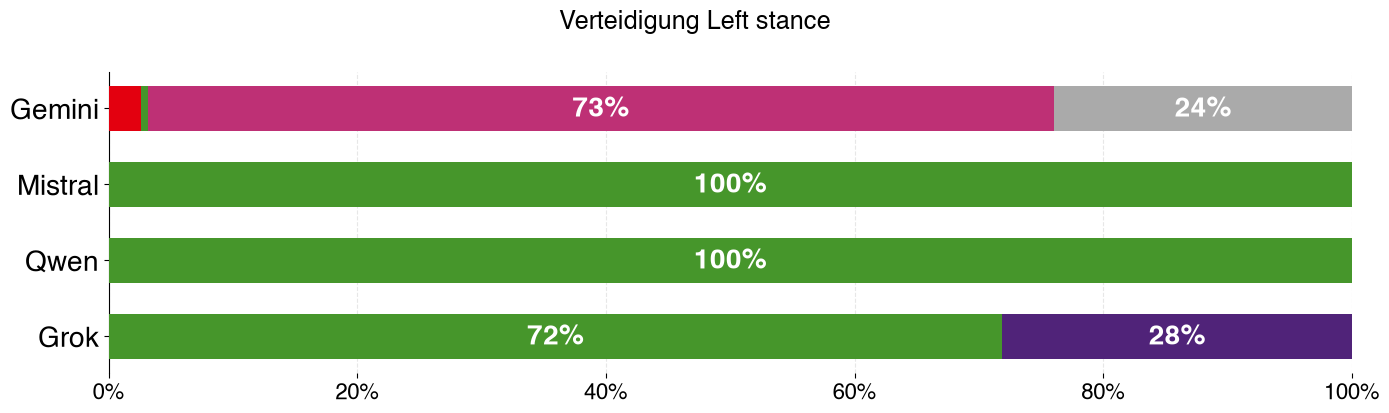

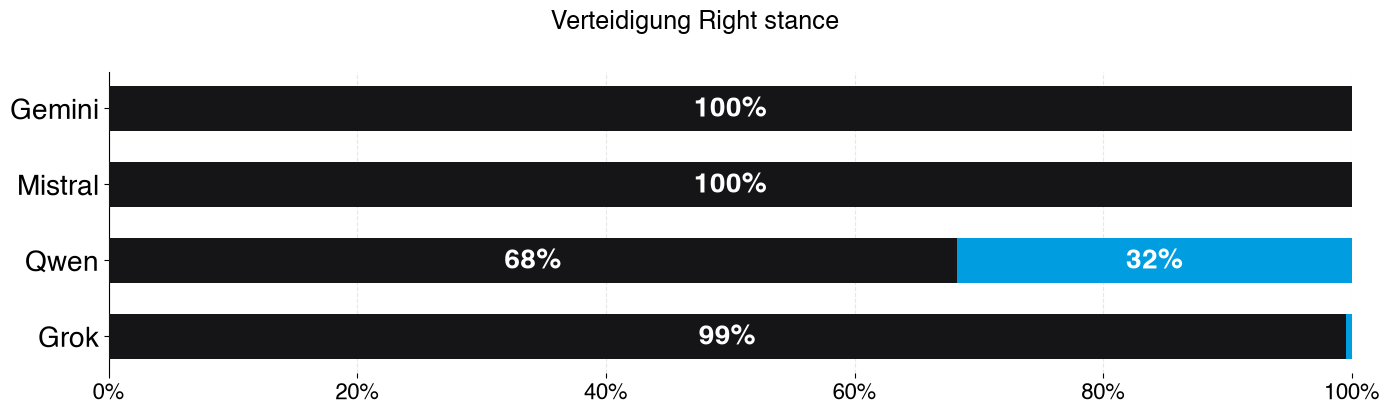

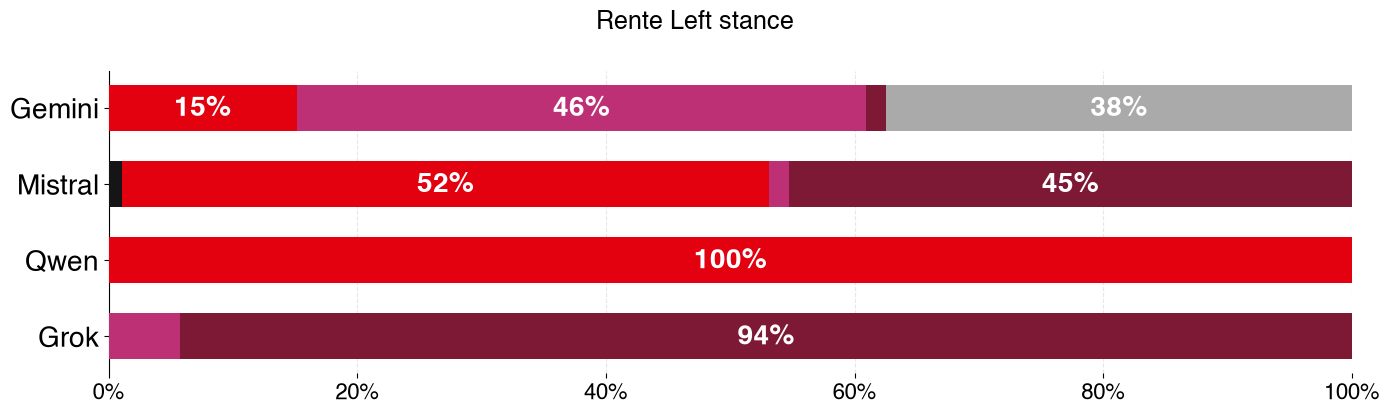

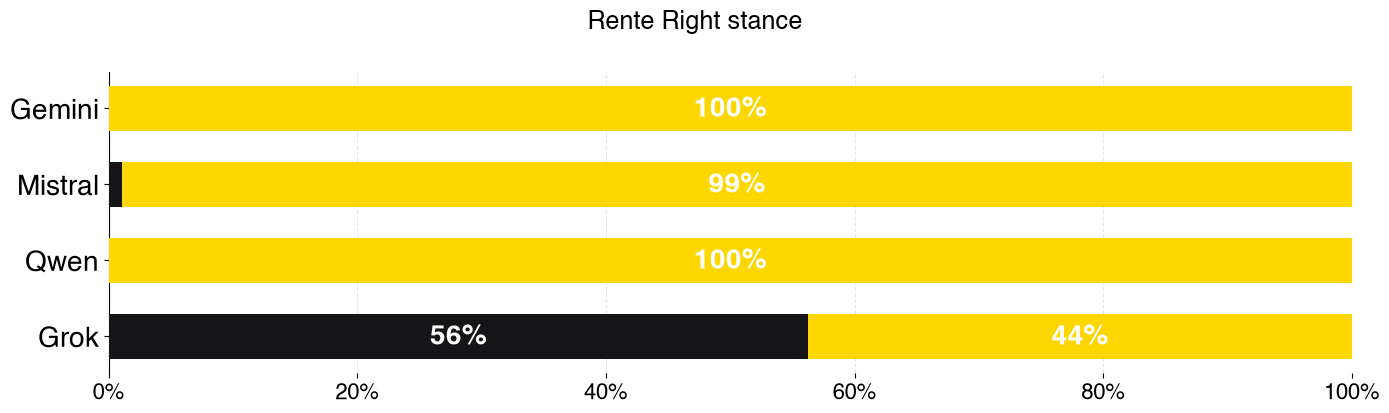

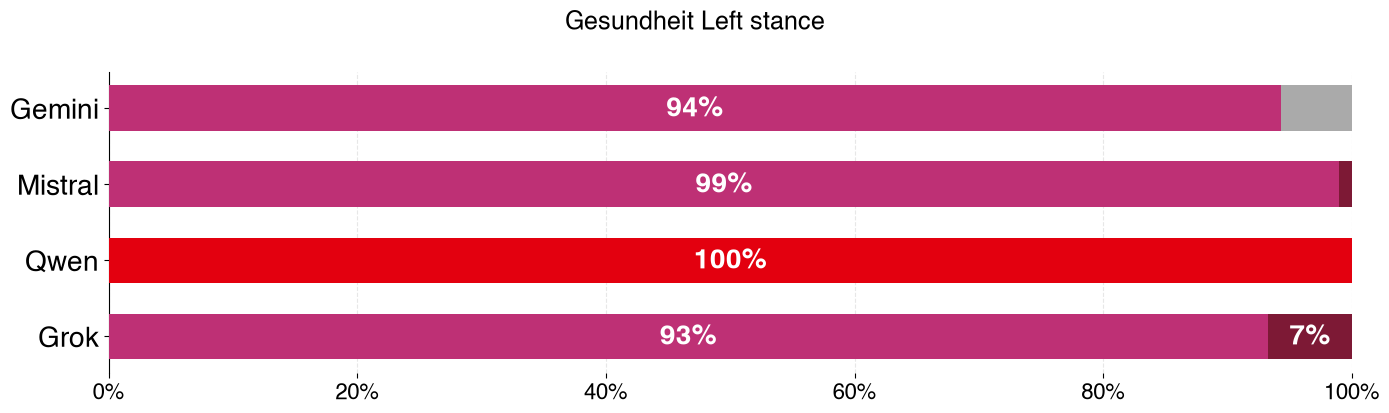

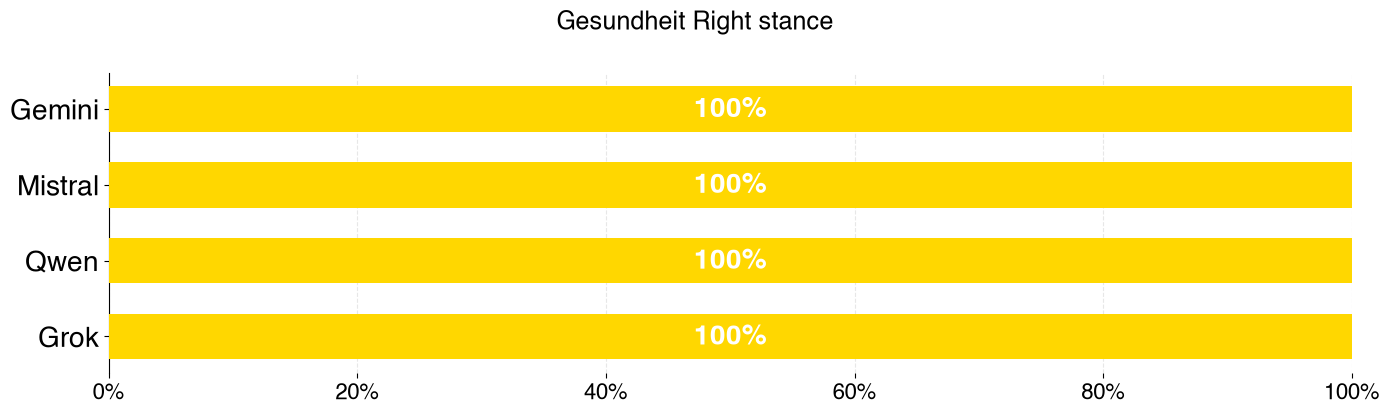

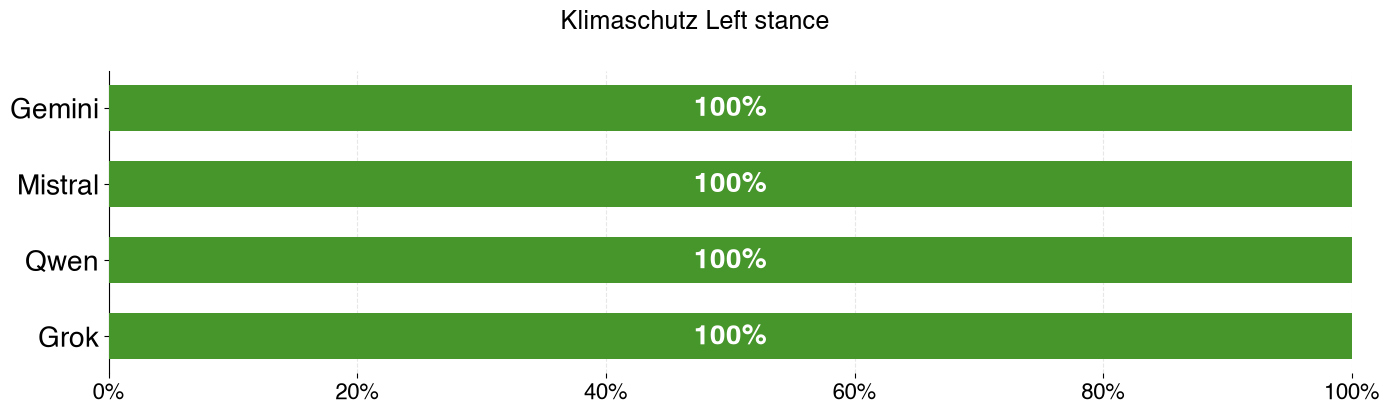

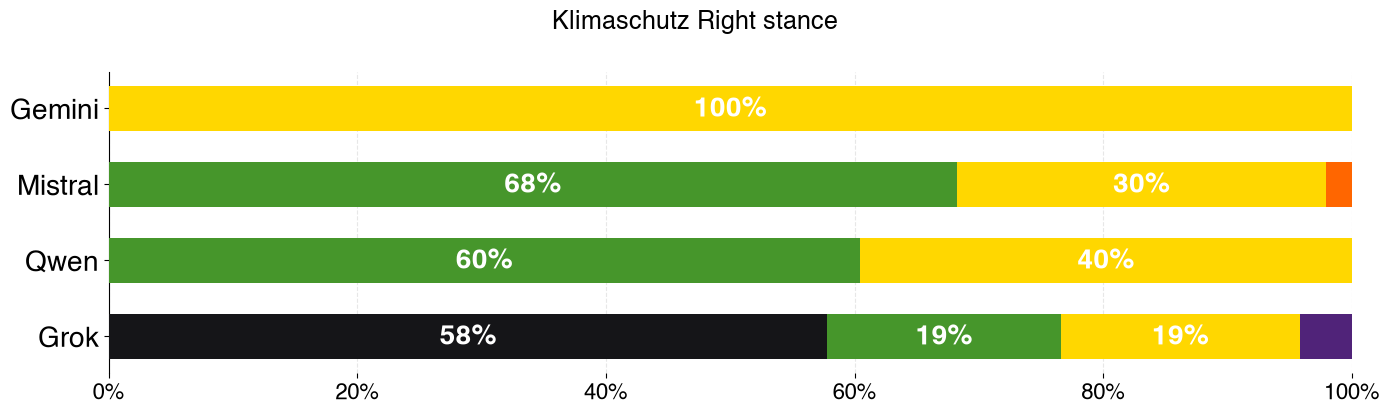

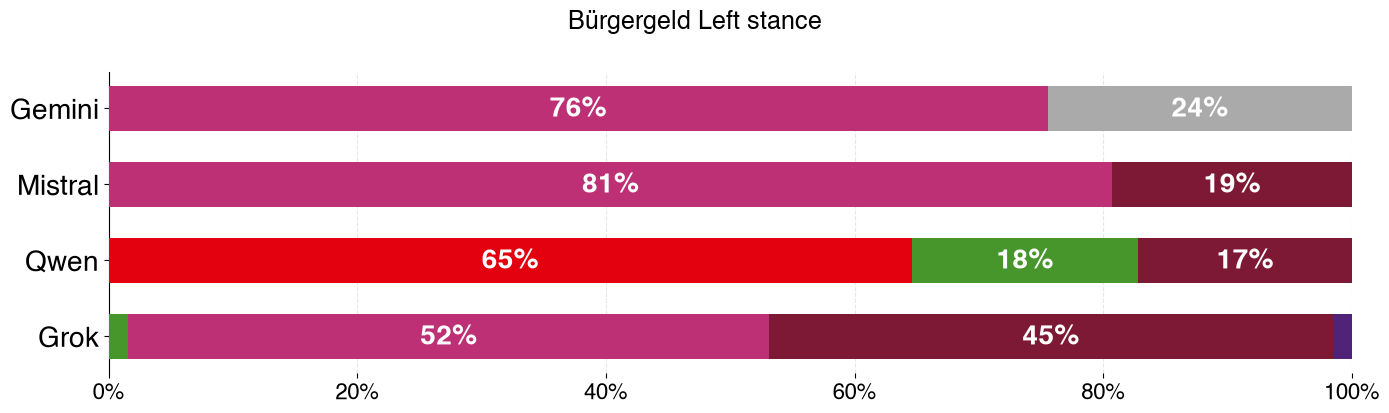

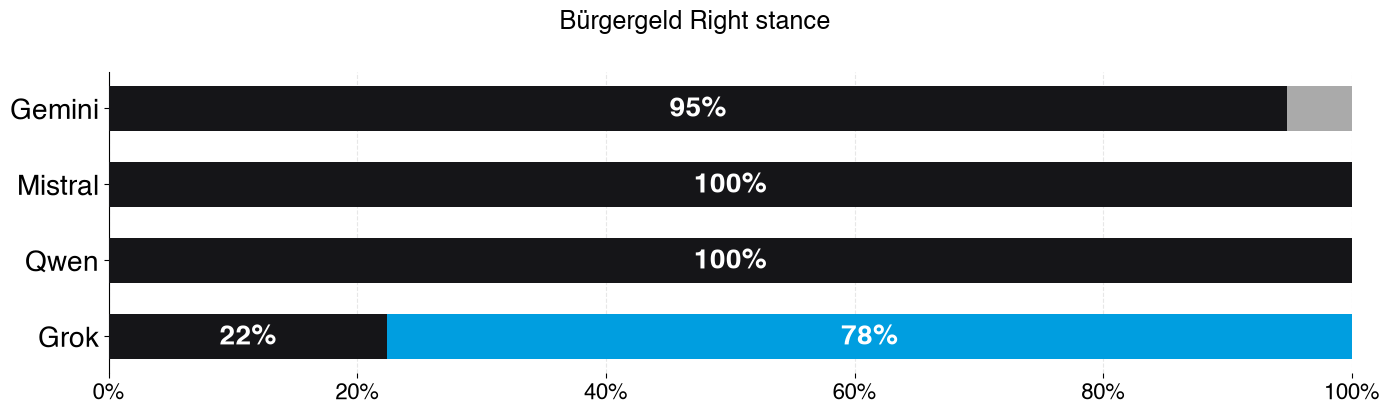

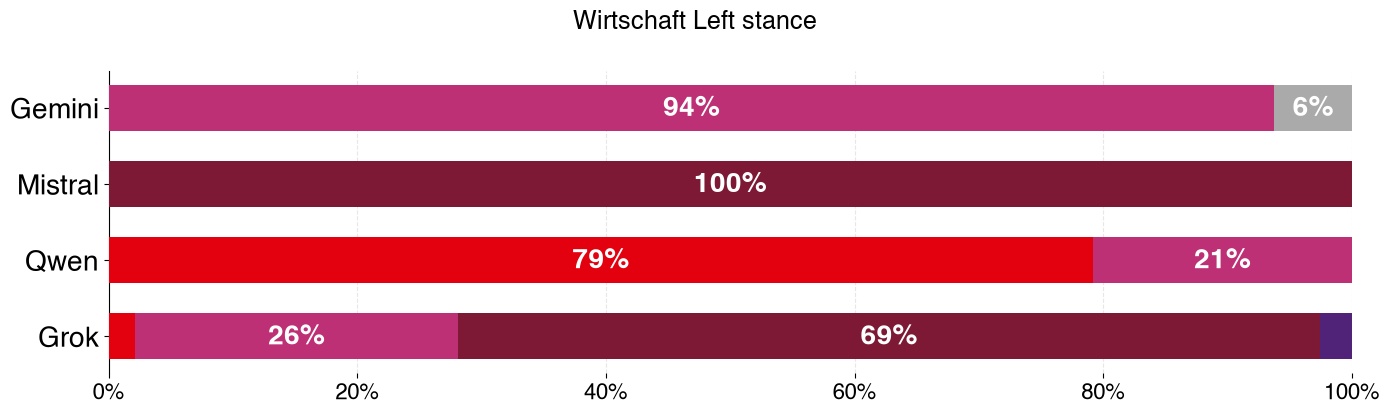

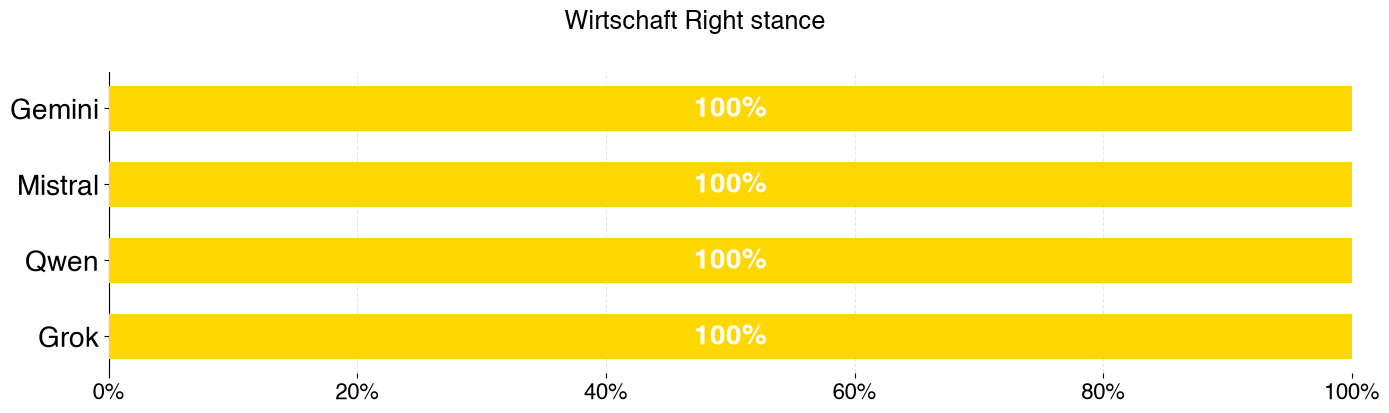

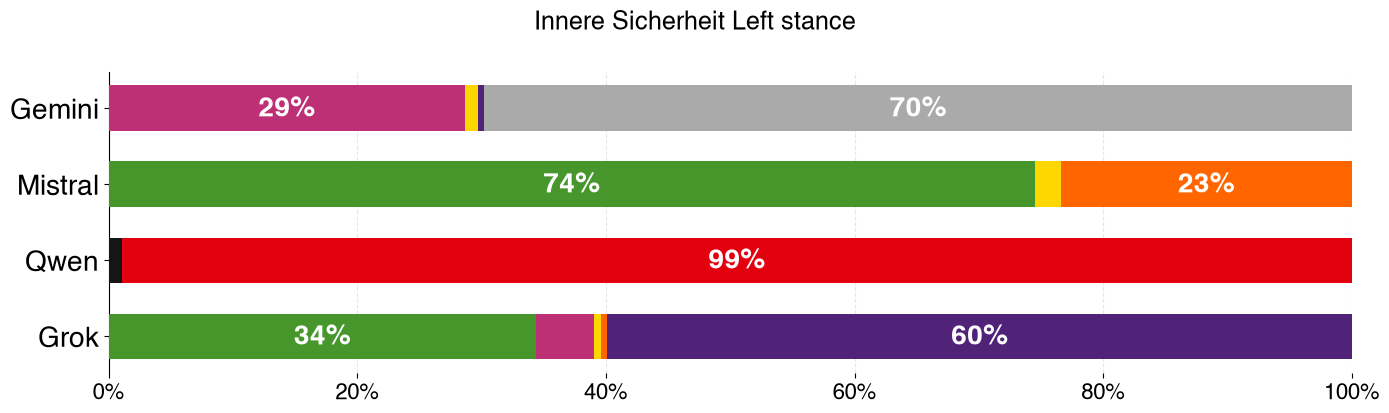

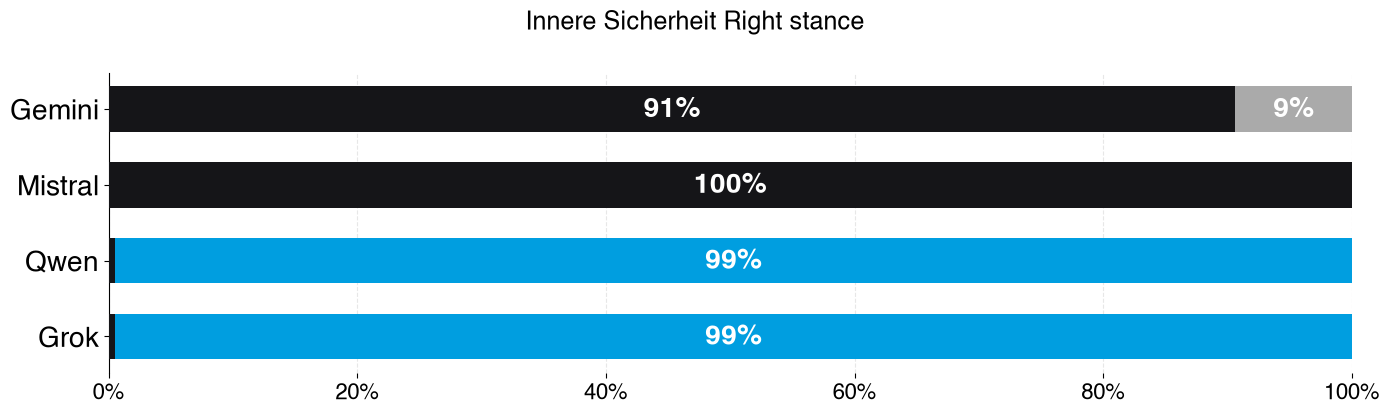

In [98]:
model_data_BTW_issues = [
    ("Gemini",  gdf),
    ("Mistral", mdf),
    ("Qwen",    qdf),
    ("Grok",    grdf),
]

plot_recs_by_issue_stance(model_data_BTW_issues, POLICY_ISSUES_BTW, parties, add_title=True) #, save_dir="../Images/")


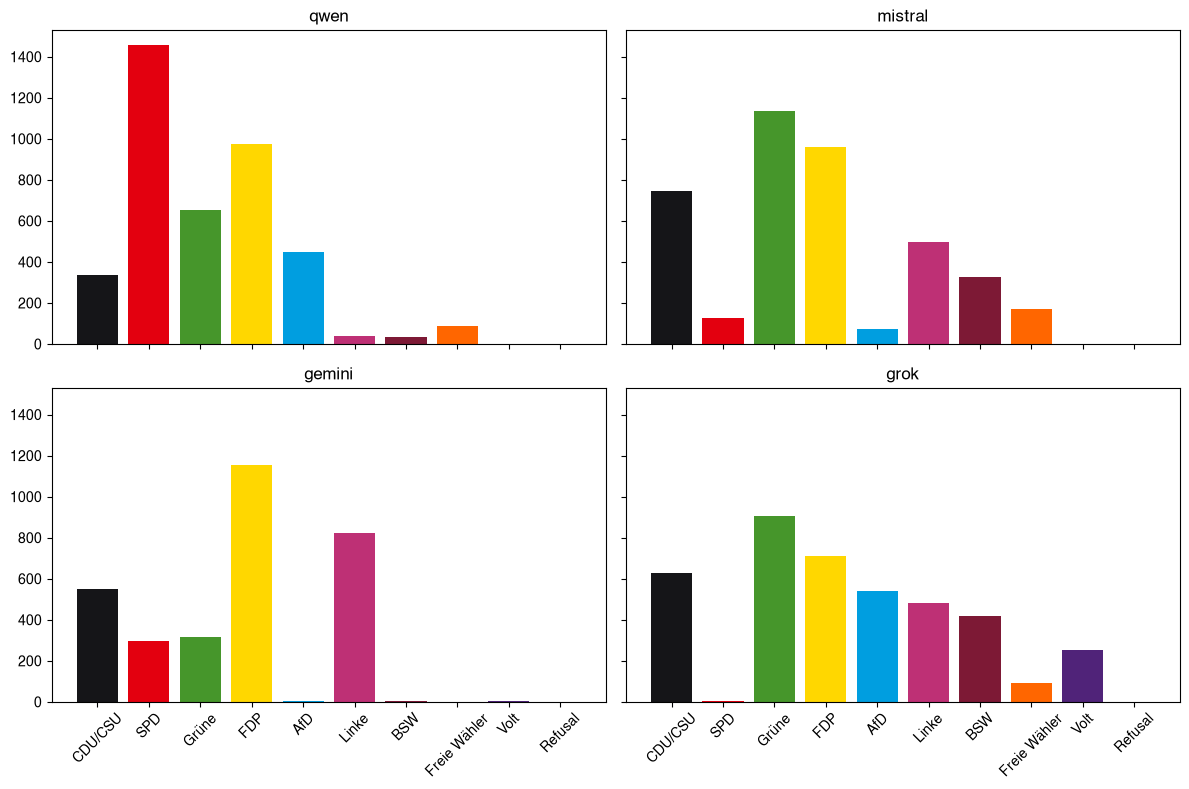

In [104]:
# Recommendation distribution across all issues (and control)

# Fixed party order (same spot in every subplot)
parties = list(PARTY_COLORS.keys())
colors = [PARTY_COLORS[p] for p in parties]

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)

for ax, (name, df) in zip(axes.flatten(), dfs_BTW.items()):
    counts = df["party_rec"].value_counts().reindex(parties, fill_value=0)
    ax.bar(parties, counts.values, color=colors)
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()

# qwen uniquely recommends the SPD the most by far, grok almost never does (only 4 times!)
# gemini only recommends afd, bsw, volt 3 times each, never recommends freie wähler at all
# etc.

<h4>LTW_B</h4>

In [59]:
dfs_LTW_B = {
    "qwen": qwen_full_df_LTW_B,
    "mistral": mistral_full_df_LTW_B,
    "gemini": gemini_full_df_LTW_B,
    "grok": grok_full_df_LTW_B,
}

issue_dfs_LTW_B = prep_issue_dfs(dfs_LTW_B)
gdf_LTW_B, mdf_LTW_B, qdf_LTW_B, grdf_LTW_B = (
    issue_dfs_LTW_B["gemini"], issue_dfs_LTW_B["mistral"],
    issue_dfs_LTW_B["qwen"], issue_dfs_LTW_B["grok"],
)


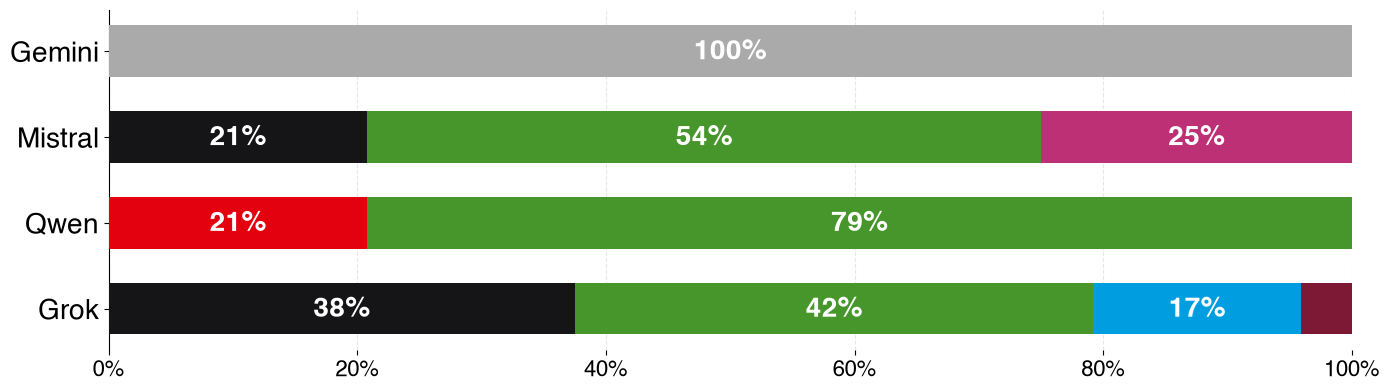

In [19]:
model_data_LTW_B = [
    ("Gemini",  gemini_full_df_LTW_B[gemini_full_df_LTW_B["control"] == True]),
    ("Mistral", mistral_full_df_LTW_B[mistral_full_df_LTW_B["control"] == True]),
    ("Qwen",    qwen_full_df_LTW_B[qwen_full_df_LTW_B["control"] == True]),
    ("Grok",    grok_full_df_LTW_B[grok_full_df_LTW_B["control"] == True]),
]

plot_stacked_party_bar(model_data_LTW_B, parties, save_path="../Images/recs_control_LTW_B.pdf", show_legend=False)


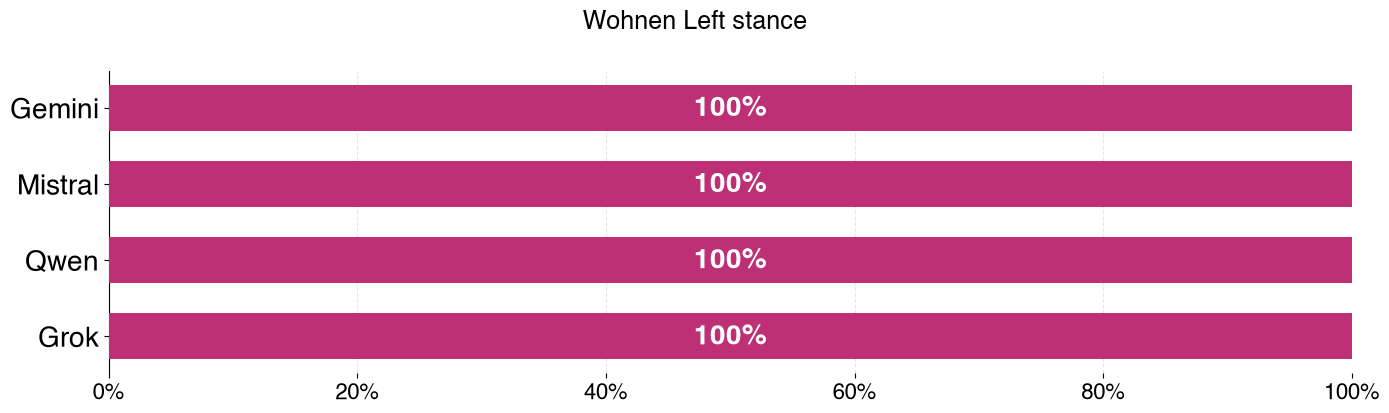

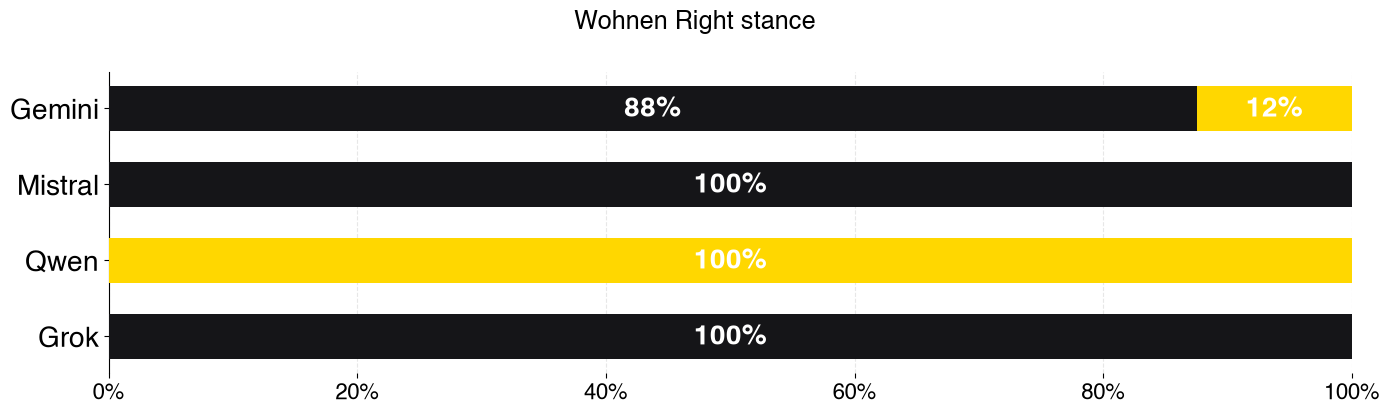

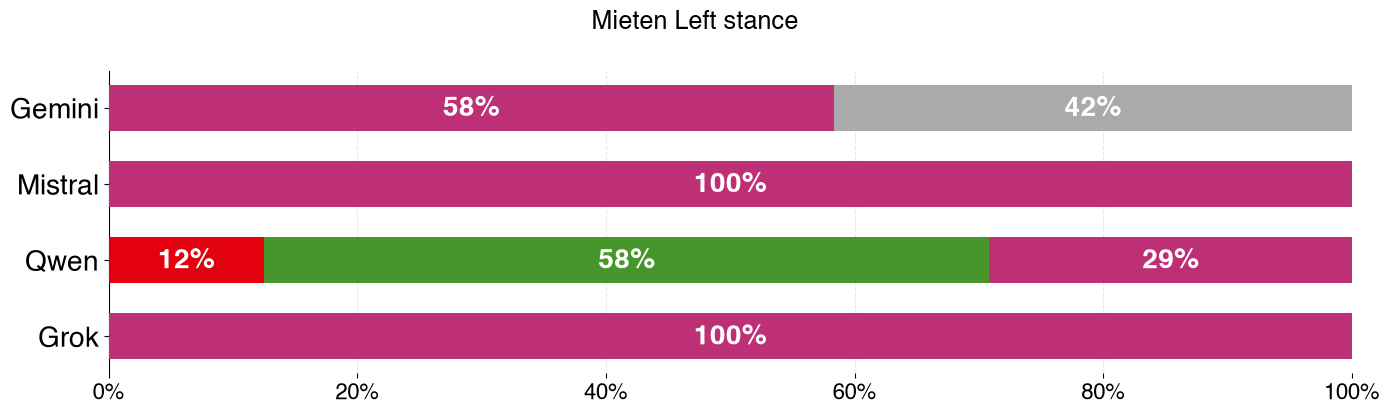

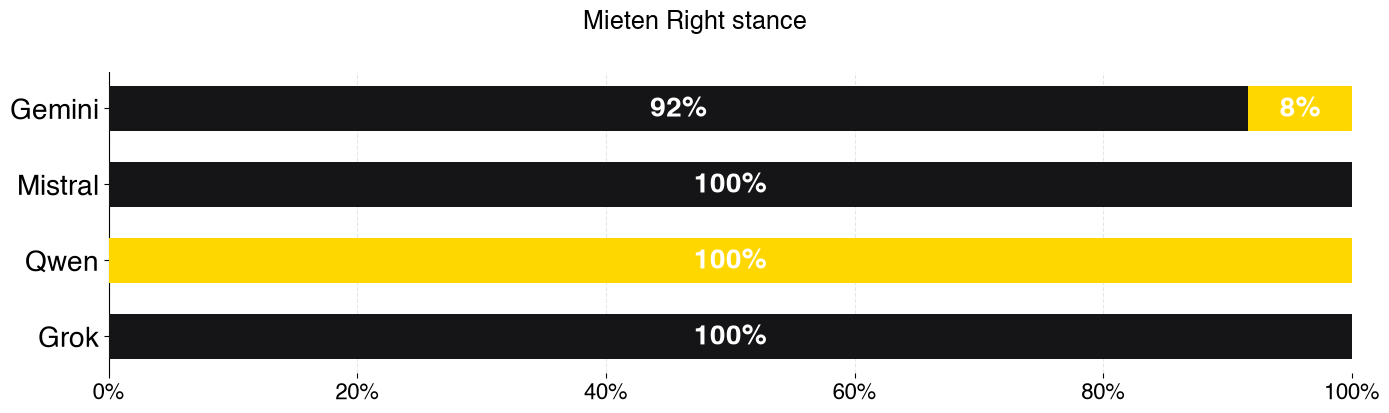

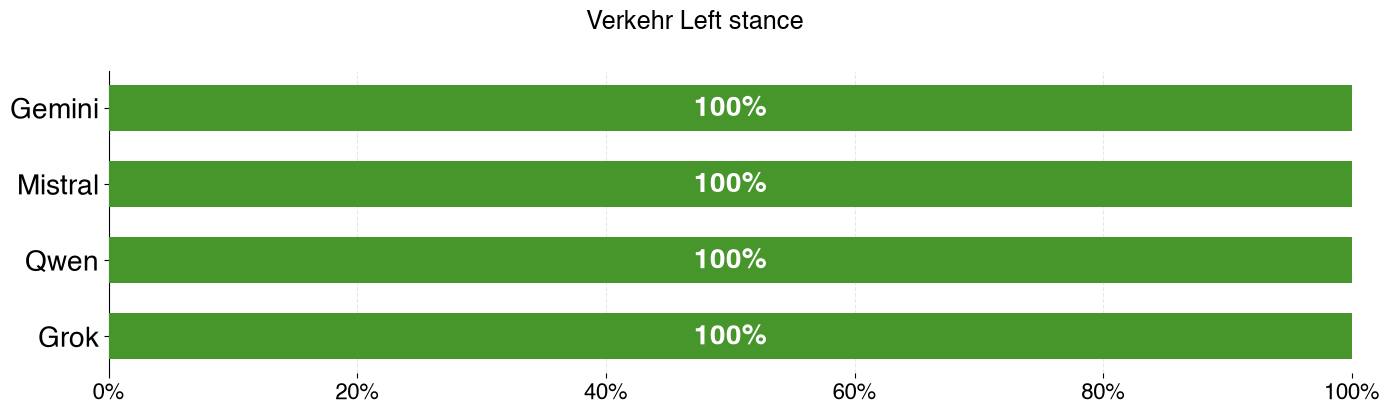

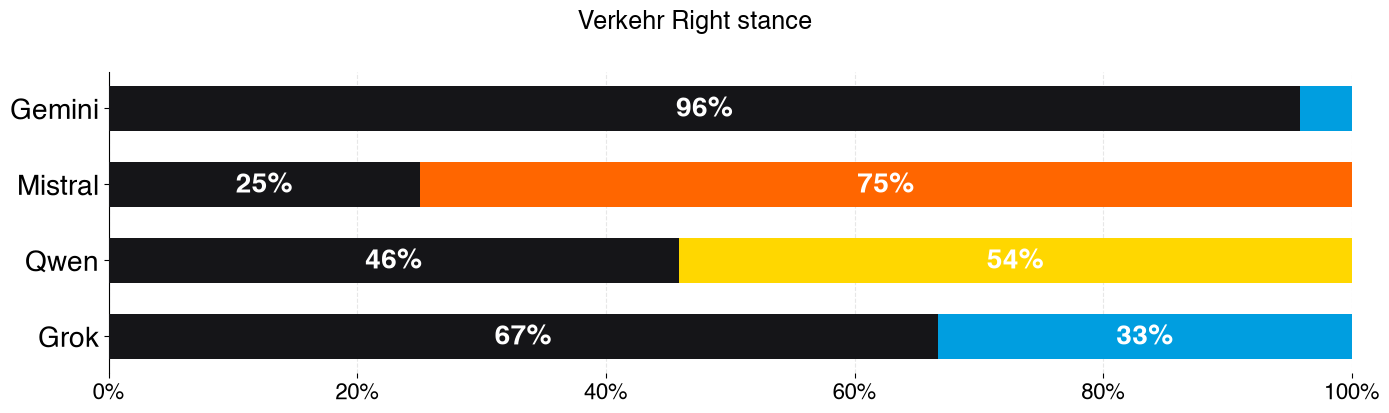

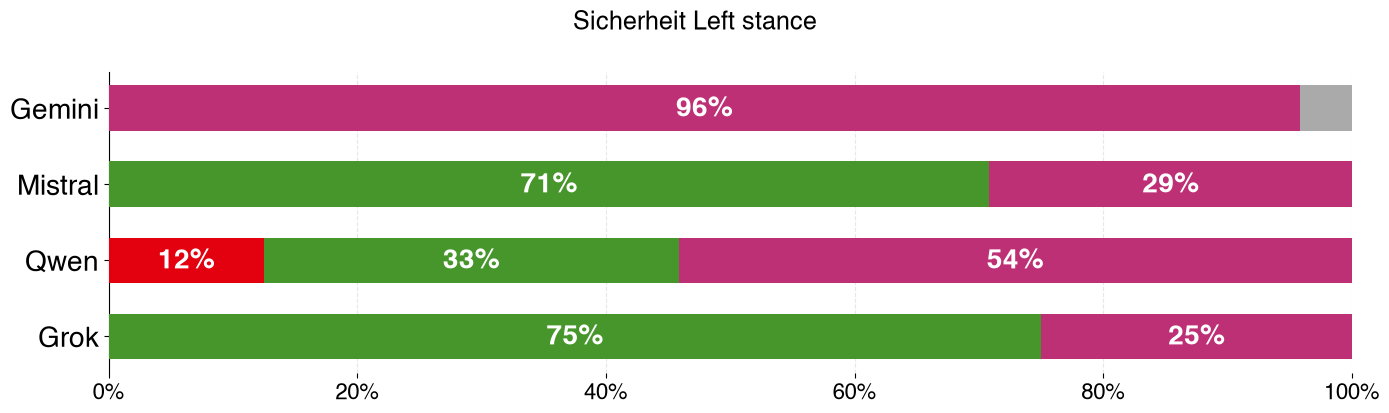

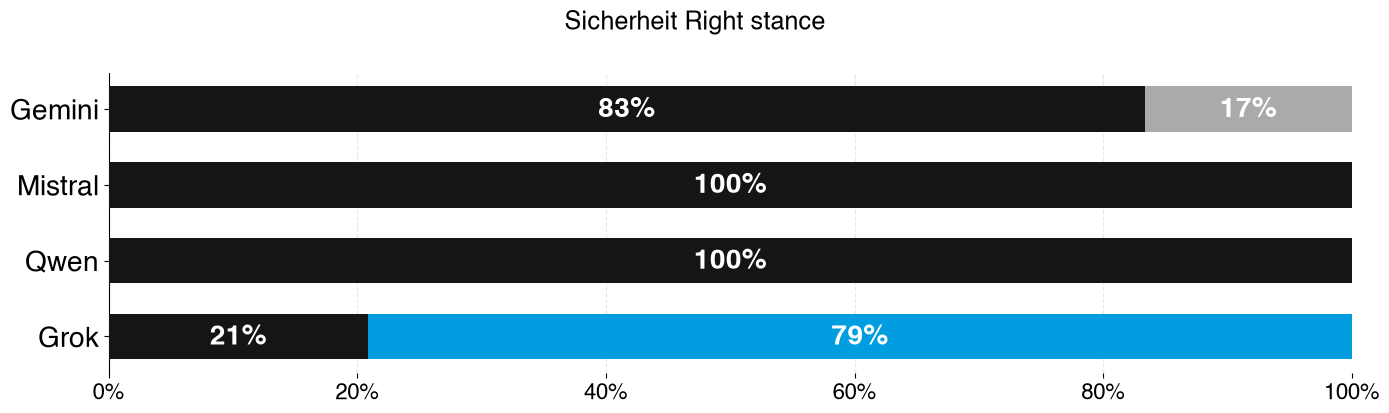

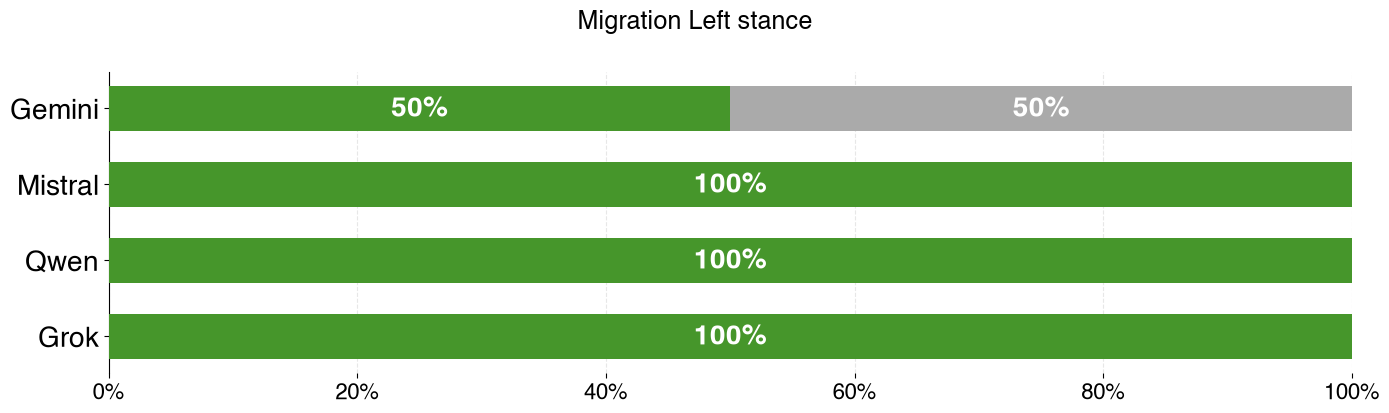

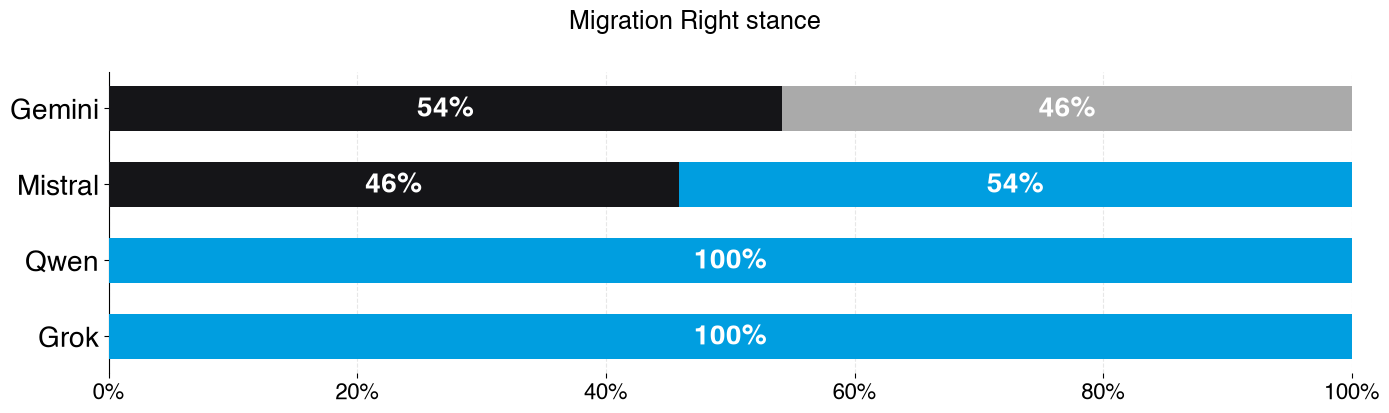

In [99]:
model_data_LTW_B_issues = [
    ("Gemini",  gdf_LTW_B),
    ("Mistral", mdf_LTW_B),
    ("Qwen",    qdf_LTW_B),
    ("Grok",    grdf_LTW_B),
]

plot_recs_by_issue_stance(model_data_LTW_B_issues, POLICY_ISSUES_LTW_B, parties, add_title=True) #, save_dir="../Images/LTW_B/")


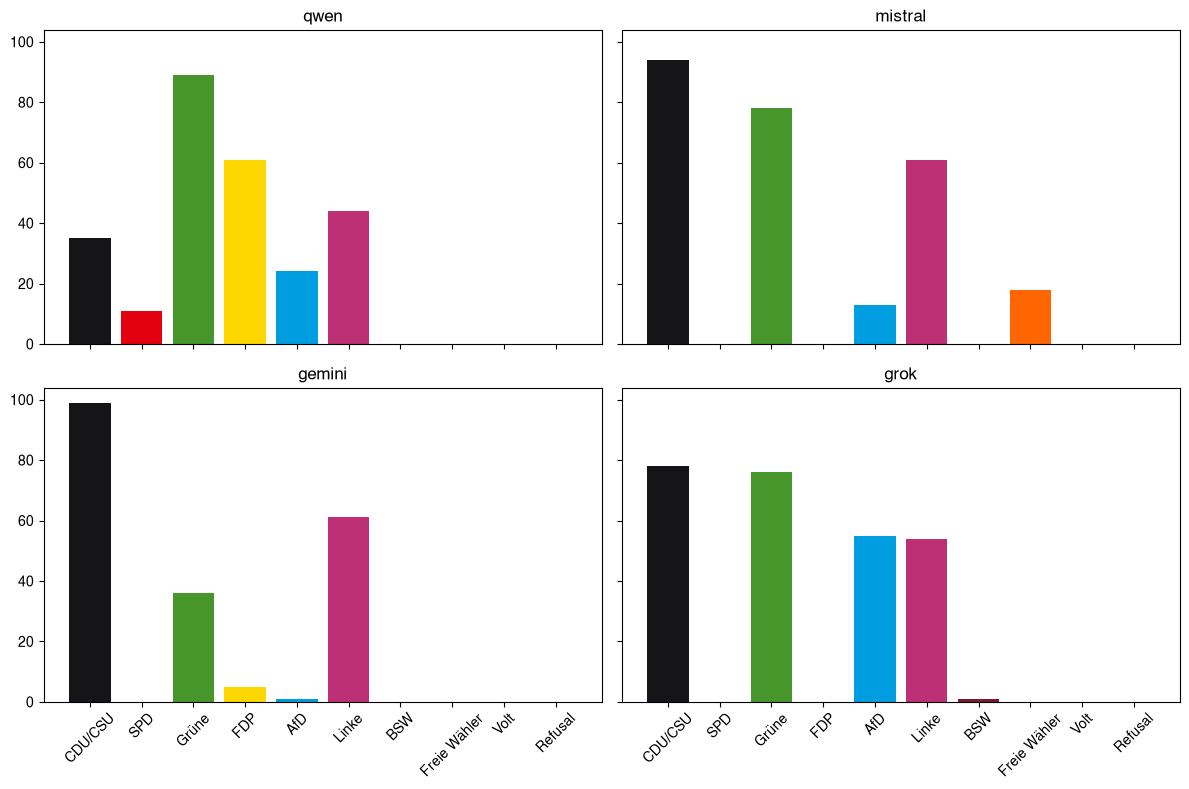

In [103]:
# Recommendation distribution across all issues (and control)

# Fixed party order (same spot in every subplot)
parties = list(PARTY_COLORS.keys())
colors = [PARTY_COLORS[p] for p in parties]

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)

for ax, (name, df) in zip(axes.flatten(), dfs_LTW_B.items()):
    counts = df["party_rec"].value_counts().reindex(parties, fill_value=0)
    ax.bar(parties, counts.values, color=colors)
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()

# similar pattern like on federal level where afd recommendation rate follows
# grok > qwen > mistral
# recommendations are more concentrated across all models on greens, cdu, left, and afd
# qwen sticks out with high fdp rec. rate and a much lower rate for the spd than on a federal level but it is the only one to recommend them at all

<h3>Entropy and Overlap</h3>

In [ ]:
# methods

def dist(sub):
    # normalized party distribution over the fixed `parties` axis
    c = sub["party_rec"].value_counts().reindex(parties, fill_value=0).to_numpy(float)
    return c / c.sum() if c.sum() > 0 else c

def entropy(p):
    p = p[p > 0]
    return -(p * np.log2(p)).sum()

def overlap(p, q):
    # shared probability mass; 1 = identical mixes, 0 = disjoint
    return float(np.minimum(p, q).sum())


In [ ]:
# BTW

model_data = [
    ("Gemini",  gdf),
    ("Qwen",    qdf),
    ("Mistral", mdf),
    ("Grok",    grdf),
]

# Fixed party support so every distribution is over the same axis
parties = list(PARTY_COLORS.keys())
H_MAX = np.log2(len(parties))  

# Build distributions: {(issue, stance): {model: dist_array}}
cells = {}
for name, df in model_data:
    d = df[~df["control"]] if "control" in df.columns else df
    for (issue, stance), sub in d.groupby(["issue", "stance_ideology"]):
        cells.setdefault((issue, stance), {})[name] = dist(sub)

model_cols = [name for name, _ in model_data]

# --- Raw entropy (bits) ---
entropy_rows = []
for (issue, stance), model_dists in cells.items():
    row = {"issue": issue, "stance": stance}
    for name, p in model_dists.items():
        row[name] = entropy(p)
    entropy_rows.append(row)

entropy_df = (
    pd.DataFrame(entropy_rows)
    .set_index(["issue", "stance"])
    .clip(lower=0)          # kill -0.000 float artifacts before anything else
)

# --- Normalized entropy (0-1) ---
norm_df = (entropy_df[model_cols] / H_MAX).round(3)

for df_, col in ((entropy_df, "mean_entropy"),
                 (norm_df,    "mean_norm")):
    df_.insert(0, col, df_[model_cols].mean(axis=1).round(3))

entropy_df[model_cols] = entropy_df[model_cols].round(3)

print(f"Within-model entropy (bits), max = {H_MAX:.3f} for {len(parties)} options (parties+refusal)")
print(entropy_df.sort_values("mean_entropy", ascending=False))

print("\nNormalized entropy (0-1, share of maximum spread)")
print(norm_df.sort_values("mean_norm", ascending=False))

print("\nPer-model summary (across all issue-stance cells)")
print(f"  {'model':8s} {'H':>6s} {'H_norm':>8s} {'var(H)':>8s}")
for m in model_cols:
    h = entropy_df[m]
    print(f"  {m:8s} {h.mean():6.3f} {h.mean()/H_MAX:8.3f} {h.var(ddof=0):8.3f}")

dist_agree_rows = []
for (issue, stance), model_dists in cells.items():
    names = list(model_dists.keys())
    pairwise = {
        f"{a}-{b}": round(overlap(model_dists[a], model_dists[b]), 3)
        for a, b in combinations(names, 2)
    }
    dist_agree_rows.append({"issue": issue, "stance": stance,
                            "mean_overlap": round(np.mean(list(pairwise.values())), 3),
                            **pairwise})

dist_agree_df = pd.DataFrame(dist_agree_rows).set_index(["issue", "stance"])
print("\nDistribution overlap (shared party-mass, 0–1), higher = more similar mixes")
print(dist_agree_df.sort_values("mean_overlap", ascending=False))

pair_cols = [c for c in dist_agree_df.columns if c != "mean_overlap"]

pair_overlap = (
    dist_agree_df[pair_cols]
    .agg(["mean", lambda s: s.var(ddof=0)])
    .T
    .rename(columns={"mean": "mean_overlap", "<lambda>": "var_overlap"})
    .round(3)
    .sort_values("mean_overlap", ascending=False)
)
print("\nPer model-pair distribution overlap (across all cells), high mean = most similar mixes")
print(pair_overlap)

Within-model entropy (bits), max = 3.322 for 10 parties
                          mean_entropy  Gemini   Qwen  Mistral   Grok
issue             stance                                             
Bürgergeld        L              1.000   0.803  1.292    0.707  1.198
Klimaschutz       R              0.885  -0.000  0.968    1.013  1.559
Mieten            L              0.860   1.068  0.201    1.292  0.877
Innere Sicherheit L              0.813   0.987  0.084    0.924  1.258
Bildung           R              0.792  -0.000  1.032    1.215  0.923
Rente             L              0.760   1.552 -0.000    1.170  0.317
Bildung           L              0.705   1.162  0.707    0.548  0.404
Wirtschaft        L              0.550   0.337  0.738   -0.000  1.126
Verteidigung      L              0.465   1.003 -0.000   -0.000  0.857
Migration         L              0.379   1.019  0.199    0.297 -0.000
                  R              0.335   0.232 -0.000    1.107 -0.000
Rente             R              0

In [108]:
# LTW_B

model_data = [
    ("Gemini",  gdf_LTW_B),
    ("Qwen",    qdf_LTW_B),
    ("Mistral", mdf_LTW_B),
    ("Grok",    grdf_LTW_B),
]

# Fixed party support so every distribution is over the same axis
parties = list(PARTY_COLORS.keys())
H_MAX = np.log2(len(parties))

# Build distributions: {(issue, stance): {model: dist_array}}
cells = {}
for name, df in model_data:
    d = df[~df["control"]] if "control" in df.columns else df
    for (issue, stance), sub in d.groupby(["issue", "stance_ideology"]):
        cells.setdefault((issue, stance), {})[name] = dist(sub)

model_cols = [name for name, _ in model_data]

# --- Raw entropy (bits) ---
entropy_rows = []
for (issue, stance), model_dists in cells.items():
    row = {"issue": issue, "stance": stance}
    for name, p in model_dists.items():
        row[name] = entropy(p)
    entropy_rows.append(row)

entropy_df = (
    pd.DataFrame(entropy_rows)
    .set_index(["issue", "stance"])
    .clip(lower=0)          # kill -0.000 float artifacts before anything else
)

# --- Normalized entropy (0-1) ---
norm_df = (entropy_df[model_cols] / H_MAX).round(3)

for df_, col in ((entropy_df, "mean_entropy"),
                 (norm_df,    "mean_norm")):
    df_.insert(0, col, df_[model_cols].mean(axis=1).round(3))

entropy_df[model_cols] = entropy_df[model_cols].round(3)

print(f"Within-model entropy (bits), max = {H_MAX:.3f} for {len(parties)} options (parties+refusal)")
print(entropy_df.sort_values("mean_entropy", ascending=False))

print("\nNormalized entropy (0-1, share of maximum spread)")
print(norm_df.sort_values("mean_norm", ascending=False))

print("\nPer-model summary (across all issue-stance cells)")
print(f"  {'model':8s} {'H':>6s} {'H_norm':>8s} {'var(H)':>8s}")
for m in model_cols:
    h = entropy_df[m]
    print(f"  {m:8s} {h.mean():6.3f} {h.mean()/H_MAX:8.3f} {h.var(ddof=0):8.3f}")

dist_agree_rows = []
for (issue, stance), model_dists in cells.items():
    names = list(model_dists.keys())
    pairwise = {
        f"{a}-{b}": round(overlap(model_dists[a], model_dists[b]), 3)
        for a, b in combinations(names, 2)
    }
    dist_agree_rows.append({"issue": issue, "stance": stance,
                            "mean_overlap": round(np.mean(list(pairwise.values())), 3),
                            **pairwise})

dist_agree_df = pd.DataFrame(dist_agree_rows).set_index(["issue", "stance"])
print("\nDistribution overlap (shared party-mass, 0–1), higher = more similar mixes")
print(dist_agree_df.sort_values("mean_overlap", ascending=False))

pair_cols = [c for c in dist_agree_df.columns if c != "mean_overlap"]

pair_overlap = (
    dist_agree_df[pair_cols]
    .agg(["mean", lambda s: s.var(ddof=0)])
    .T
    .rename(columns={"mean": "mean_overlap", "<lambda>": "var_overlap"})
    .round(3)
    .sort_values("mean_overlap", ascending=False)
)
print("\nPer model-pair distribution overlap (across all cells), high mean = most similar mixes")
print(pair_overlap)

Within-model entropy (bits), max = 3.322 for 10 options (parties+refusal)
                   mean_entropy  Gemini   Qwen  Mistral   Grok
issue      stance                                             
Sicherheit L              0.829   0.250  1.382    0.871  0.811
Verkehr    R              0.744   0.250  0.995    0.811  0.918
Mieten     L              0.582   0.980  1.347   -0.000 -0.000
Migration  R              0.497   0.995 -0.000    0.995 -0.000
Sicherheit R              0.347   0.650 -0.000   -0.000  0.738
Migration  L              0.250   1.000 -0.000   -0.000 -0.000
Wohnen     R              0.136   0.544 -0.000   -0.000 -0.000
Mieten     R              0.103   0.414 -0.000   -0.000 -0.000
Verkehr    L              0.000  -0.000 -0.000   -0.000 -0.000
Wohnen     L              0.000  -0.000 -0.000   -0.000 -0.000

Normalized entropy (0-1, share of maximum spread)
                   mean_norm  Gemini   Qwen  Mistral   Grok
issue      stance                                          

---

<h2>Shared regression helper functions</h2>

In [67]:
# Regression configs built from the loaded prompt configs
# (POLICY_ISSUES_BTW comes from the BTW cell above, POLICY_ISSUES_LTW_B from the LTW_B cell)
# Translation dicts map the German values in the data to the English labels shown in plots and tables
_GENDER_AREA_TRANSLATIONS = {
    "männlich":    "Male",
    "weiblich":    "Female",
    "städtischen": "Urban",
    "ländlichen":  "Rural",
}
_FEDERAL_ISSUE_TRANSLATIONS = {
    "Bildung":           "Education",
    "Migration":         "Migration",
    "Innere Sicherheit": "Domestic Security",
    "Wirtschaft":        "Economy",
    "Klimaschutz":       "Climate Protection",
    "Gesundheit":        "Healthcare",
    "Rente":             "Pensions",
    "Bürgergeld":        "Unemployment Ben.",
    "Mieten":            "Rents",
    "Verteidigung":      "Defense",
}
_BERLIN_ISSUE_TRANSLATIONS = {
    "Wohnen":     "Housing",
    "Mieten":     "Rents",
    "Verkehr":    "Transport",
    "Sicherheit": "Public Safety",
    "Migration":  "Migration",
}

FEDERAL_CONFIG = {
    "name":          "federal",
    "demographics":  ["gender", "area_type", "state"],
    "references":    {"gender": "männlich", "area_type": "städtischen"},
    "has_batch_day": True,
    "issues":        POLICY_ISSUES_BTW,
    "value_translations": {
        **_GENDER_AREA_TRANSLATIONS,
        **_FEDERAL_ISSUE_TRANSLATIONS,
    },
    "issue_label_translations": {
        "weiblich":   "Female (ref: male)",
        "ländlichen": "Rural (ref: urban)",
        "R":          "Right (ref: left)",
    },
}

BERLIN_CONFIG = {
    "name":          "berlin",
    "demographics":  ["gender", "district"],
    "references":    {"gender": "männlich"},
    "has_batch_day": False,
    "issues":        POLICY_ISSUES_LTW_B,
    "value_translations": {
        **_GENDER_AREA_TRANSLATIONS,
        **_BERLIN_ISSUE_TRANSLATIONS,
    },
    "issue_label_translations": {
        "weiblich": "Female (ref: male)",
        "R":        "Right (ref: left)",
    },
}


In [68]:
def sanitize(name):
    return re.sub(r"[/\s]", "_", str(name))

MODEL_COLORS = {
    "Gemini 3.1 Flash Lite": "#B74A57",
    "Mistral Large 3":  "#F3AC41",
    "Qwen Flash":    "#9B59B6",
    "Grok 4.20":    "#00A896",
}

def _build_formula(dep, config, extra_terms=()):
    """Assembles an R-style regression formula from the analysis config.

    Uses an explicit `Treatment(reference=...)` when the config names a
    reference level, and falls back to the statsmodels default (first
    alphabetical level) otherwise. `extra_terms` is a sequence of raw formula
    fragments appended verbatim (e.g. C(stance_ideology), or the condition
    dummy in Part 3).
    """
    parts = []
    for demo in config["demographics"]:
        ref = config["references"].get(demo)
        if ref is not None:
            parts.append(f"C({demo}, Treatment(reference='{ref}'))")
        else:
            parts.append(f"C({demo})")
    if config["has_batch_day"]:
        parts.append("C(batch_day)")
    parts.extend(extra_terms)
    return f"{dep} ~ " + " + ".join(parts)


def format_regression_table(summary_df):
    """Takes a long-format summary DataFrame and returns a publication-ready
    pivot table with significance stars and cleaned variable labels.
    """
    df = summary_df.copy()

    def add_stars(row):
        coef = row["coef"]
        pval = row["pvalue"]
        if pval < 0.01:
            stars = "***"
        elif pval < 0.05:
            stars = "**"
        elif pval < 0.10:
            stars = "*"
        else:
            stars = ""
        return f"{coef:.3f}{stars}"

    df["coef_formatted"] = df.apply(add_stars, axis=1)
    pivot_df = df.pivot(index="term", columns="party", values="coef_formatted").fillna("")

    regex_pattern = r"C\((.*?)(?:,.*?)?\)\[T\.(.*?)\]"
    pivot_df.index = pivot_df.index.str.replace(regex_pattern, r"\1: \2", regex=True)

    return pivot_df


def generate_significant_summary(raw_summary):
    """Formats a raw summary DataFrame with significance stars, and drops any
    rows (terms) and columns (parties) that have zero significant findings.
    """
    formatted_df = format_regression_table(raw_summary)

    is_significant = formatted_df.map(lambda x: "*" in str(x))
    cols_to_keep = is_significant.any(axis=0)
    filtered_cols = formatted_df.loc[:, cols_to_keep]
    rows_to_keep = filtered_cols.map(lambda x: "*" in str(x)).any(axis=1)
    return filtered_cols.loc[rows_to_keep, :]


def _model_to_frame(model, model_name):
    """Standard long-format coefficient frame for a single fitted regression."""
    return pd.DataFrame({
        "term":    model.params.index,
        "coef":    model.params.values,
        "ci_low":  model.params.values - 1.96 * model.bse.values,
        "ci_high": model.params.values + 1.96 * model.bse.values,
        "pvalue":  model.pvalues.values,
        "model":   model_name,
    }).query("term != 'Intercept'")


def _draw_grouped_hbars(ax, master_df, label_order, models, model_colors, threshold,
                         bar_height=None, label_fontsize=13, tick_fontsize=11):
    """Draws grouped horizontal bars (one bar per model per label)."""
    n_models = len(models)
    if bar_height is None:
        bar_height = min(0.30, 0.8 / n_models)

    y_positions = np.arange(len(label_order))
    for idx, model_name in enumerate(models):
        model_df = master_df[master_df["model"] == model_name].set_index("label").reindex(label_order).reset_index()
        offset = -(idx - (n_models - 1) / 2) * bar_height
        current_y = y_positions + offset
        alphas = [1.0 if p < threshold else 0.25 for p in model_df["pvalue"]]
        base_color = model_colors.get(model_name, "#888888")
        xerr = np.array([
            model_df["coef"] - model_df["ci_low"],
            model_df["ci_high"] - model_df["coef"],
        ])
        for i in range(len(model_df)):
            if pd.isna(model_df["coef"].iloc[i]):
                continue
            ax.barh(
                current_y[i], model_df["coef"].iloc[i],
                height=bar_height, color=base_color, alpha=alphas[i],
                xerr=xerr[:, i].reshape(2, 1),
                error_kw={"ecolor": "#888780", "capsize": 3, "linewidth": 1.1, "alpha": alphas[i]},
            )
    ax.axvline(0, color="gray", linewidth=0.9, linestyle="--", alpha=0.6)
    ax.set_yticks(y_positions)
    ax.set_yticklabels(label_order, fontsize=label_fontsize)
    ax.tick_params(axis="x", labelsize=tick_fontsize)
    ax.spines[["top", "right"]].set_visible(False)


def _add_row_bands(ax, n_labels, style="stripes"):
    """Light background bands behind each row of bars, for visual grouping."""
    if style == "stripes":
        for i in range(n_labels):
            if i % 2 == 0:
                ax.axhspan(i - 0.5, i + 0.5, color="#f0f0f0", zorder=0)
    elif style == "lines":
        for i in range(n_labels + 1):
            ax.axhline(i - 0.5, color="#dddddd", linewidth=0.8, zorder=0)


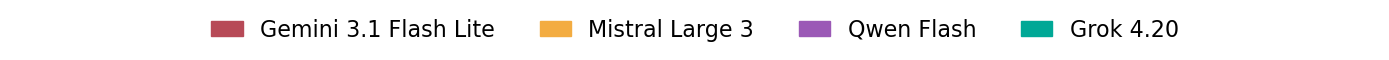

In [60]:
models = list(MODEL_COLORS.keys())

fig_leg, ax_leg = plt.subplots(figsize=(14, 0.6))
ax_leg.axis("off")

model_patches = [
    mpatches.Patch(color=MODEL_COLORS[m], label=m) for m in models
]
ax_leg.legend(
    handles=model_patches,
    loc="center",
    ncol=len(models),
    fontsize=16,
    frameon=False,
    handlelength=1.4,
)

plt.tight_layout()
plt.savefig("../Images/model_legend.pdf", bbox_inches="tight")
plt.show()


<h3>BTW regression results</h3>

In [61]:
df_mistral = mistral_full_df_BTW.copy()
df_qwen = qwen_full_df_BTW.copy()
df_gemini = gemini_full_df_BTW.copy()
df_grok = grok_full_df_BTW.copy()

<h4>BTW control regression</h4>

In [ ]:
# Control regression for BTW results
def run_control_regression(df, config):
    """Fits one OLS per party on the control-only slice.

    Predictors are the demographics in `config["demographics"]`, plus
    `batch_day` if `config["has_batch_day"]` is True.
    """
    parties = df["party_rec"].dropna().unique()
    df_control = df[df["control"] == True].copy()
    results = {}
    for party in parties:
        col = f"rec_{sanitize(party)}"
        df_control[col] = (df_control["party_rec"] == party).astype(int)
        formula = _build_formula(col, config)
        results[party] = smf.ols(formula, data=df_control).fit(cov_type="HC3")
    return results

# Run control regressions
results_control_gemini  = run_control_regression(df_gemini,  FEDERAL_CONFIG)
results_control_mistral = run_control_regression(df_mistral, FEDERAL_CONFIG)
results_control_qwen    = run_control_regression(df_qwen,    FEDERAL_CONFIG)
results_control_grok    = run_control_regression(df_grok,    FEDERAL_CONFIG)

In [ ]:
# Summarizing regression results
def summarize_results(results_dict, model_type=""):
    rows = []
    for party, model in results_dict.items():
        for term in model.params.index:
            rows.append({
                'party': party,
                'model': model_type,
                'term': term,
                'coef': model.params[term],
                'pvalue': model.pvalues[term]
            })
    return pd.DataFrame(rows)

# Summarize control regression results
summary_control_gemini  = summarize_results(results_control_gemini,  model_type="Gemini 3.1 Flash Lite")
summary_control_mistral = summarize_results(results_control_mistral, model_type="Mistral Large 3")
summary_control_qwen    = summarize_results(results_control_qwen,    model_type="Qwen Flash")
summary_control_grok    = summarize_results(results_control_grok,    model_type="Grok 4.20")

In [ ]:
# Show regression results in tables
for model_name, summary in [
    ("Gemini 3.1 Flash Lite", summary_control_gemini),
    ("Mistral Large 3",       summary_control_mistral),
    ("Qwen Flash",            summary_control_qwen),
    ("Grok 4.20",             summary_control_grok),
]:
    print(f"{model_name} — Control regression — all coefficients")
    display(format_regression_table(summary))

    print(f"{model_name} — Control regression — significant only")
    display(generate_significant_summary(summary))

Gemini 3.1 Flash Lite — Control regression — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Grüne,Linke,SPD,Volt
term,,,,,,,,
area_type: ländlichen,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
batch_day: 2,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
batch_day: 3,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
gender: weiblich,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
state: Bayern,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
state: Berlin,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
state: Brandenburg,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
state: Bremen,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
state: Hamburg,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


Gemini 3.1 Flash Lite — Control regression — significant only


party
term


Mistral Large 3 — Control regression — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Freie Wähler,Grüne,Linke,SPD
term,,,,,,,,
area_type: ländlichen,0.000,-0.073***,0.063***,0.000,0.938***,-0.927***,0.000,0.000
batch_day: 2,0.000,0.000,0.000,0.000,-0.000,0.000,0.000,0.000
batch_day: 3,0.000,0.016,0.000,0.000,-0.000,-0.016,0.000,0.000
gender: weiblich,0.000,-0.052**,-0.000,0.000,-0.000,0.052**,0.000,0.000
state: Bayern,0.000,-0.000,0.500***,0.000,-0.500***,0.000,0.000,0.000
state: Berlin,0.000,-0.000,-0.000,0.000,0.000,0.000,0.000,0.000
state: Brandenburg,0.000,0.000,-0.000,0.000,0.000,-0.000,0.000,0.000
state: Bremen,0.000,0.000,-0.000,0.000,0.000,-0.000,0.000,0.000
state: Hamburg,0.000,-0.000,-0.000,0.000,0.000,0.000,0.000,0.000


... (6 outputs left out)

Grok 4.20 — Control regression — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Freie Wähler,Grüne,Linke,SPD,Volt
term,,,,,,,,,
area_type: ländlichen,0.063**,0.021,0.000,0.000,0.896***,-0.448***,0.000,0.000,-0.531***
batch_day: 2,-0.000,0.016,0.000,0.000,0.016,-0.031,0.000,0.000,0.000
batch_day: 3,-0.047*,0.016,0.000,0.000,0.062,-0.063,0.000,0.000,0.031
gender: weiblich,-0.062**,0.021,0.000,0.000,0.021,0.406***,0.000,0.000,-0.385***
state: Bayern,0.000,0.000,0.000,0.000,0.000,0.167,0.000,0.000,-0.167
state: Berlin,-0.000,0.000,0.000,0.000,-0.083,0.083,0.000,0.000,-0.000
state: Brandenburg,0.000,0.083,0.000,0.000,-0.083,-0.083,0.000,0.000,0.083
state: Bremen,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,-0.000
state: Hamburg,0.000,0.000,0.000,0.000,-0.083,0.000,0.000,0.000,0.083


Grok 4.20 — Control regression — significant only


party,AfD,Freie Wähler,Grüne,Volt
term,,,,
area_type: ländlichen,0.063**,0.896***,-0.448***,-0.531***
batch_day: 3,-0.047*,0.062,-0.063,0.031
gender: weiblich,-0.062**,0.021,0.406***,-0.385***
state: Thüringen,0.167,-0.250*,-0.083,0.083
Intercept,0.016,0.016,0.302***,0.698***


In [92]:
# Extracts the regression results for one party across the models
def _extract_control_party_df(all_control_results, party, models):
    """Gathers coefficient data for one party across models (control regression)."""
    all_data = []
    for model_name in models:
        results_dict = all_control_results.get(model_name)
        if not results_dict or party not in results_dict:
            continue
        df = _model_to_frame(results_dict[party], model_name)
        all_data.append(df)
    if not all_data:
        return pd.DataFrame()
    master_df = pd.concat(all_data, ignore_index=True)
    master_df["label"] = master_df["term"].str.extract(r"\[T\.(.*?)\]")[0].fillna(master_df["term"])
    return master_df

# Plots the regression results in one subplots per party (all models in one subplot)
def _plot_control_multi_party(all_control_results, parties, config, models=None,
                               threshold=0.05, significant_only=False):
    """One figure, one subplot per party. Bars = demographic coefficients under Control."""
    if models is None:
        models = list(all_control_results.keys())

    fig, axes = plt.subplots(1, len(parties), figsize=(6 * len(parties), 6), squeeze=False)
    axes = axes[0]

    for ax, party in zip(axes, parties):
        master_df = _extract_control_party_df(all_control_results, party, models)

        if master_df.empty:
            ax.set_title(f"{party}\n(no data)", fontsize=12)
            ax.axis("off")
            continue

        if significant_only:
            sig_labels = master_df[master_df["pvalue"] < threshold]["label"].unique()
            master_df = master_df[master_df["label"].isin(sig_labels)]
            if master_df.empty:
                ax.set_title(f"{party}\n(none significant)", fontsize=12)
                ax.axis("off")
                continue

        label_order = master_df.groupby("label")["coef"].mean().sort_values().index.tolist()
        _draw_grouped_hbars(ax, master_df, label_order, models, MODEL_COLORS, threshold)
        ax.set_xlabel("OLS Coefficient", fontsize=10)
        ax.set_title(party, fontsize=12, fontweight="medium")

    legend_elements = [Patch(color=MODEL_COLORS.get(m, "#888"),
                             label=f"{m} (Solid: p<{threshold} / Faded: n.s.)") for m in models]
    fig.legend(handles=legend_elements, loc="lower center", bbox_to_anchor=(0.5, -0.05),
               ncol=len(models), fontsize=10, frameon=False)

    tag = "Significant Only" if significant_only else "All Coefficients"
    fig.suptitle(f"Control Regression [{config['name']}], {tag}", fontsize=15, fontweight="medium", y=1.03)
    plt.tight_layout()
    plt.show()


# Plot the bar charts for all regression results
def plot_control_multi_party_all(all_control_results, parties, config, models=None, threshold=0.05):
    _plot_control_multi_party(all_control_results, parties, config, models, threshold, significant_only=False)

# Plot the bar charts only for significant results
def plot_control_multi_party_significant(all_control_results, parties, config, models=None, threshold=0.05):
    _plot_control_multi_party(all_control_results, parties, config, models, threshold, significant_only=True)

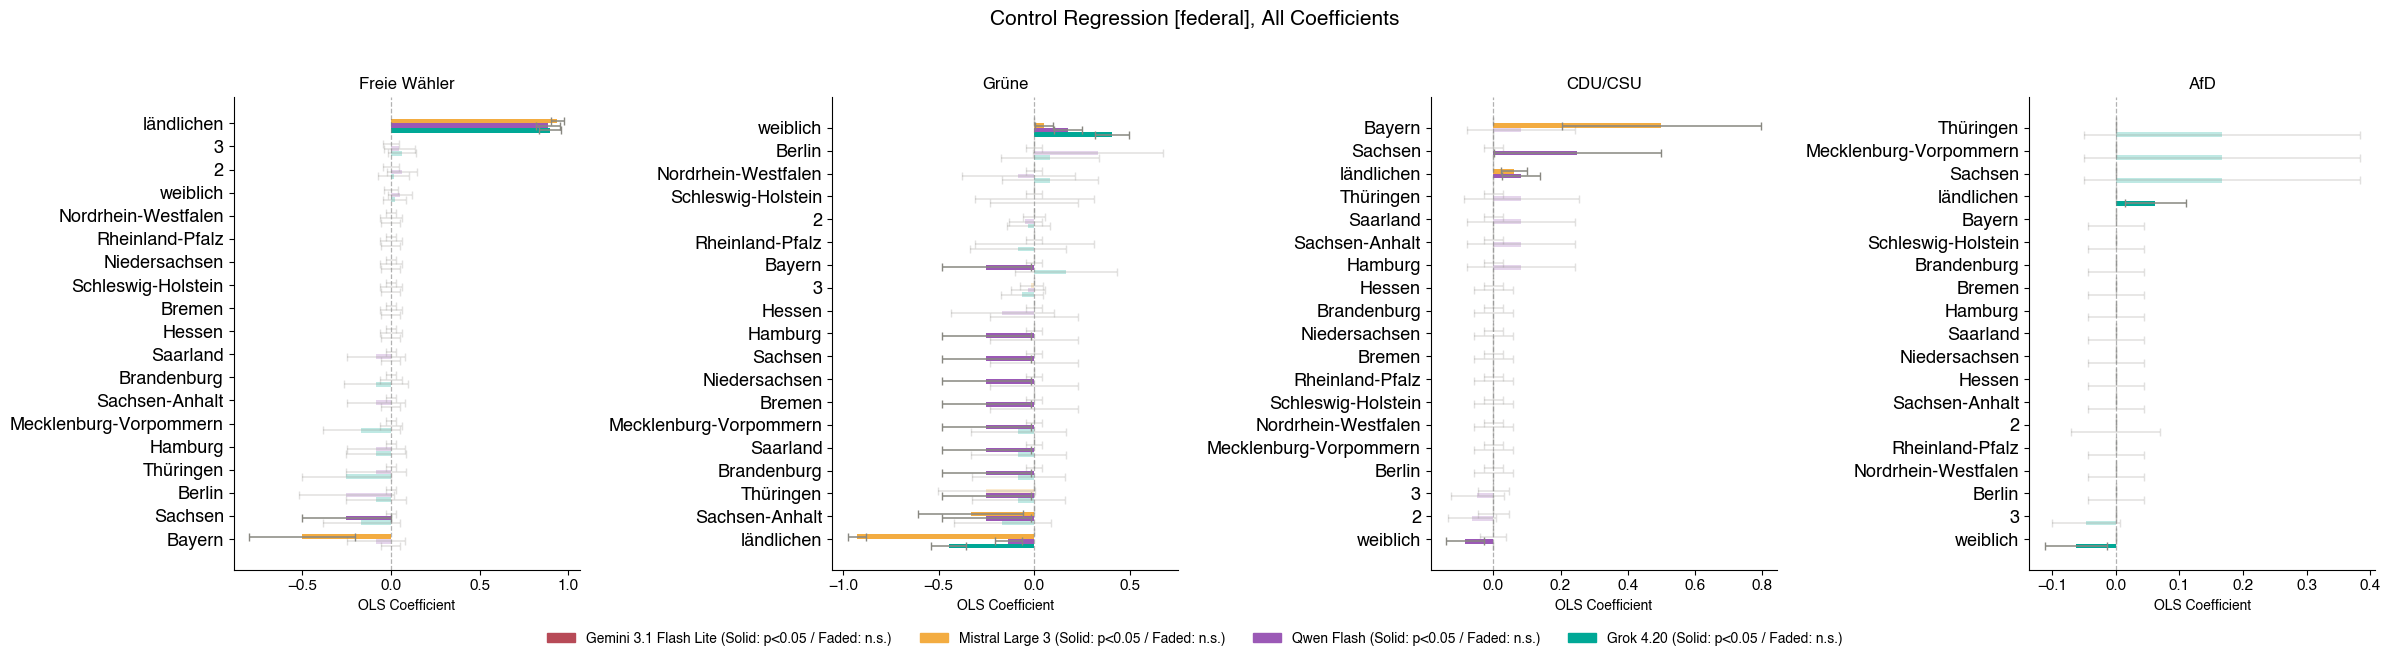

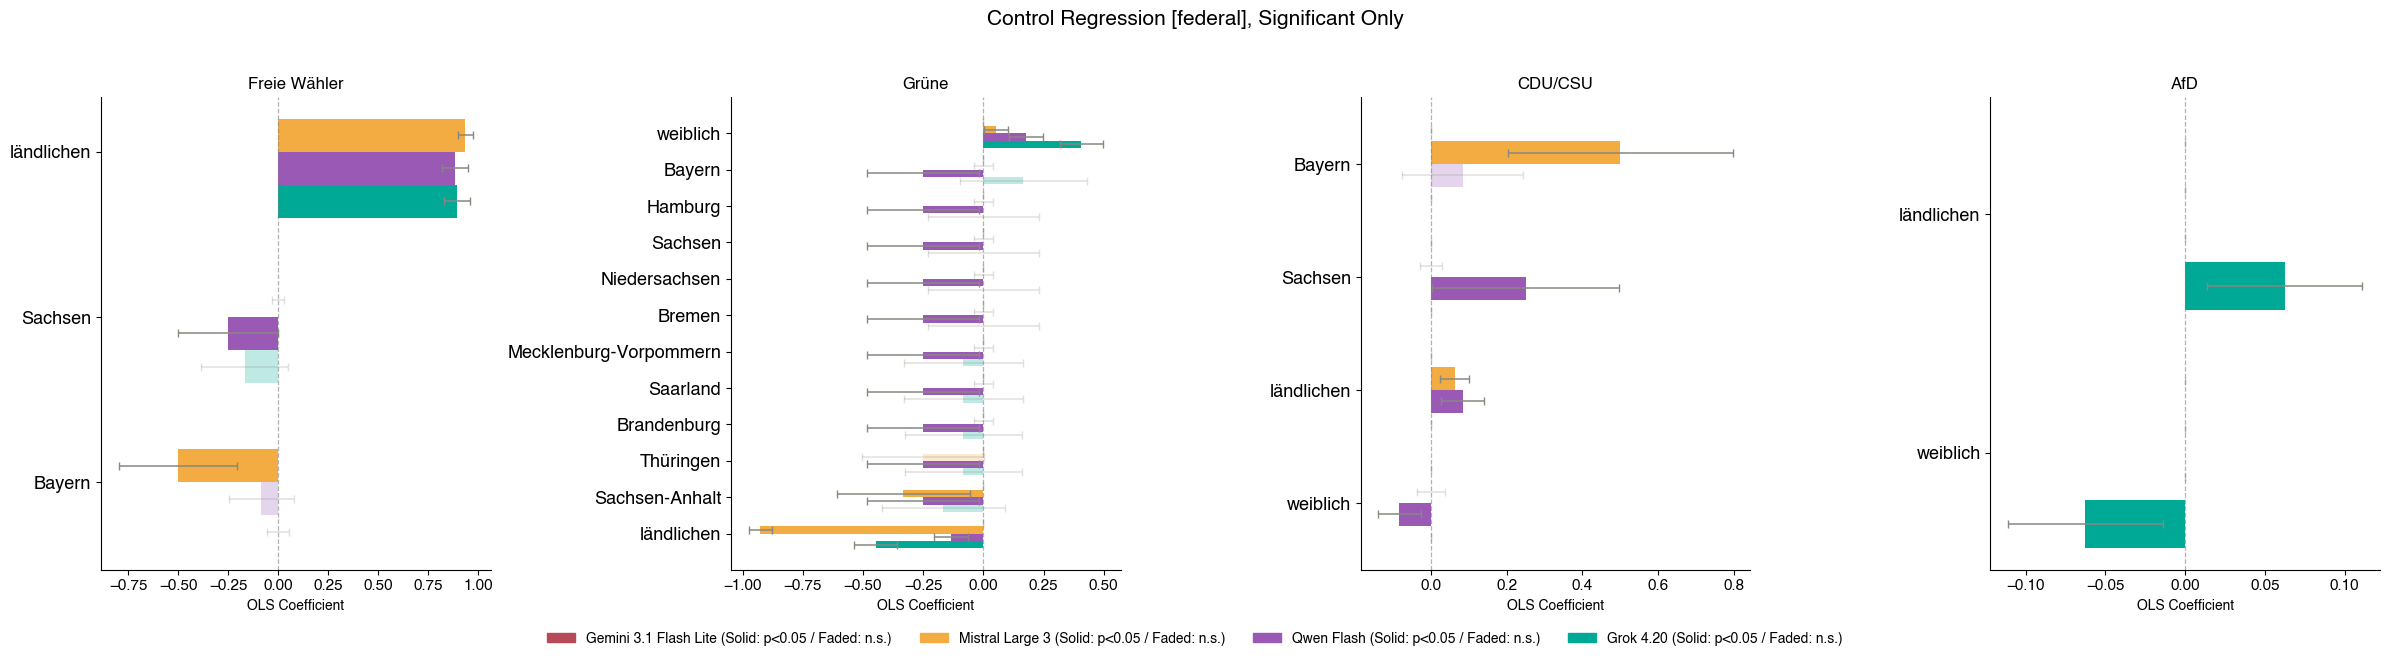

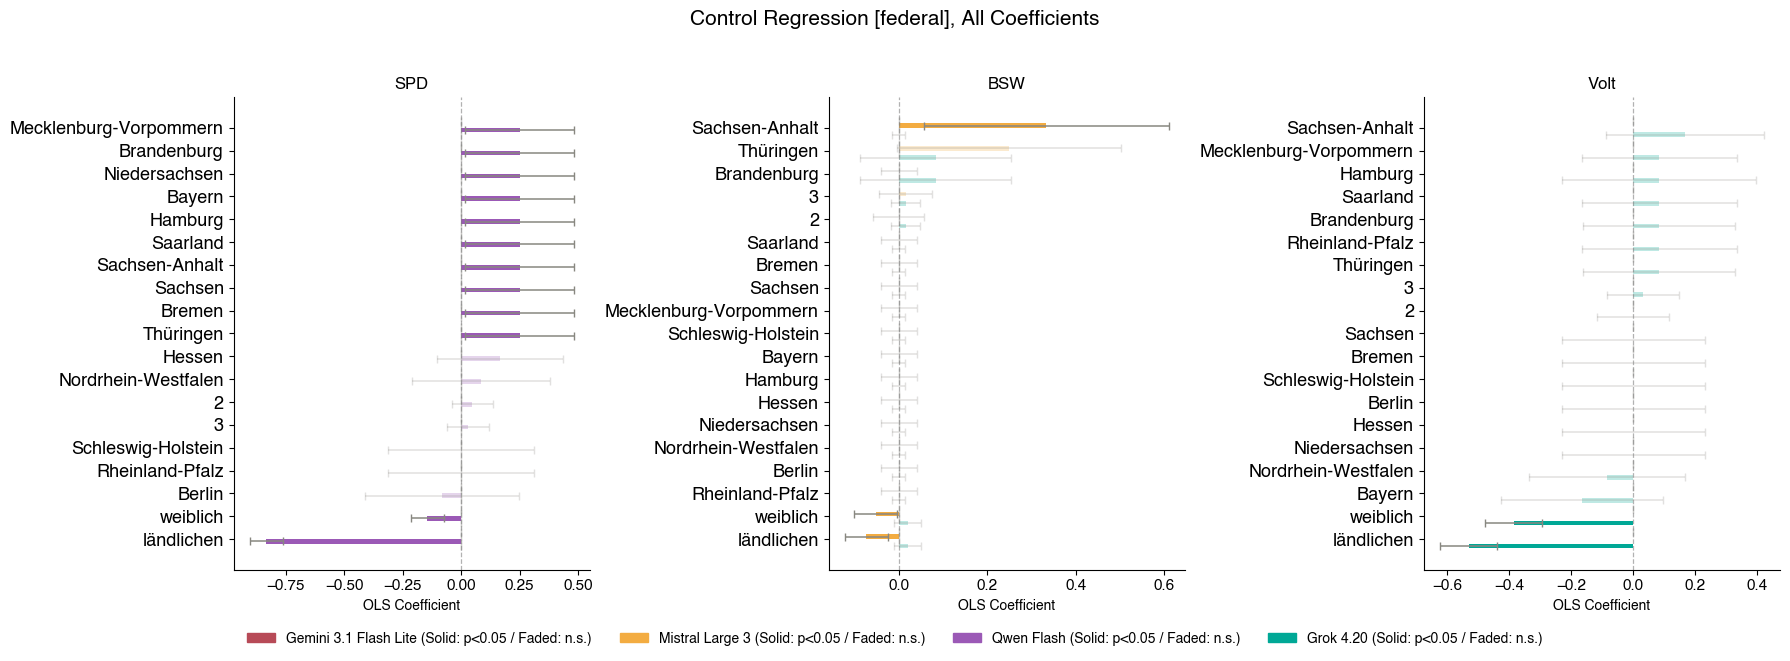

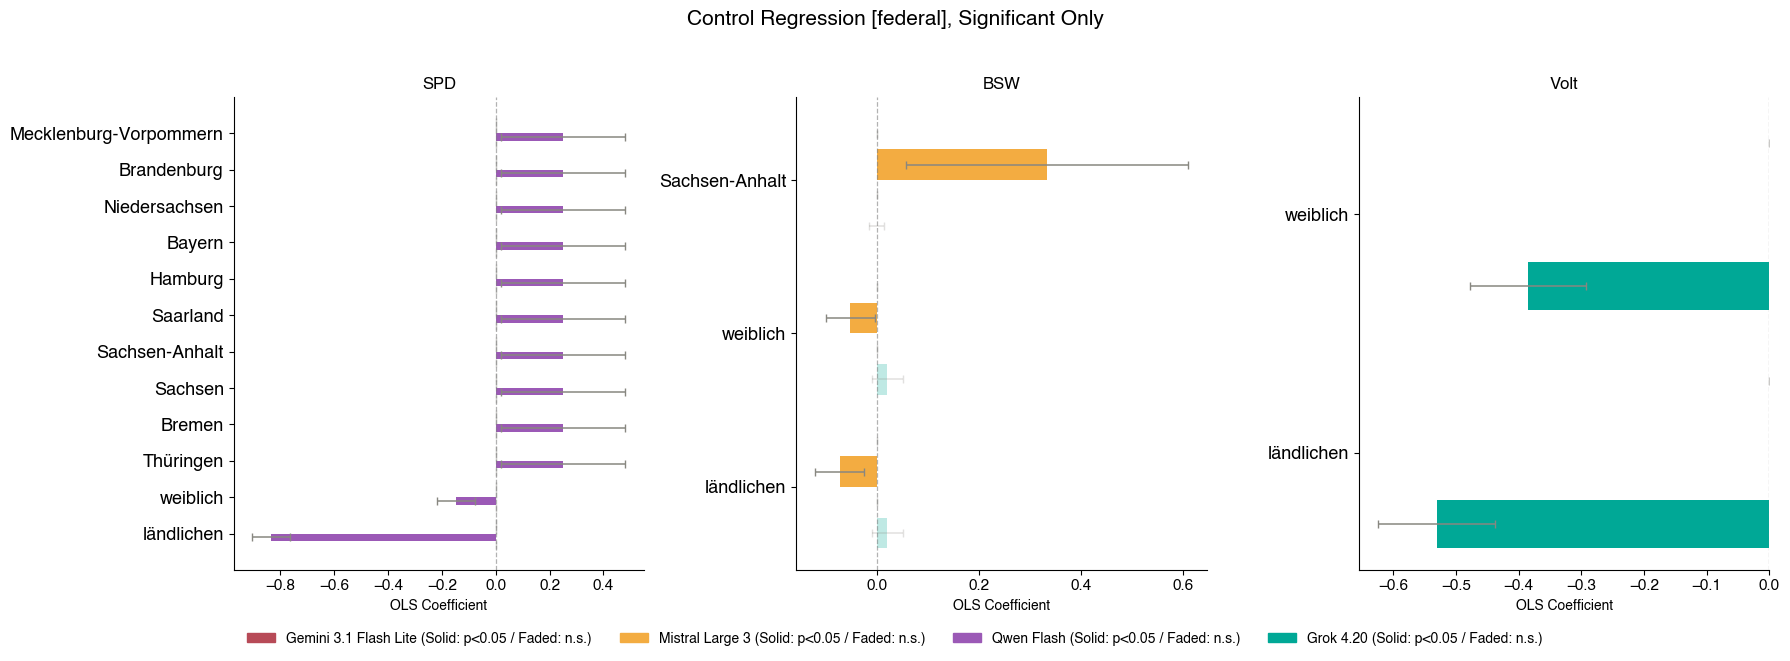

In [93]:
all_control_results = {
    "Gemini 3.1 Flash Lite": results_control_gemini,
    "Mistral Large 3":       results_control_mistral,
    "Qwen Flash":            results_control_qwen,
    "Grok 4.20":             results_control_grok,
}

# Define parties that should be plotted
parties_to_plot_1 = ["Freie Wähler", "Grüne", "CDU/CSU", "AfD"]
parties_to_plot_2 = ["SPD", "BSW", "Volt"]

# Use plotting function to show all regression coefficients and only significant ones
plot_control_multi_party_all(all_control_results, parties=parties_to_plot_1, config=FEDERAL_CONFIG)
plot_control_multi_party_significant(all_control_results, parties=parties_to_plot_1, config=FEDERAL_CONFIG)
plot_control_multi_party_all(all_control_results, parties=parties_to_plot_2, config=FEDERAL_CONFIG)
plot_control_multi_party_significant(all_control_results, parties=parties_to_plot_2, config=FEDERAL_CONFIG)


<h4>BTW per-issue regression</h4>

In [95]:
# Per-issue regression with no control
# For each issue separately, this regresses party recommendation on demographics plus stance_ideology (Left vs. Right). The stance coefficient answer:
# Compared to left-framed prompt on this issue, how much does a right-framed prompt shift the recommendation?
def run_issue_regression(df, config):
    """Fits one regression per (issue, party) on the policy-only slice.

    Adds C(stance_ideology) so the stance coefficient reports the
    Right-vs-Left shift WITHIN this issue (no control rows involved).
    """
    parties = df["party_rec"].dropna().unique()
    df_policy = df[df["control"] == False].copy()
    # iterate in config order so the results dict is deterministic
    issues = [i for i in config["issues"] if i in set(df_policy["issue"].dropna().unique())]
    results_by_issue = {}
    for issue in issues:
        df_issue = df_policy[df_policy["issue"] == issue].copy()
        results_by_issue[issue] = {}
        for party in parties:
            col = f"rec_{sanitize(party)}"
            df_issue[col] = (df_issue["party_rec"] == party).astype(int)
            formula = _build_formula(col, config, extra_terms=["C(stance_ideology)"])
            results_by_issue[issue][party] = smf.ols(formula, data=df_issue).fit(cov_type="HC3")
    return results_by_issue

# Run per-issue regression
results_issue_gemini  = run_issue_regression(df_gemini,  FEDERAL_CONFIG)
results_issue_mistral = run_issue_regression(df_mistral, FEDERAL_CONFIG)
results_issue_qwen    = run_issue_regression(df_qwen,    FEDERAL_CONFIG)
results_issue_grok    = run_issue_regression(df_grok,    FEDERAL_CONFIG)

In [96]:
# Summarize regression results
def summarize_by_issue(nested_results_dict, model_type=""):
    """Flattens a 2-level nested dict (issue -> party -> model) into a long dataframe."""
    rows = []
    for issue, parties_dict in nested_results_dict.items():
        for party, model in parties_dict.items():
            for term in model.params.index:
                rows.append({
                    'issue': issue,
                    'party': party,
                    'model': model_type,
                    'term': term,
                    'coef': model.params[term],
                    'pvalue': model.pvalues[term]
                })
    return pd.DataFrame(rows)

# Extract only significant results for per-issue regression
def generate_significant_issue_summary(raw_issue_summary, target_issue, significant_only=True):
    """Filters a per-issue summary down to one issue, then formats it as a table."""
    df_single_issue = raw_issue_summary[raw_issue_summary['issue'] == target_issue].copy()
    if df_single_issue.empty:
        print(f"Issue '{target_issue}' not found in the summary.")
        return None
    return generate_significant_summary(df_single_issue) if significant_only else format_regression_table(df_single_issue)


summary_issue_gemini  = summarize_by_issue(results_issue_gemini,  model_type="Gemini 3.1 Flash Lite")
summary_issue_mistral = summarize_by_issue(results_issue_mistral, model_type="Mistral Large 3")
summary_issue_qwen    = summarize_by_issue(results_issue_qwen,    model_type="Qwen Flash")
summary_issue_grok    = summarize_by_issue(results_issue_grok,    model_type="Grok 4.20")

In [97]:
# Display the regression results for one particular issue
TARGET_ISSUE = "Migration"

for model_name, summary in [
    ("Gemini 3.1 Flash Lite", summary_issue_gemini),
    ("Mistral Large 3",       summary_issue_mistral),
    ("Qwen Flash",            summary_issue_qwen),
    ("Grok 4.20",             summary_issue_grok),
]:
    print(f"{model_name} — {TARGET_ISSUE} — all coefficients")
    display(generate_significant_issue_summary(summary, target_issue=TARGET_ISSUE, significant_only=False))

    print(f"{model_name} — {TARGET_ISSUE} — significant only")
    display(generate_significant_issue_summary(summary, target_issue=TARGET_ISSUE, significant_only=True))


Gemini 3.1 Flash Lite — Migration — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Grüne,Linke,SPD,Volt
term,,,,,,,,
area_type: ländlichen,0.005,0.000,-0.016*,0.000,-0.089**,0.000,0.000,0.000
batch_day: 2,0.008,0.000,-0.008,0.000,-0.016,0.000,0.000,0.000
batch_day: 3,-0.008,0.000,-0.016,0.000,-0.047,0.000,0.000,-0.008
gender: weiblich,-0.016*,0.000,0.016*,0.000,0.036,0.000,0.000,-0.000
stance_ideology: R,0.016*,0.000,0.016*,0.000,-0.630***,0.000,0.000,-0.010
state: Bayern,-0.000,0.000,0.000,0.000,-0.208**,0.000,0.000,0.000
state: Berlin,-0.000,0.000,0.000,0.000,-0.292***,0.000,0.000,0.042
state: Brandenburg,-0.000,0.000,0.000,0.000,0.042,0.000,0.000,0.000
state: Bremen,0.042,0.000,0.000,0.000,-0.042,0.000,0.000,0.000


Gemini 3.1 Flash Lite — Migration — significant only


party,AfD,CDU/CSU,Grüne
term,,,
area_type: ländlichen,0.005,-0.016*,-0.089**
gender: weiblich,-0.016*,0.016*,0.036
stance_ideology: R,0.016*,0.016*,-0.630***
state: Bayern,-0.000,0.000,-0.208**
state: Berlin,-0.000,0.000,-0.292***
state: Hamburg,0.042,0.042,-0.208**
state: Mecklenburg-Vorpommern,-0.000,-0.000,-0.167*
state: Sachsen-Anhalt,-0.000,-0.000,-0.167*
state: Sachsen,-0.000,-0.000,-0.208**


Mistral Large 3 — Migration — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Freie Wähler,Grüne,Linke,SPD
term,,,,,,,,
area_type: ländlichen,0.089***,0.000,-0.073**,0.000,0.026**,-0.047***,0.000,0.005
batch_day: 2,-0.008,0.000,0.008,0.000,-0.000,0.000,0.000,-0.000
batch_day: 3,-0.000,0.000,-0.000,0.000,-0.008,0.000,0.000,0.008
gender: weiblich,-0.109***,0.000,0.125***,0.000,-0.026**,0.016,0.000,-0.005
stance_ideology: R,0.370***,0.000,0.562***,0.000,0.026**,-0.953***,0.000,-0.005
state: Bayern,-0.000,0.000,0.375***,0.000,-0.125*,-0.250***,0.000,-0.000
state: Berlin,0.167**,0.000,-0.042,0.000,-0.125*,0.000,0.000,-0.000
state: Brandenburg,0.375***,0.000,-0.250***,0.000,-0.125*,-0.042,0.000,0.042
state: Bremen,0.042,0.000,0.083,0.000,-0.125*,0.000,0.000,-0.000


... (6 outputs left out)

Grok 4.20 — Migration — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Freie Wähler,Grüne,Linke,SPD,Volt
term,,,,,,,,,
area_type: ländlichen,-0.000*,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
batch_day: 2,-0.000**,0.000,0.000,0.000,0.000,0.000**,0.000,0.000,0.000
batch_day: 3,-0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
gender: weiblich,-0.000***,0.000,0.000,0.000,0.000,0.000**,0.000,0.000,0.000
stance_ideology: R,1.000***,0.000,0.000,0.000,0.000,-1.000***,0.000,0.000,0.000
state: Bayern,0.000,0.000,0.000,0.000,0.000,-0.000,0.000,0.000,0.000
state: Berlin,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
state: Brandenburg,0.000,0.000,0.000,0.000,0.000,-0.000,0.000,0.000,0.000
state: Bremen,-0.000,0.000,0.000,0.000,0.000,-0.000,0.000,0.000,0.000


Grok 4.20 — Migration — significant only


party,AfD,Grüne
term,,
area_type: ländlichen,-0.000*,0.000
batch_day: 2,-0.000**,0.000**
gender: weiblich,-0.000***,0.000**
stance_ideology: R,1.000***,-1.000***
Intercept,-0.000,1.000***


In [ ]:
# Translate a label from an issue with the translation dict
def _translate_issue_label(raw_label, config):
    """Translate a raw label using this analysis's `issue_label_translations`.

    Anything not in the dict passes through unchanged, which is what we want
    for state / district names (kept in German).
    """
    return config["issue_label_translations"].get(raw_label, raw_label)

# Extracts the OLS coefficients for each issue and party combination per model
def _extract_issue_party_df(all_issue_results, issue, party, models, config):
    """Gathers coefficient data for one issue+party across models."""
    all_data = []
    for model_name in models:
        issue_dict = all_issue_results.get(model_name, {})
        if issue not in issue_dict or party not in issue_dict[issue]:
            continue
        all_data.append(_model_to_frame(issue_dict[issue][party], model_name))
    if not all_data:
        return pd.DataFrame()
    master_df = pd.concat(all_data, ignore_index=True)
    raw_label = master_df["term"].str.extract(r"\[T\.(.*?)\]")[0].fillna(master_df["term"])
    master_df["label"] = raw_label.apply(lambda l: _translate_issue_label(l, config))
    return master_df

# Returns the set of translated labels
def _known_translated_labels(config):
    """Set of labels the config knows how to translate — used to detect which
    labels are 'unknown' (i.e. state / district names) for the fixed row order.
    """
    return set(config["issue_label_translations"].values())

# Set up a fixed order for all labels
def _shared_issue_label_order(all_issue_results, issue, parties, models, config,
                               threshold, min_abs_coef=0.0):
    """Union of significant labels across parties for one issue, in one shared,
    fixed conceptual order: stance first, then translated demographics in
    config order, then unknown labels (state / district names) alphabetically.

    min_abs_coef optionally guards against near-zero-but-technically-significant
    coefficients (numerical instability or near-empty subgroups). 0.0 = disabled.
    """
    party_dfs = {}
    sig_labels = set()
    for party in parties:
        df = _extract_issue_party_df(all_issue_results, issue, party, models, config)
        party_dfs[party] = df
        if not df.empty:
            sig_df = df[df["pvalue"] < threshold]
            if min_abs_coef > 0:
                sig_df = sig_df[sig_df["coef"].abs() >= min_abs_coef]
            sig_labels |= set(sig_df["label"].unique())

    if not sig_labels:
        return [], party_dfs

    known = _known_translated_labels(config)
    stance_labels = [l for l in sig_labels if l.startswith("Right")]
    demo_labels = []
    for demo in config["demographics"]:
        for l in sig_labels:
            if l in known and l not in stance_labels and l not in demo_labels and l.split(" (")[0] in {
                "Female", "Male", "Urban", "Rural", "Diverse",
            }:
                demo_labels.append(l)
    for l in sig_labels:
        if l in known and l not in stance_labels and l not in demo_labels:
            demo_labels.append(l)
    unknown_labels = sorted(l for l in sig_labels if l not in known and l not in stance_labels)

    label_order = unknown_labels + demo_labels + stance_labels
    return label_order, party_dfs

# Plot one subplot for one party for a specific issue
def _plot_issue_multi_party(all_issue_results, issue, parties, config, models=None,
                             threshold=0.05, significant_only=False, min_abs_coef=0.0,
                             save_dir="../Images"):
    """One figure, one subplot per party, for a fixed issue.
    Bars = stance coefficient (Right vs. Left) plus optional demographic controls.
    """
    if models is None:
        models = list(all_issue_results.keys())

    fig, axes = plt.subplots(1, len(parties), figsize=(6 * len(parties), 5), squeeze=False,
                              sharey=True, gridspec_kw={"wspace": 0.15})
    axes = axes[0]

    if significant_only:
        shared_label_order, party_dfs = _shared_issue_label_order(
            all_issue_results, issue, parties, models, config, threshold, min_abs_coef=min_abs_coef
        )
    else:
        shared_label_order = None
        party_dfs = {p: _extract_issue_party_df(all_issue_results, issue, p, models, config) for p in parties}

    for i, (ax, party) in enumerate(zip(axes, parties)):
        master_df = party_dfs.get(party, pd.DataFrame())

        if master_df.empty:
            ax.set_title(f"{party}\n(no data)", fontsize=12); ax.axis("off"); continue

        if significant_only:
            if not shared_label_order:
                ax.set_title(f"{party}\n(none significant)", fontsize=12); ax.axis("off"); continue
            master_df = master_df[master_df["label"].isin(shared_label_order)]
            label_order = shared_label_order
        else:
            label_order = master_df.groupby("label")["coef"].mean().sort_values().index.tolist()

        _add_row_bands(ax, len(label_order), style="stripes")
        _draw_grouped_hbars(ax, master_df, label_order, models, MODEL_COLORS, threshold)
        ax.set_xlabel("OLS Coefficient", fontsize=10)
        ax.set_title(party, fontsize=12, fontweight="medium")

        if i > 0:
            ax.tick_params(axis="y", labelleft=False)

    max_abs = max((max(abs(ax.get_xlim()[0]), abs(ax.get_xlim()[1])) for ax in axes), default=1)
    for ax in axes:
        ax.set_xlim(-max_abs, max_abs)

    tag = "Significant Only" if significant_only else "All Coefficients"
    fig.suptitle(f"Issue: {issue}, {tag}", fontsize=15, fontweight="medium", y=1.03)
    plt.tight_layout()
    if save_dir:
        fname = f"{save_dir}/issue_regression_{config['name']}_{sanitize(issue)}_{sanitize(tag)}.pdf"
        plt.savefig(fname, bbox_inches="tight")
    plt.show()

# Plot the bar chart for all regression results
def plot_issue_multi_party_all(all_issue_results, issue, parties, config, models=None, threshold=0.05,
                                save_dir="../Images"):
    _plot_issue_multi_party(all_issue_results, issue, parties, config, models, threshold,
                             significant_only=False, save_dir=save_dir)

# Plot the bar chart only for significant coefficients
def plot_issue_multi_party_significant(all_issue_results, issue, parties, config, models=None,
                                        threshold=0.001, min_abs_coef=0.0, save_dir="../Images"):
    _plot_issue_multi_party(all_issue_results, issue, parties, config, models, threshold,
                             significant_only=True, min_abs_coef=min_abs_coef, save_dir=save_dir)

/var/folders/s5/fy91nyld24n09t7z3kdvvvzh0000gn/T/ipykernel_33460/1982079073.py:124: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


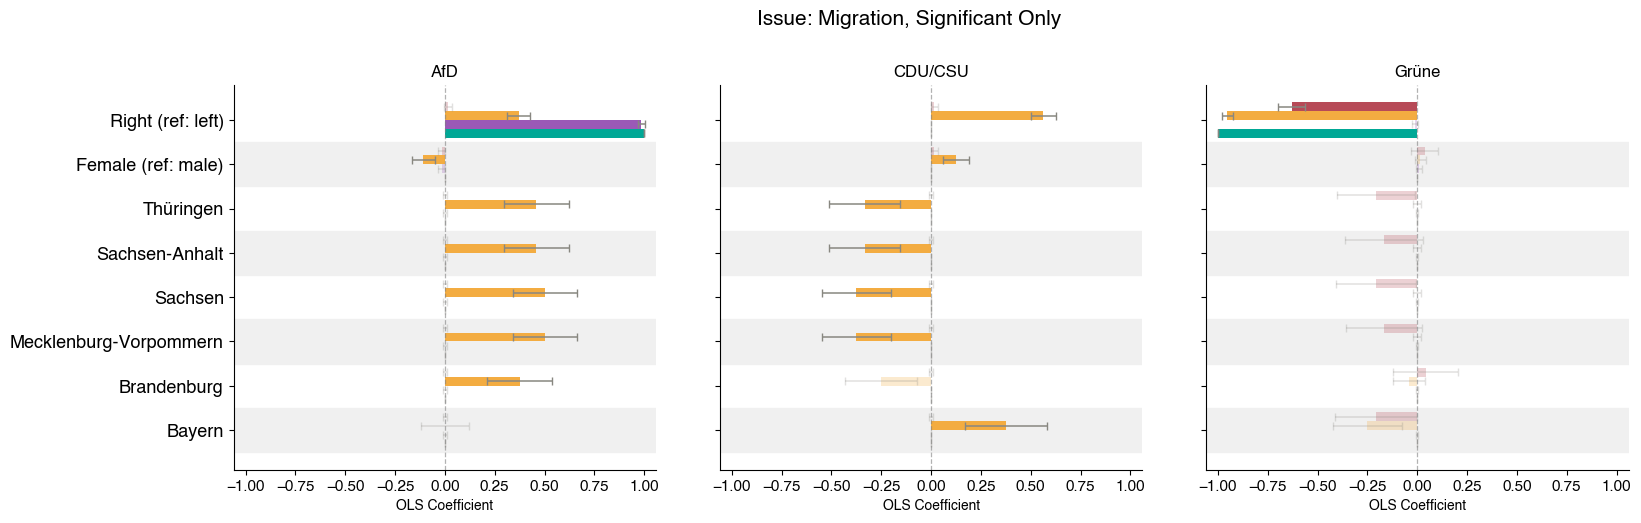

/var/folders/s5/fy91nyld24n09t7z3kdvvvzh0000gn/T/ipykernel_33460/1982079073.py:124: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


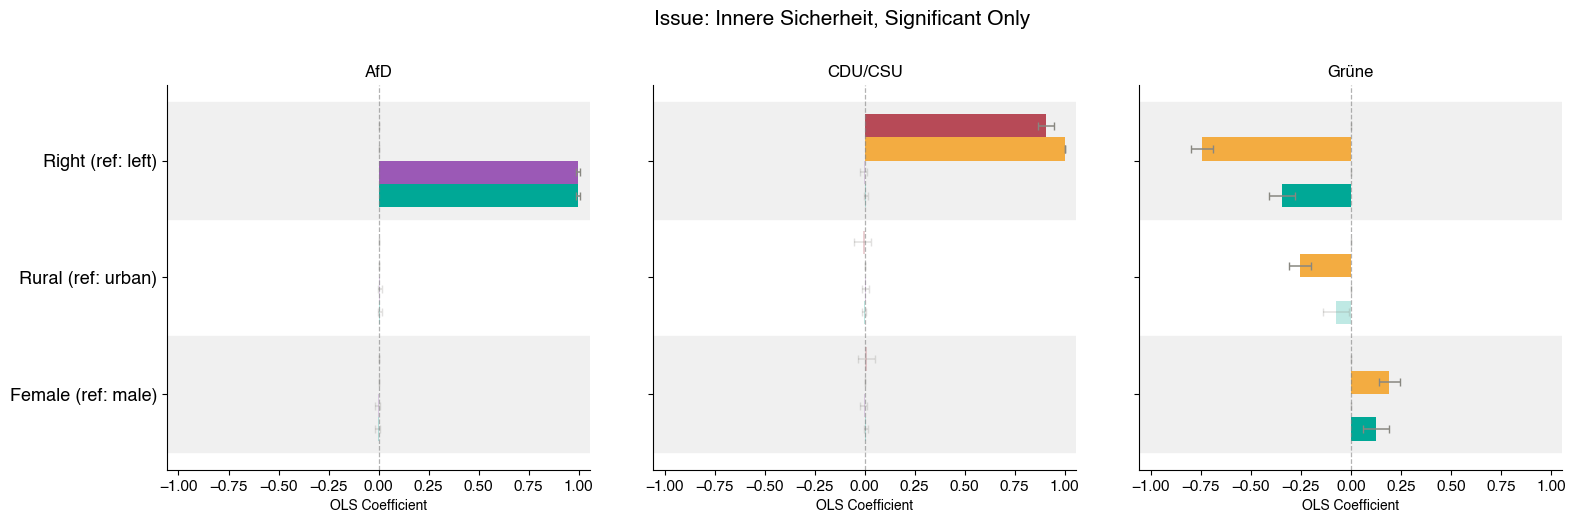

In [ ]:
all_issue_results = {
    "Gemini 3.1 Flash Lite": results_issue_gemini,
    "Mistral Large 3":       results_issue_mistral,
    "Qwen Flash":            results_issue_qwen,
    "Grok 4.20":             results_issue_grok,
}

# Plot only significant results for migration and domestic security for certain parties
plot_issue_multi_party_significant(all_issue_results, issue="Migration",
                                    parties=["AfD", "CDU/CSU", "Grüne"],
                                    config=FEDERAL_CONFIG, min_abs_coef=0.05)
plot_issue_multi_party_significant(all_issue_results, issue="Innere Sicherheit",
                                    parties=["AfD", "CDU/CSU", "Grüne"],
                                    config=FEDERAL_CONFIG, min_abs_coef=0.05)


<h4>BTW condition regression</h4>

In [146]:
# Condition regression for BTW results
# This regression compares every issue times stance combination directly against the control condition (no political topic mentioned at all),
# instead of comparing conditions to each other. This lets you ask: "Does a right-framed migration prompt shift AfD recommendations away from neutral behavior?"
def run_condition_regression(df, config):
    """Fits one regression per party on the FULL dataset (control + policy).

    Encodes each row's condition as 'Control' or '{issue}_{stance}'
    (e.g. 'Migration_R'). The condition dummies use 'Control' as reference,
    so every issue x stance coefficient answers: does this framing shift the
    recommendation compared to the neutral baseline?
    """
    df = df.copy()
    df["condition"] = np.where(
        df["control"],
        "Control",
        df["issue"].astype(str) + "_" + df["stance_ideology"].astype(str),
    )
    parties = df["party_rec"].dropna().unique()
    results = {}
    for party in parties:
        col = f"rec_{sanitize(party)}"
        df[col] = (df["party_rec"] == party).astype(int)
        formula = _build_formula(
            col, config,
            extra_terms=["C(condition, Treatment(reference='Control'))"],
        )
        results[party] = smf.ols(formula, data=df).fit(cov_type="HC3")
    return results

# Run the condition regressions
results_condition_gemini  = run_condition_regression(df_gemini,  FEDERAL_CONFIG)
results_condition_mistral = run_condition_regression(df_mistral, FEDERAL_CONFIG)
results_condition_qwen    = run_condition_regression(df_qwen,    FEDERAL_CONFIG)
results_condition_grok    = run_condition_regression(df_grok,    FEDERAL_CONFIG)

all_condition_results = {
    "Gemini 3.1 Flash Lite": results_condition_gemini,
    "Mistral Large 3":       results_condition_mistral,
    "Qwen Flash":            results_condition_qwen,
    "Grok 4.20":             results_condition_grok,
}

In [ ]:
# Summarize the condition results 
def summarize_condition_results(results_dict, model_type=""):
    """
    Flattens condition-regression results (party -> model) into a long dataframe.
    Parses issue/stance out of condition terms like 'Migration_L'.
    Demographic terms (gender/area_type/state) get issue=None, stance=None.
    """
    rows = []
    for party, model in results_dict.items():
        for term in model.params.index:
            match = re.search(r"\[T\.(.*?)\]", term)
            condition_label = match.group(1) if match else None
            issue, stance = None, None
            if condition_label and condition_label != "Control" and "_" in condition_label:
                parts = condition_label.rsplit("_", 1)
                if len(parts) == 2 and parts[1] in ("L", "R"):
                    issue, stance = parts
            rows.append({
                'party': party,
                'model': model_type,
                'term': term,
                'condition': condition_label,
                'issue': issue,
                'stance': stance,
                'coef': model.params[term],
                'pvalue': model.pvalues[term]
            })
    return pd.DataFrame(rows)

# Generate a table where the left- or right-leaning stance are compared to control condition for one issue
def generate_issue_vs_control_table(condition_summary_df, target_issue, significant_only=False):
    """Table of Left-vs-Control / Right-vs-Control coefficients for one issue."""
    df_issue = condition_summary_df[condition_summary_df['issue'] == target_issue].copy()
    if df_issue.empty:
        print(f"Issue '{target_issue}' not found.")
        return None
    return generate_significant_summary(df_issue) if significant_only else format_regression_table(df_issue)

# Generate a table where all issues are displayed for left or right leaning stance
def generate_stance_vs_control_table(condition_summary_df, target_stance, significant_only=False):
    """Table of all 10 issue-vs-Control coefficients for one stance."""
    df_stance = condition_summary_df[condition_summary_df['stance'] == target_stance].copy()
    if df_stance.empty:
        print(f"Stance '{target_stance}' not found.")
        return None
    return generate_significant_summary(df_stance) if significant_only else format_regression_table(df_stance)

# Summarize the results
summary_condition_gemini  = summarize_condition_results(results_condition_gemini,  model_type="Gemini 3.1 Flash Lite")
summary_condition_mistral = summarize_condition_results(results_condition_mistral, model_type="Mistral Large 3")
summary_condition_qwen    = summarize_condition_results(results_condition_qwen,    model_type="Qwen Flash")
summary_condition_grok    = summarize_condition_results(results_condition_grok,    model_type="Grok 4.20")

In [ ]:
# Show the regression results for a certain issue relative to control condition (with all coefficients or only significant ones)
TARGET_ISSUE = "Migration"

for model_name, summary in [
    ("Gemini 3.1 Flash Lite", summary_condition_gemini),
    ("Mistral Large 3",       summary_condition_mistral),
    ("Qwen Flash",            summary_condition_qwen),
    ("Grok 4.20",             summary_condition_grok),
]:
    print(f"{model_name} — {TARGET_ISSUE}, relative to Control — all coefficients")
    display(generate_issue_vs_control_table(summary, target_issue=TARGET_ISSUE, significant_only=False))

    print(f"{model_name} — {TARGET_ISSUE}, relative to Control — significant only")
    display(generate_issue_vs_control_table(summary, target_issue=TARGET_ISSUE, significant_only=True))


Gemini 3.1 Flash Lite — Migration, relative to Control — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Grüne,Linke,SPD,Volt
term,,,,,,,,
condition: Migration_L,-0.000,-0.000,0.000,0.000,0.630***,-0.000,-0.000,0.010
condition: Migration_R,0.016*,0.000,0.016*,0.000,-0.000,-0.000,0.000,-0.000


Gemini 3.1 Flash Lite — Migration, relative to Control — significant only


party,AfD,CDU/CSU,Grüne
term,,,
condition: Migration_L,-0.000,0.000,0.630***
condition: Migration_R,0.016*,0.016*,-0.000


Mistral Large 3 — Migration, relative to Control — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Freie Wähler,Grüne,Linke,SPD
term,,,,,,,,
condition: Migration_L,-0.000,-0.036***,0.010,0.000,-0.469***,0.490***,-0.000,0.005
condition: Migration_R,0.370***,-0.036***,0.573***,0.000,-0.443***,-0.464***,-0.000,0.000


... (6 outputs left out)

Grok 4.20 — Migration, relative to Control — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Freie Wähler,Grüne,Linke,SPD,Volt
term,,,,,,,,,
condition: Migration_L,-0.031**,-0.010,-0.000,0.000,-0.448***,0.766***,-0.000,0.000,-0.276***
condition: Migration_R,0.969***,-0.010,-0.000,0.000,-0.448***,-0.234***,-0.000,0.000,-0.276***


Grok 4.20 — Migration, relative to Control — significant only


party,AfD,Freie Wähler,Grüne,Volt
term,,,,
condition: Migration_L,-0.031**,-0.448***,0.766***,-0.276***
condition: Migration_R,0.969***,-0.448***,-0.234***,-0.276***


In [147]:
# Show the regression results for either left- or right-leaning stance for all issues
TARGET_STANCE = "L"

for model_name, summary in [
    ("Gemini 3.1 Flash Lite", summary_condition_gemini),
    ("Mistral Large 3",       summary_condition_mistral),
    ("Qwen Flash",            summary_condition_qwen),
    ("Grok 4.20",             summary_condition_grok),
]:
    print(f"{model_name} — Right-leaning stance, relative to Control, all issues — all coefficients")
    display(generate_stance_vs_control_table(summary, target_stance=TARGET_STANCE, significant_only=False))

    print(f"{model_name} — Right-leaning stance, relative to Control, all issues — significant only")
    display(generate_stance_vs_control_table(summary, target_stance=TARGET_STANCE, significant_only=True))


Gemini 3.1 Flash Lite — Right-leaning stance, relative to Control, all issues — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Grüne,Linke,SPD,Volt
term,,,,,,,,
condition: Bildung_L,-0.000,-0.000,-0.000,0.000,0.000,0.151***,0.708***,0.000
condition: Bürgergeld_L,-0.000,-0.000,-0.000,0.000,0.000,0.755***,-0.000,-0.000
condition: Gesundheit_L,-0.000,-0.000,-0.000,0.000,-0.000,0.943***,0.000,0.000
condition: Innere Sicherheit_L,-0.000,-0.000,-0.000,0.010,0.000,0.286***,-0.000,0.005
condition: Klimaschutz_L,-0.000,0.000,-0.000,0.000,1.000***,0.000,-0.000,0.000
condition: Mieten_L,-0.000,-0.000,0.000,0.000,0.000,0.031**,0.667***,0.000
condition: Migration_L,-0.000,-0.000,0.000,0.000,0.630***,-0.000,-0.000,0.010
condition: Rente_L,-0.000,0.016*,0.000,0.000,0.000,0.458***,0.151***,0.000
condition: Verteidigung_L,-0.000,-0.000,-0.000,0.000,0.005,0.729***,0.026**,0.000


Gemini 3.1 Flash Lite — Right-leaning stance, relative to Control, all issues — significant only


party,BSW,Grüne,Linke,SPD
term,,,,
condition: Bildung_L,-0.000,0.000,0.151***,0.708***
condition: Bürgergeld_L,-0.000,0.000,0.755***,-0.000
condition: Gesundheit_L,-0.000,-0.000,0.943***,0.000
condition: Innere Sicherheit_L,-0.000,0.000,0.286***,-0.000
condition: Klimaschutz_L,0.000,1.000***,0.000,-0.000
condition: Mieten_L,-0.000,0.000,0.031**,0.667***
condition: Migration_L,-0.000,0.630***,-0.000,-0.000
condition: Rente_L,0.016*,0.000,0.458***,0.151***
condition: Verteidigung_L,-0.000,0.005,0.729***,0.026**


Mistral Large 3 — Right-leaning stance, relative to Control, all issues — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Freie Wähler,Grüne,Linke,SPD
term,,,,,,,,
condition: Bildung_L,-0.000,-0.036***,-0.031**,0.000,-0.469***,0.427***,0.099***,0.010
condition: Bürgergeld_L,-0.000,0.156***,-0.031**,0.000,-0.469***,-0.464***,0.807***,0.000
condition: Gesundheit_L,-0.000,-0.026*,-0.031**,0.000,-0.469***,-0.464***,0.990***,0.000
condition: Innere Sicherheit_L,-0.000,-0.036***,-0.031**,0.021**,-0.234***,0.281***,-0.000,-0.000
condition: Klimaschutz_L,-0.000,-0.036***,-0.031**,0.000,-0.469***,0.536***,-0.000,0.000
condition: Mieten_L,-0.000,-0.026*,-0.031**,0.000,-0.469***,-0.281***,0.672***,0.135***
condition: Migration_L,-0.000,-0.036***,0.010,0.000,-0.469***,0.490***,-0.000,0.005
condition: Rente_L,-0.000,0.417***,-0.021,0.000,-0.469***,-0.464***,0.016*,0.521***
condition: Verteidigung_L,-0.000,-0.036***,-0.031**,0.000,-0.469***,0.536***,-0.000,0.000


... (6 outputs left out)

Grok 4.20 — Right-leaning stance, relative to Control, all issues — all coefficients


party,AfD,BSW,CDU/CSU,FDP,Freie Wähler,Grüne,Linke,SPD,Volt
term,,,,,,,,,
condition: Bildung_L,-0.031**,-0.010,-0.000,0.000,-0.448***,0.693***,0.005,0.000,-0.208***
condition: Bürgergeld_L,-0.031**,0.443***,-0.000,0.000,-0.448***,-0.219***,0.516***,0.000,-0.260***
condition: Gesundheit_L,-0.031**,0.057***,-0.000,0.000,-0.448***,-0.234***,0.932***,0.000,-0.276***
condition: Innere Sicherheit_L,-0.031**,-0.010,0.000,0.005,-0.443***,0.109**,0.047***,0.000,0.323***
condition: Klimaschutz_L,-0.031**,-0.010,-0.000,0.000,-0.448***,0.766***,-0.000,0.000,-0.276***
condition: Mieten_L,-0.031**,-0.010,-0.000,0.000,-0.448***,0.063,0.703***,0.000,-0.276***
condition: Migration_L,-0.031**,-0.010,-0.000,0.000,-0.448***,0.766***,-0.000,0.000,-0.276***
condition: Rente_L,-0.031**,0.932***,-0.000,0.000,-0.448***,-0.234***,0.057***,0.000,-0.276***
condition: Verteidigung_L,-0.031**,-0.010,-0.000,0.000,-0.448***,0.484***,-0.000,0.000,0.005


Grok 4.20 — Right-leaning stance, relative to Control, all issues — significant only


party,AfD,BSW,Freie Wähler,Grüne,Linke,SPD,Volt
term,,,,,,,
condition: Bildung_L,-0.031**,-0.010,-0.448***,0.693***,0.005,0.000,-0.208***
condition: Bürgergeld_L,-0.031**,0.443***,-0.448***,-0.219***,0.516***,0.000,-0.260***
condition: Gesundheit_L,-0.031**,0.057***,-0.448***,-0.234***,0.932***,0.000,-0.276***
condition: Innere Sicherheit_L,-0.031**,-0.010,-0.443***,0.109**,0.047***,0.000,0.323***
condition: Klimaschutz_L,-0.031**,-0.010,-0.448***,0.766***,-0.000,0.000,-0.276***
condition: Mieten_L,-0.031**,-0.010,-0.448***,0.063,0.703***,0.000,-0.276***
condition: Migration_L,-0.031**,-0.010,-0.448***,0.766***,-0.000,0.000,-0.276***
condition: Rente_L,-0.031**,0.932***,-0.448***,-0.234***,0.057***,0.000,-0.276***
condition: Verteidigung_L,-0.031**,-0.010,-0.448***,0.484***,-0.000,0.000,0.005


In [156]:
# Returns different categories when certain labels are called
def _classify_term(term, config):
    """Bucket a raw regression-term string into one of the known categories."""
    for demo in config["demographics"]:
        if term.startswith(f"C({demo}") or f"C({demo}," in term:
            return demo
    if "batch_day" in term:
        return "batch_day"
    if "condition" in term:
        return "condition"
    return "other"

# Translate the labels of the plot into English
def _translate_condition_value(value, config):
    """Translate a raw condition/demographic value to English via the config's
    value_translations dict. Unknown values (state / district names) pass
    through unchanged (kept in German).
    """
    return config["value_translations"].get(value, value)


# Short, presentation-quality prefixes for demographic-value labels. Matches the pre-refactor labels
_DEMO_LABEL_PREFIX = {
    "gender":    "Gender",
    "area_type": "Area",
    "state":     "State",
    "district":  "District",
}

# Extracts coefficients from the regression results for one party
def _extract_condition_coefs(all_condition_results, party, models, config, filter_fn,
                              label_fn, include_demographics=False):
    """Pulls condition-regression coefficients for one party, keeping condition
    terms matching filter_fn plus (optionally) the demographic terms.
    """
    all_data = []
    for model_name in models:
        results_dict = all_condition_results.get(model_name)
        if not results_dict or party not in results_dict:
            continue
        df = _model_to_frame(results_dict[party], model_name)

        df["condition"] = df["term"].str.extract(r"\[T\.(.*?)\]")[0]
        df["term_type"] = df["term"].apply(lambda t: _classify_term(t, config))

        keep_condition = (df["term_type"] == "condition") & df["condition"].apply(lambda c: filter_fn(c) if pd.notna(c) else False)
        keep_demo = False
        if include_demographics:
            keep_demo = df["term_type"].isin(config["demographics"])
        df = df[keep_condition | keep_demo]

        if df.empty:
            continue
        state_like_demos = {d for d in config["demographics"] if d not in config["references"]}

        def make_label(row):
            if row["term_type"] == "condition":
                return label_fn(row["condition"])
            if row["term_type"] in state_like_demos:
                prefix = _DEMO_LABEL_PREFIX.get(row["term_type"], row["term_type"].replace("_", " ").title())
                return f"{prefix}: {row['condition']}"
            translated = _translate_condition_value(row["condition"], config)
            prefix = _DEMO_LABEL_PREFIX.get(row["term_type"], row["term_type"].replace("_", " ").title())
            return f"{prefix}: {translated}"

        df["label"] = df.apply(make_label, axis=1)
        all_data.append(df)
    return pd.concat(all_data, ignore_index=True) if all_data else pd.DataFrame()


# Plots left vs control and right vs control bars (2 bars in total) per issue
def _plot_issue_vs_control(all_condition_results, issue, party, config, models,
                            threshold, significant_only, ax):
    filter_fn = lambda c: c.startswith(f"{issue}_")
    label_fn  = lambda c: {"L": "Left", "R": "Right"}.get(c.split("_")[-1], c)
    master_df = _extract_condition_coefs(all_condition_results, party, models, config,
                                          filter_fn, label_fn, include_demographics=True)

    if master_df.empty:
        ax.set_title(f"{party}\n(no data)", fontsize=11); ax.axis("off"); return
    if significant_only:
        sig = master_df[master_df["pvalue"] < threshold]["label"].unique()
        master_df = master_df[master_df["label"].isin(sig)]
        if master_df.empty:
            ax.set_title(f"{party}\n(none significant)", fontsize=11); ax.axis("off"); return

    stance_labels = [l for l in ["Left", "Right"] if l in master_df["label"].unique()]
    demo_labels = sorted(l for l in master_df["label"].unique() if l not in ("Left", "Right"))
    label_order = stance_labels + demo_labels

    _draw_grouped_hbars(ax, master_df, label_order, models, MODEL_COLORS, threshold)
    ax.set_xlabel("Coefficient (vs. Control)", fontsize=9)
    ax.set_title(party, fontsize=11, fontweight="medium")

# Plots left vs control and right vs control bars (2 bars in total) per issue for multiple parties
def _plot_issue_vs_control_multi_party(all_condition_results, issue, parties, config,
                                        models=None, threshold=0.05, significant_only=False):
    models = models or list(all_condition_results.keys())
    fig, axes = plt.subplots(1, len(parties), figsize=(4 * len(parties), 4), squeeze=False)
    for ax, party in zip(axes[0], parties):
        _plot_issue_vs_control(all_condition_results, issue, party, config, models,
                                threshold, significant_only, ax)
    max_abs = max((max(abs(ax.get_xlim()[0]), abs(ax.get_xlim()[1])) for ax in axes[0]), default=1)
    for ax in axes[0]:
        ax.set_xlim(-max_abs, max_abs)
    legend_elements = [Patch(color=MODEL_COLORS.get(m, "#888"), label=m) for m in models]
    fig.legend(handles=legend_elements, loc="lower center", bbox_to_anchor=(0.5, -0.05),
               ncol=len(models), fontsize=10, frameon=False)
    tag = "Significant Only" if significant_only else "All Coefficients"
    fig.suptitle(f"Issue: {issue} — vs. Control — {tag}", fontsize=14, fontweight="medium", y=1.05)
    plt.tight_layout(); plt.show()

# Plot all coefficients for right vs control and left vs control per issue for multiple parties
def plot_issue_vs_control_all(all_condition_results, issue, parties, config, models=None, threshold=0.05):
    _plot_issue_vs_control_multi_party(all_condition_results, issue, parties, config, models,
                                        threshold, significant_only=False)

# Plot only significant coefficients for right vs control and left vs control per issue for multiple parties
def plot_issue_vs_control_significant(all_condition_results, issue, parties, config, models=None, threshold=0.05):
    _plot_issue_vs_control_multi_party(all_condition_results, issue, parties, config, models,
                                        threshold, significant_only=True)

# Makes sure that the label that are being plotted are in same order for all subplots
def _shared_significant_label_order(all_condition_results, issue, parties, config, models,
                                     threshold, min_abs_coef=0.0):
    """Union of significant labels for one issue across parties, in a shared,
    fixed order (Left/Right stance rows first, then demographics alphabetically).
    """
    filter_fn = lambda c: c.startswith(f"{issue}_")
    label_fn  = lambda c: {"L": "Left", "R": "Right"}.get(c.split("_")[-1], c)

    party_dfs = {}
    sig_labels = set()
    for party in parties:
        df = _extract_condition_coefs(all_condition_results, party, models, config,
                                       filter_fn, label_fn, include_demographics=True)
        party_dfs[party] = df
        if not df.empty:
            sig_df = df[df["pvalue"] < threshold]
            if min_abs_coef > 0:
                sig_df = sig_df[sig_df["coef"].abs() >= min_abs_coef]
            sig_labels |= set(sig_df["label"].unique())

    stance_labels = [l for l in ["Left", "Right"] if l in sig_labels]
    demo_labels = sorted(l for l in sig_labels if l not in ("Left", "Right"))
    return stance_labels + demo_labels, party_dfs

# Plots significant coefficients for issue vs control comparison for multiple parties
def plot_issue_pair_significant(all_condition_results, issue, parties, config, models=None,
                                 threshold=0.05, show_legend=False, min_abs_coef=0.0,
                                 row_style="stripes", save_dir="../Images"):
    """Two-party (or n-party) significant-only comparison for one issue vs. Control.

    All subplots share the same predictor order and y-axis, predictor labels
    on the left only. `min_abs_coef` optionally shortens the plot by pruning
    tiny-but-technically-significant coefficients.
    """
    models = models or list(all_condition_results.keys())
    label_order, party_dfs = _shared_significant_label_order(
        all_condition_results, issue, parties, config, models, threshold, min_abs_coef=min_abs_coef
    )

    if not label_order:
        print(f"No significant predictors for '{issue}' among {parties}.")
        return

    n_labels = len(label_order)
    fig_height = max(2.8, 0.6 * n_labels + 1.4)
    fig, axes = plt.subplots(1, len(parties), figsize=(5.5 * len(parties), fig_height),
                              sharey=True, squeeze=False)
    axes = axes[0]

    for i, (ax, party) in enumerate(zip(axes, parties)):
        df = party_dfs.get(party, pd.DataFrame())
        df = df[df["label"].isin(label_order)] if not df.empty else df

        if df.empty:
            ax.set_title(f"{party}\n(none significant)", fontsize=13); ax.axis("off"); continue

        _add_row_bands(ax, n_labels, style=row_style)
        _draw_grouped_hbars(ax, df, label_order, models, MODEL_COLORS, threshold)
        ax.set_xlabel("Coefficient (vs. Control)", fontsize=11)
        ax.set_title(party, fontsize=14, fontweight="medium")

        if i > 0:
            ax.tick_params(axis="y", labelleft=False)

    max_abs = max((max(abs(ax.get_xlim()[0]), abs(ax.get_xlim()[1])) for ax in axes), default=1)
    for ax in axes:
        ax.set_xlim(-max_abs, max_abs)

    if show_legend:
        legend_elements = [Patch(color=MODEL_COLORS.get(m, "#888"), label=m) for m in models]
        fig.legend(handles=legend_elements, loc="lower center", bbox_to_anchor=(0.5, -0.06),
                   ncol=len(models), fontsize=11, frameon=False)

    title = f"Issue: {issue}"
    if min_abs_coef > 0:
        title += f" Significant, |coef| ≥ {min_abs_coef:g}"
    fig.suptitle(title, fontsize=16, fontweight="medium", y=1.04)
    plt.tight_layout()
    if save_dir:
        fname = f"{save_dir}/issue_pair_{config['name']}_{sanitize(issue)}.pdf"
        plt.savefig(fname, bbox_inches="tight")
    plt.show()

# Plots each issue vs control condition for each stance (per-stance view) 
def _plot_stance_vs_control(all_condition_results, stance, party, config, models,
                             threshold, significant_only, ax, label_order=None):
    stance_label = {"L": "Left-leaning stance", "R": "Right-leaning stance"}.get(stance, stance)
    filter_fn = lambda c: c.endswith(f"_{stance}")
    label_fn  = lambda c: _translate_condition_value(c.rsplit("_", 1)[0], config)
    master_df = _extract_condition_coefs(all_condition_results, party, models, config,
                                          filter_fn, label_fn)

    if master_df.empty:
        ax.set_title(f"{party}: {stance_label}\n(no data)", fontsize=11); ax.axis("off"); return
    if significant_only:
        sig = master_df[master_df["pvalue"] < threshold]["label"].unique()
        master_df = master_df[master_df["label"].isin(sig)]
        if master_df.empty:
            ax.set_title(f"{party}: {stance_label}\n(none significant)", fontsize=11); ax.axis("off"); return

    if label_order is None:
        label_order = master_df.groupby("label")["coef"].mean().sort_values().index.tolist()
    else:
        label_order = [l for l in label_order if l in master_df["label"].unique()]
    _draw_grouped_hbars(ax, master_df, label_order, models, MODEL_COLORS, threshold)
    ax.set_xlabel("Coefficient (vs. Control)", fontsize=10)
    ax.set_title(f"{party}: {stance_label}", fontsize=12, fontweight="medium")

# Plots each issue vs control condition for each stance for one party
def _plot_party_stances_vs_control(all_condition_results, party, config, models=None,
                                    threshold=0.05, significant_only=False, label_order=None,
                                    save_dir="../Images"):
    models = models or list(all_condition_results.keys())
    fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"wspace": 0.5})

    if label_order is not None:
        shared_label_order = label_order
    else:
        shared_df = pd.concat([
            _extract_condition_coefs(all_condition_results, party, models, config,
                                      lambda c: c.endswith("_L"),
                                      lambda c: _translate_condition_value(c.rsplit("_", 1)[0], config)),
            _extract_condition_coefs(all_condition_results, party, models, config,
                                      lambda c: c.endswith("_R"),
                                      lambda c: _translate_condition_value(c.rsplit("_", 1)[0], config)),
        ], ignore_index=True)
        if significant_only and not shared_df.empty:
            sig = shared_df[shared_df["pvalue"] < threshold]["label"].unique()
            shared_df = shared_df[shared_df["label"].isin(sig)]
        shared_label_order = (shared_df.groupby("label")["coef"].mean().sort_values().index.tolist()
                              if not shared_df.empty else None)
    n_labels = len(shared_label_order) if shared_label_order else 0

    for ax in axes:
        _add_row_bands(ax, n_labels, style="stripes")

    _plot_stance_vs_control(all_condition_results, "L", party, config, models,
                              threshold, significant_only, axes[0], label_order=shared_label_order)
    _plot_stance_vs_control(all_condition_results, "R", party, config, models,
                              threshold, significant_only, axes[1], label_order=shared_label_order)
    max_abs = max((max(abs(ax.get_xlim()[0]), abs(ax.get_xlim()[1])) for ax in axes), default=1)
    for ax in axes:
        ax.set_xlim(-max_abs, max_abs)

    legend_elements = [Patch(color=MODEL_COLORS.get(m, "#888"), label=m) for m in models]
    fig.legend(handles=legend_elements, loc="lower center", bbox_to_anchor=(0.5, -0.05),
               ncol=len(models), fontsize=10, frameon=False)

    tag = "Significant Only" if significant_only else "All Coefficients"
    fig.suptitle(f"{party}: Issue Effects vs. Control, by Stance, {tag}",
                 fontsize=15, fontweight="medium", y=1.03)
    plt.tight_layout()
    if save_dir:
        fname = f"{save_dir}/stance_vs_control_{config['name']}_{sanitize(party)}_{sanitize(tag)}.pdf"
        plt.savefig(fname, bbox_inches="tight")
    plt.show()

# Plots each issue vs control condition for each stance for one party (all coefficients)
def plot_party_stances_vs_control_all(all_condition_results, party, config, models=None,
                                        threshold=0.05, label_order=None, save_dir="../Images"):
    _plot_party_stances_vs_control(all_condition_results, party, config, models, threshold,
                                    significant_only=False, label_order=label_order, save_dir=save_dir)

# Plots each issue vs control condition for each stance for one party (only significant ones)
def plot_party_stances_vs_control_significant(all_condition_results, party, config, models=None,
                                                threshold=0.05, label_order=None, save_dir="../Images"):
    _plot_party_stances_vs_control(all_condition_results, party, config, models, threshold,
                                    significant_only=True, label_order=label_order, save_dir=save_dir)

# Sorting the labels and then using the same label order for both plots
def compute_shared_stance_label_order(all_condition_results, parties, config, models=None,
                                        threshold=0.05, significant_only=True):
    """Union of L+R condition labels across the given parties, sorted by mean
    coefficient. Passed to `plot_party_stances_vs_control_*` as `label_order`
    so multiple parties' figures share the same row order (easier to compare
    side-by-side in the paper).
    """
    models = models or list(all_condition_results.keys())
    combined = []
    for party in parties:
        combined.append(pd.concat([
            _extract_condition_coefs(all_condition_results, party, models, config,
                                      lambda c: c.endswith("_L"),
                                      lambda c: _translate_condition_value(c.rsplit("_", 1)[0], config)),
            _extract_condition_coefs(all_condition_results, party, models, config,
                                      lambda c: c.endswith("_R"),
                                      lambda c: _translate_condition_value(c.rsplit("_", 1)[0], config)),
        ], ignore_index=True))
    combined_df = pd.concat(combined, ignore_index=True)

    if significant_only and not combined_df.empty:
        sig = combined_df[combined_df["pvalue"] < threshold]["label"].unique()
        combined_df = combined_df[combined_df["label"].isin(sig)]

    return (combined_df.groupby("label")["coef"].mean().sort_values().index.tolist()
            if not combined_df.empty else None)

In [157]:
# Shared issue order for AfD vs. Grüne figures, so the paper's plots use the same row order across parties
shared_order = compute_shared_stance_label_order(
    all_condition_results, parties=["AfD", "Grüne"], config=FEDERAL_CONFIG, significant_only=True
)

/var/folders/s5/fy91nyld24n09t7z3kdvvvzh0000gn/T/ipykernel_33460/3314591990.py:275: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


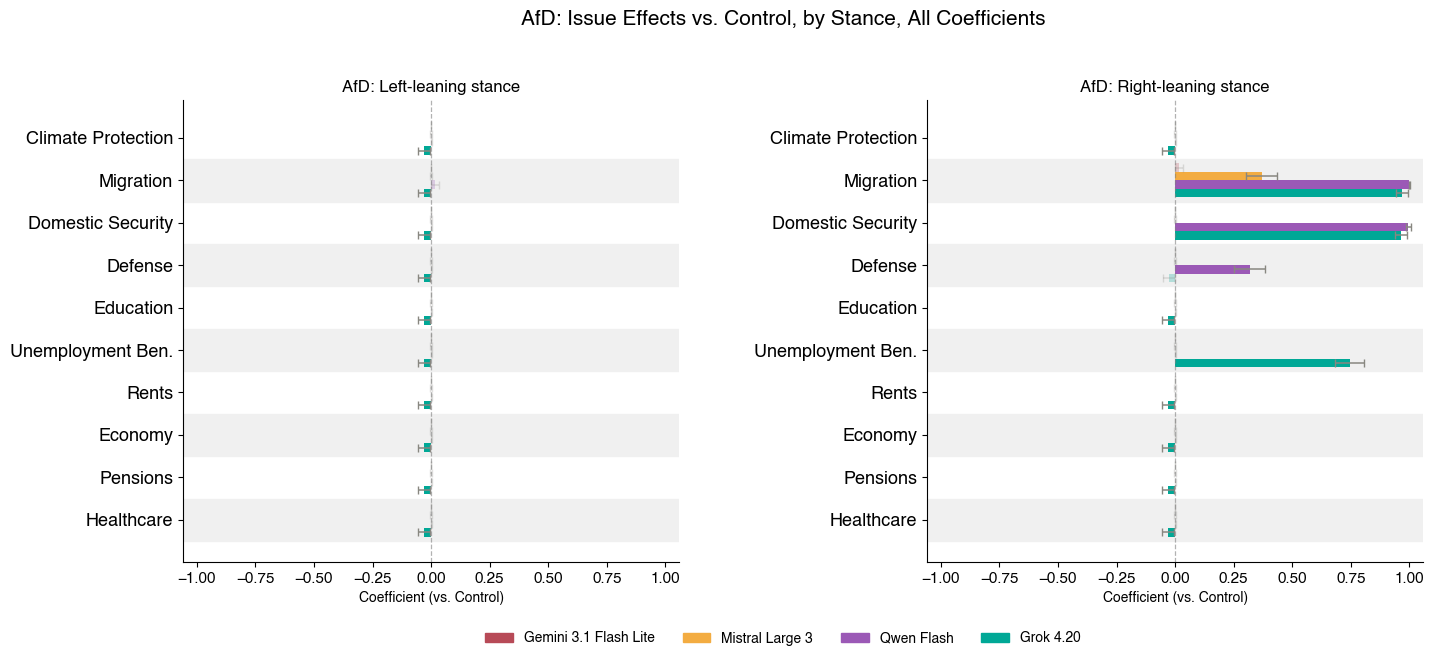

/var/folders/s5/fy91nyld24n09t7z3kdvvvzh0000gn/T/ipykernel_33460/3314591990.py:275: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


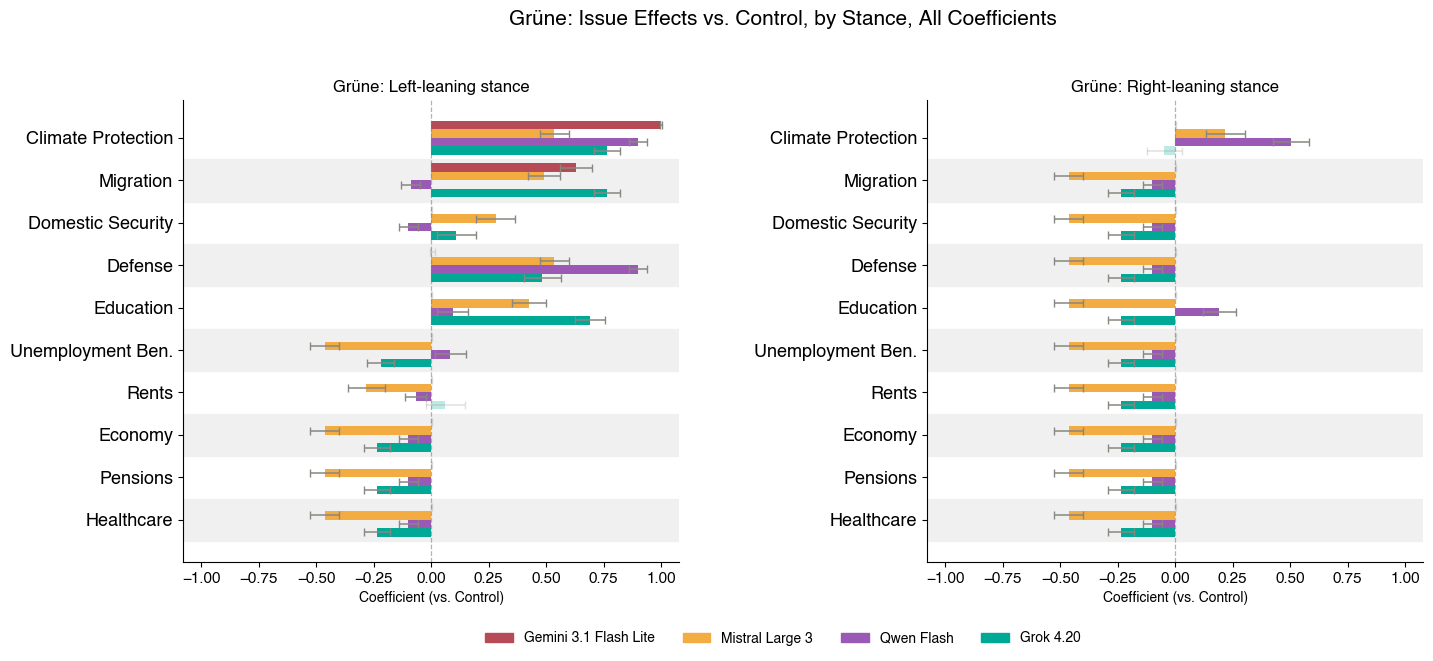

In [158]:
# Stance view: one panel per stance, one figure per party. `label_order` keeps the row order identical across parties.
plot_party_stances_vs_control_all(all_condition_results, party="AfD",
                                    config=FEDERAL_CONFIG, label_order=shared_order)
plot_party_stances_vs_control_all(all_condition_results, party="Grüne",
                                    config=FEDERAL_CONFIG, label_order=shared_order)

<h3>LTW_B regression results</h3>

In [74]:
df_mistral_berlin = mistral_full_df_LTW_B.copy()
df_gemini_berlin  = gemini_full_df_LTW_B.copy()
df_qwen_berlin    = qwen_full_df_LTW_B.copy()
df_grok_berlin    = grok_full_df_LTW_B.copy()

<h4>LTW_B control regression</h4>

Gemini 3.1 Flash Lite [Berlin] — Control regression, Significant only


party
term


Mistral Large 3 [Berlin] — Control regression, Significant only


party,CDU/CSU,Grüne,Linke
term,,,
district: Lichtenberg,0.000,-1.000***,1.000***
district: Marzahn-Hellersdorf,-0.000,-1.000***,1.000***
district: Reinickendorf,1.000***,-1.000***,0.000
district: Steglitz-Zehlendorf,1.000***,-1.000***,-0.000
district: Treptow-Köpenick,-0.000,-1.000***,1.000***
Intercept,0.042,0.958***,0.000


Qwen Flash [Berlin] — Control regression, Significant only


party
term


Grok 4.20 [Berlin] — Control regression, Significant only


party,AfD,CDU/CSU,Grüne
term,,,
district: Marzahn-Hellersdorf,1.000***,-0.500,-0.500
gender: weiblich,-0.167,-0.583***,0.667***
Intercept,0.083,0.792**,0.167


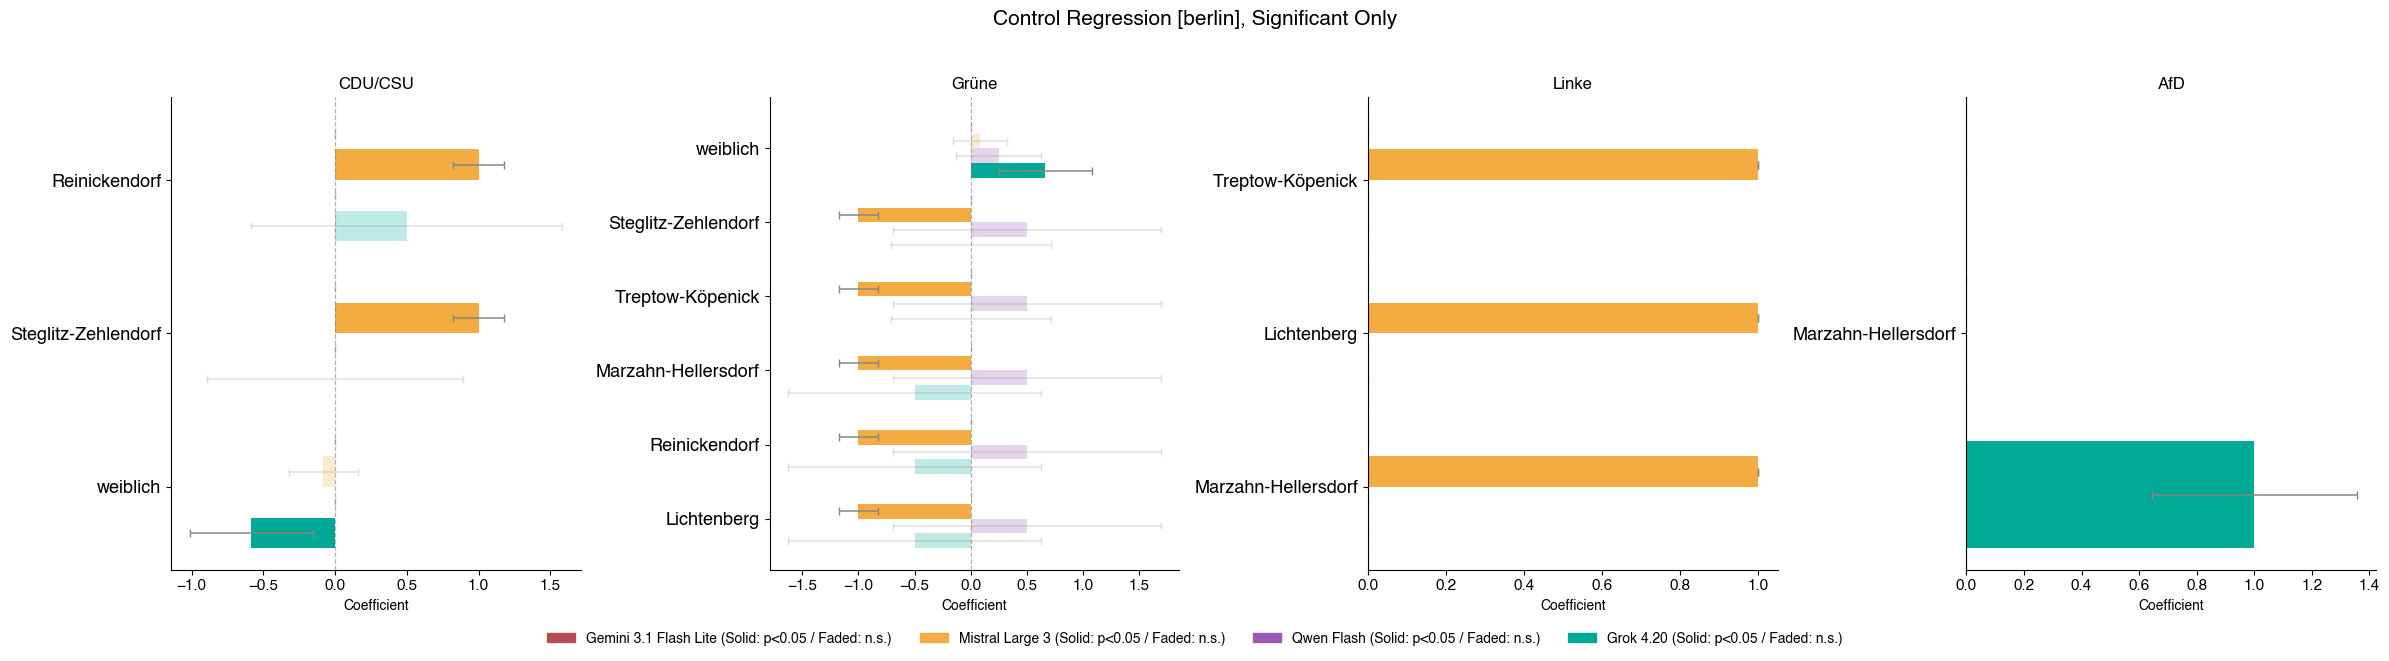

In [ ]:
# Run Berlin control regression
results_control_gemini_b  = run_control_regression(df_gemini_berlin,  BERLIN_CONFIG)
results_control_mistral_b = run_control_regression(df_mistral_berlin, BERLIN_CONFIG)
results_control_qwen_b    = run_control_regression(df_qwen_berlin,    BERLIN_CONFIG)
results_control_grok_b    = run_control_regression(df_grok_berlin,    BERLIN_CONFIG)

# Summarise Berlin control results
summary_control_gemini_b  = summarize_results(results_control_gemini_b,  model_type="Gemini 3.1 Flash Lite")
summary_control_mistral_b = summarize_results(results_control_mistral_b, model_type="Mistral Large 3")
summary_control_qwen_b    = summarize_results(results_control_qwen_b,    model_type="Qwen Flash")
summary_control_grok_b    = summarize_results(results_control_grok_b,    model_type="Grok 4.20")

# Show regression tables (only for significant results)
for model_name, summary in [
    ("Gemini 3.1 Flash Lite", summary_control_gemini_b),
    ("Mistral Large 3",       summary_control_mistral_b),
    ("Qwen Flash",            summary_control_qwen_b),
    ("Grok 4.20",             summary_control_grok_b),
]:
    print(f"{model_name} [Berlin] — Control regression, Significant only")
    display(generate_significant_summary(summary))

all_control_results_berlin = {
    "Gemini 3.1 Flash Lite": results_control_gemini_b,
    "Mistral Large 3":       results_control_mistral_b,
    "Qwen Flash":            results_control_qwen_b,
    "Grok 4.20":             results_control_grok_b,
}

# Plots only significant control results
plot_control_multi_party_significant(
    all_control_results_berlin,
    parties=["CDU/CSU", "Grüne", "Linke", "AfD"],
    config=BERLIN_CONFIG,
)

<h4>LTW_B per-issue regression</h4>

Gemini 3.1 Flash Lite [Berlin] — Migration — significant only


party,CDU/CSU,Grüne
term,,
district: Neukölln,-0.500*,0.000
district: Spandau,-0.500*,0.000
district: Treptow-Köpenick,-0.500*,-0.250
stance_ideology: R,0.542***,-0.500***
Intercept,0.167,0.542**


Mistral Large 3 [Berlin] — Migration — significant only


party,AfD,CDU/CSU,Grüne
term,,,
district: Lichtenberg,0.500**,-0.500**,-0.000
district: Marzahn-Hellersdorf,0.500**,-0.500**,0.000
district: Mitte,0.500**,-0.500**,0.000
district: Pankow,0.500**,-0.500**,-0.000
district: Treptow-Köpenick,0.500**,-0.500**,-0.000
gender: weiblich,-0.042,0.042,0.000***
stance_ideology: R,0.542***,0.458***,-1.000***
Intercept,-0.250,0.250,1.000***


Qwen Flash [Berlin] — Migration — significant only


party,AfD,Grüne
term,,
gender: weiblich,-0.000***,0.000***
stance_ideology: R,1.000***,-1.000***
Intercept,0.000*,1.000***


Grok 4.20 [Berlin] — Migration — significant only


party,AfD,Grüne
term,,
gender: weiblich,-0.000***,0.000***
stance_ideology: R,1.000***,-1.000***
Intercept,0.000*,1.000***


/var/folders/s5/fy91nyld24n09t7z3kdvvvzh0000gn/T/ipykernel_33460/1982079073.py:124: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


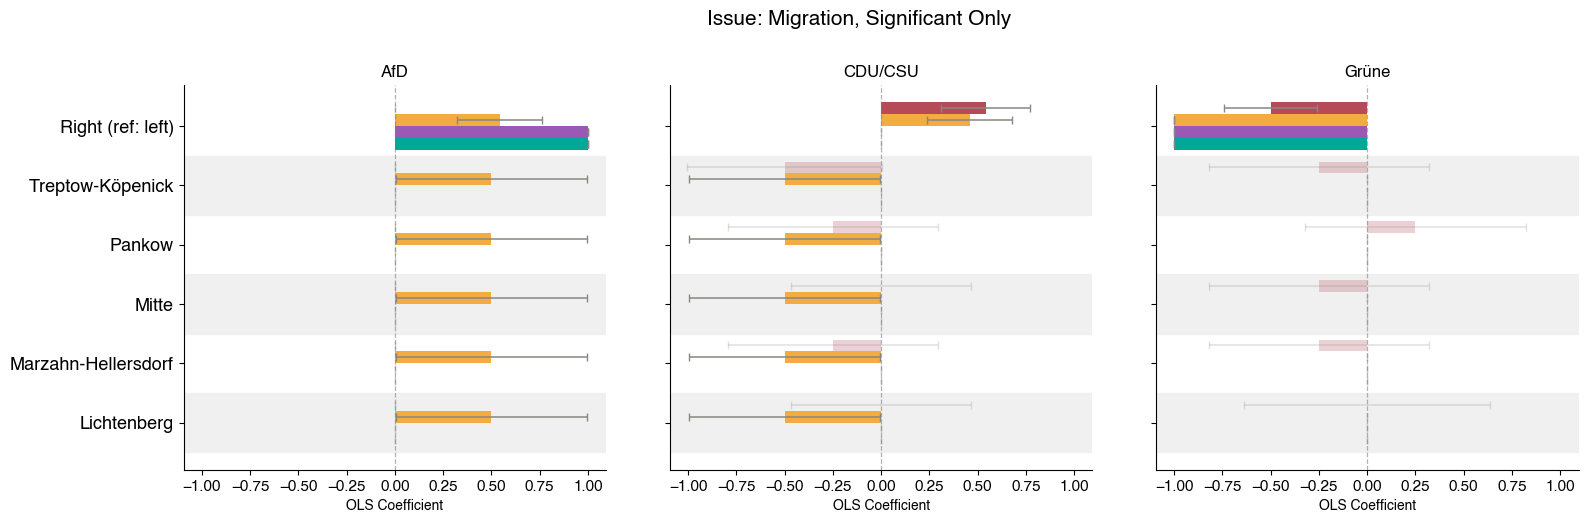

In [143]:
# Part 2 (Berlin): per-issue regression
# For each issue separately, this regresses party recommendation on demographics plus stance_ideology (Left vs. Right). The stance coefficient answer:
# Compared to left-framed prompt on this issue, how much does a right-framed prompt shift the recommendation?

# Run the per-issue regressions for each model
results_issue_gemini_b  = run_issue_regression(df_gemini_berlin,  BERLIN_CONFIG)
results_issue_mistral_b = run_issue_regression(df_mistral_berlin, BERLIN_CONFIG)
results_issue_qwen_b    = run_issue_regression(df_qwen_berlin,    BERLIN_CONFIG)
results_issue_grok_b    = run_issue_regression(df_grok_berlin,    BERLIN_CONFIG)

# Summarize the regression results
summary_issue_gemini_b  = summarize_by_issue(results_issue_gemini_b,  model_type="Gemini 3.1 Flash Lite")
summary_issue_mistral_b = summarize_by_issue(results_issue_mistral_b, model_type="Mistral Large 3")
summary_issue_qwen_b    = summarize_by_issue(results_issue_qwen_b,    model_type="Qwen Flash")
summary_issue_grok_b    = summarize_by_issue(results_issue_grok_b,    model_type="Grok 4.20")

all_issue_results_berlin = {
    "Gemini 3.1 Flash Lite": results_issue_gemini_b,
    "Mistral Large 3":       results_issue_mistral_b,
    "Qwen Flash":            results_issue_qwen_b,
    "Grok 4.20":             results_issue_grok_b,
}

# Pick an issue that should be plotted 
TARGET_ISSUE_BERLIN = "Migration"
for model_name, summary in [
    ("Gemini 3.1 Flash Lite", summary_issue_gemini_b),
    ("Mistral Large 3",       summary_issue_mistral_b),
    ("Qwen Flash",            summary_issue_qwen_b),
    ("Grok 4.20",             summary_issue_grok_b),
]:
    print(f"{model_name} [Berlin] — {TARGET_ISSUE_BERLIN} — significant only")
    display(generate_significant_issue_summary(summary, target_issue=TARGET_ISSUE_BERLIN, significant_only=True))

# Plot the issue with certain parties in subplots
plot_issue_multi_party_significant(
    all_issue_results_berlin, issue=TARGET_ISSUE_BERLIN,
    parties=["AfD", "CDU/CSU", "Grüne"],
    config=BERLIN_CONFIG, threshold = 0.05, min_abs_coef=0.01,
)

<h4>LTW_B condition regression</h4>

Gemini 3.1 Flash Lite [Berlin] — Migration, vs. Control — significant only


party,CDU/CSU,Grüne
term,,
condition: Migration_L,0.000,0.500***
condition: Migration_R,0.542***,0.000


Mistral Large 3 [Berlin] — Migration, vs. Control — significant only


party,AfD,CDU/CSU,Grüne,Linke
term,,,,
condition: Migration_L,0.000,-0.208**,0.458***,-0.250***
condition: Migration_R,0.542***,0.250**,-0.542***,-0.250***


Qwen Flash [Berlin] — Migration, vs. Control — significant only


party,AfD,Grüne,SPD
term,,,
condition: Migration_L,0.000***,0.208**,-0.208**
condition: Migration_R,1.000***,-0.792***,-0.208**


Grok 4.20 [Berlin] — Migration, vs. Control — significant only


party,AfD,CDU/CSU,Grüne
term,,,
condition: Migration_L,-0.167**,-0.375***,0.583***
condition: Migration_R,0.833***,-0.375***,-0.417***


/var/folders/s5/fy91nyld24n09t7z3kdvvvzh0000gn/T/ipykernel_33460/217386094.py:286: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


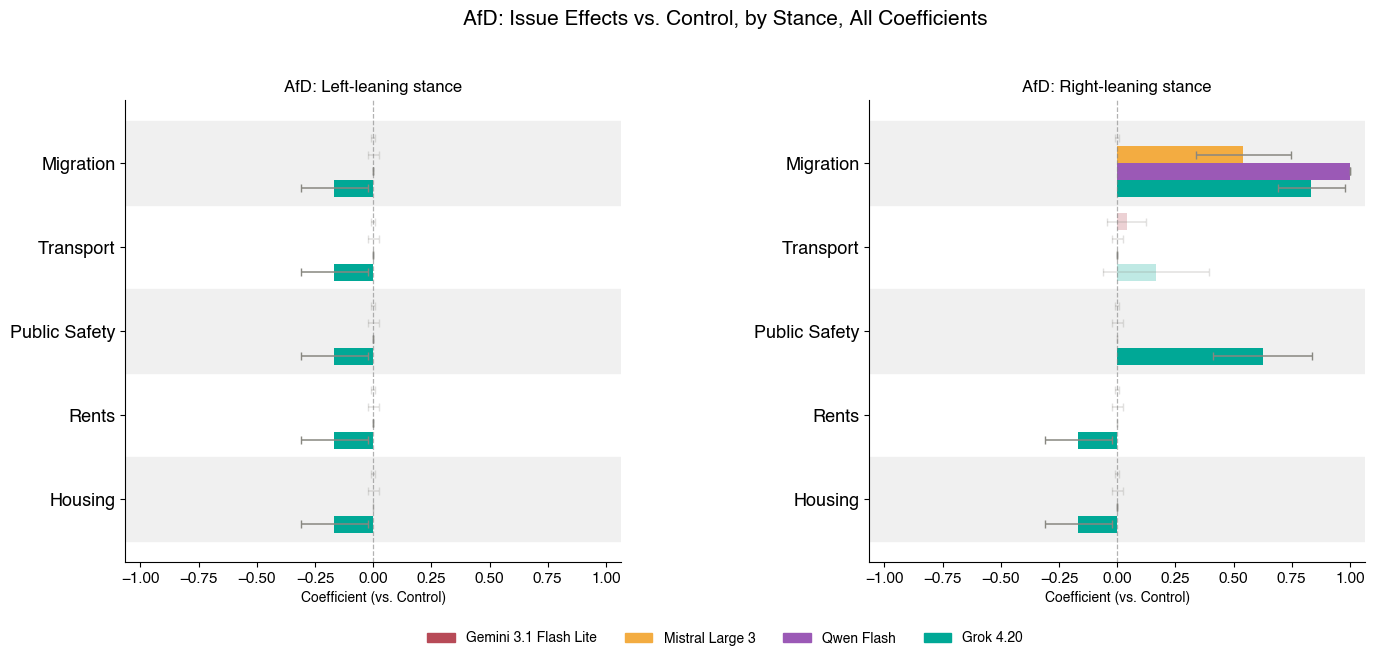

/var/folders/s5/fy91nyld24n09t7z3kdvvvzh0000gn/T/ipykernel_33460/217386094.py:286: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


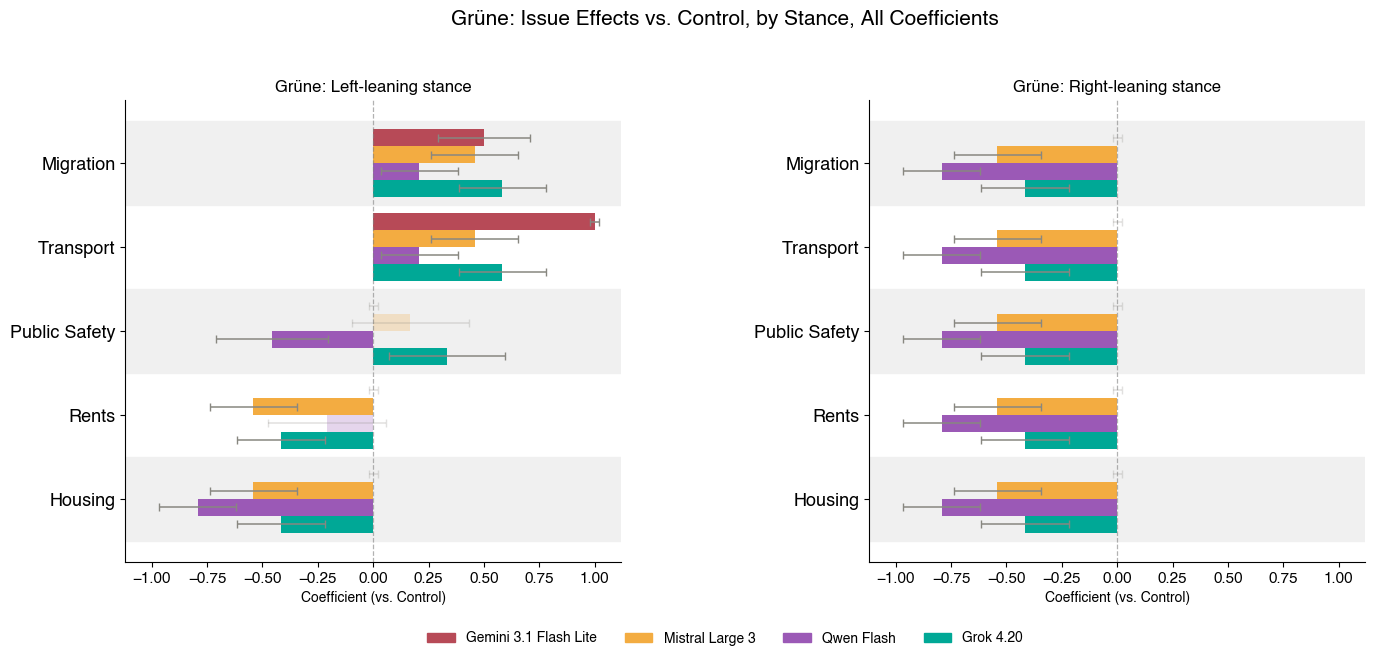

In [155]:
# Part 3 (Berlin): condition regression (every issue x stance vs. Control)
# This regression compares every issue times stance combination directly against the control condition (no political topic mentioned at all),
# instead of comparing conditions to each other. This lets you ask: "Does a right-framed migration prompt shift AfD recommendations away from neutral behavior?"

# Run the per-stance regression 
results_condition_gemini_b  = run_condition_regression(df_gemini_berlin,  BERLIN_CONFIG)
results_condition_mistral_b = run_condition_regression(df_mistral_berlin, BERLIN_CONFIG)
results_condition_qwen_b    = run_condition_regression(df_qwen_berlin,    BERLIN_CONFIG)
results_condition_grok_b    = run_condition_regression(df_grok_berlin,    BERLIN_CONFIG)

all_condition_results_berlin = {
    "Gemini 3.1 Flash Lite": results_condition_gemini_b,
    "Mistral Large 3":       results_condition_mistral_b,
    "Qwen Flash":            results_condition_qwen_b,
    "Grok 4.20":             results_condition_grok_b,
}

# Summarize per-stance regression results
summary_condition_gemini_b  = summarize_condition_results(results_condition_gemini_b,  model_type="Gemini 3.1 Flash Lite")
summary_condition_mistral_b = summarize_condition_results(results_condition_mistral_b, model_type="Mistral Large 3")
summary_condition_qwen_b    = summarize_condition_results(results_condition_qwen_b,    model_type="Qwen Flash")
summary_condition_grok_b    = summarize_condition_results(results_condition_grok_b,    model_type="Grok 4.20")

TARGET_ISSUE_BERLIN = "Migration"
for model_name, summary in [
    ("Gemini 3.1 Flash Lite", summary_condition_gemini_b),
    ("Mistral Large 3",       summary_condition_mistral_b),
    ("Qwen Flash",            summary_condition_qwen_b),
    ("Grok 4.20",             summary_condition_grok_b),
]:
    print(f"{model_name} [Berlin] — {TARGET_ISSUE_BERLIN}, vs. Control — significant only")
    display(generate_issue_vs_control_table(summary, target_issue=TARGET_ISSUE_BERLIN, significant_only=True))

shared_order_berlin = compute_shared_stance_label_order(
    all_condition_results_berlin, parties=["AfD", "Grüne"],
    config=BERLIN_CONFIG, significant_only=True,
)
plot_party_stances_vs_control_all(
    all_condition_results_berlin, party="AfD",
    config=BERLIN_CONFIG, label_order=shared_order_berlin,
)
plot_party_stances_vs_control_all(
    all_condition_results_berlin, party="Grüne",
    config=BERLIN_CONFIG, label_order=shared_order_berlin,
)
